<a href="https://colab.research.google.com/github/AhmadSyahreza/Katanya-kami-lomba/blob/main/gataulawe_peningaku.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [180]:
import pandas as pd, numpy as np, lightgbm as lgb
from sklearn.model_selection import KFold
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings("ignore")

SEED = 2026
np.random.seed(SEED)
print("Seed set:", SEED)

Seed set: 2026


In [181]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [182]:
BASE = "/content/drive/MyDrive/Lomba Data/"
train         = pd.read_csv(BASE + "train.csv")
test_history  = pd.read_csv(BASE + "test_history.csv")
test          = pd.read_csv(BASE + "test.csv")
movies        = pd.read_csv(BASE + "movies.csv")
ticket_prices = pd.read_csv(BASE + "ticket_prices.csv")
holidays      = pd.read_csv(BASE + "holidays.csv")
sample_sub    = pd.read_csv(BASE + "sample_submission.csv")

for df in [train, test_history, test]:
    df["date_show"] = pd.to_datetime(df["date_show"])
holidays["date"] = pd.to_datetime(holidays["date"])

target_cols = [f"target_{i}" for i in range(4, 11)]
K = ["movie_title", "cinema_ids"]

print(f"Train       : {train.shape}")
print(f"Test        : {test.shape}")
print(f"Test history: {test_history.shape}")
print(f"Train range : {train['date_show'].min().date()} → {train['date_show'].max().date()}")
print(f"Test range  : {test['date_show'].min().date()} → {test['date_show'].max().date()}")

Train       : (138959, 7)
Test        : (72611, 5)
Test history: (32323, 7)
Train range : 2025-04-01 → 2025-09-30
Test range  : 2025-10-04 → 2026-03-27


In [183]:
def mase(y_true, y_pred, scale):
    """Mean Absolute Scaled Error"""
    y_true = np.asarray(y_true, float)
    y_pred = np.asarray(y_pred, float)
    scale  = np.asarray(scale, float)
    return float(np.mean(np.abs(y_true - y_pred) / scale))

In [184]:
# Rata-rata tiket per baris di train vs test_history
train_mean = train["total_ticket"].mean()
test_mean  = test_history["total_ticket"].mean()

# Rata-rata 3 hari pertama per (film, bioskop)
train_first3 = (train.groupby(K).head(3)
                .groupby(K)["total_ticket"].mean())
test_first3  = (test_history.groupby(K).head(3)
                .groupby(K)["total_ticket"].mean())

print(f"Train mean all    : {train_mean:.2f}")
print(f"Test  mean all    : {test_mean:.2f}")
print(f"Ratio             : {test_mean/train_mean:.2f}")
print()
print(f"Train first3 mean : {train_first3.mean():.2f}")
print(f"Test  first3 mean : {test_first3.mean():.2f}")
print(f"Ratio first3      : {test_first3.mean()/train_first3.mean():.2f}")

Train mean all    : 354.12
Test  mean all    : 224.43
Ratio             : 0.63

Train first3 mean : 304.02
Test  first3 mean : 208.91
Ratio first3      : 0.69


In [185]:
train_movies = set(train["movie_title"].unique())
test_movies  = set(test["movie_title"].unique())

overlap = train_movies & test_movies
only_test = test_movies - train_movies

print(f"Film train    : {len(train_movies)}")
print(f"Film test     : {len(test_movies)}")
print(f"Overlap       : {len(overlap)}")
print(f"Hanya di test : {len(only_test)}")
print()
print("Contoh film yang hanya ada di test:")
for m in list(only_test)[:10]:
    print(f"  - {m}")

Film train    : 237
Film test     : 160
Overlap       : 10
Hanya di test : 150

Contoh film yang hanya ada di test:
  - PROJECT Y
  - THE BRIDE!
  - SUZZANNA: SANTET DOSA DI ATAS DOSA
  - QORIN 2
  - TIMUR
  - AIR MATA MUALAF
  - 5 CENTIMETERS PER SECOND (ANIMATION)
  - PREDATOR: BADLANDS
  - RIBA
  - 28 YEARS LATER: THE BONE TEMPLE


In [186]:
def build_windows(df):
    rows = []
    for (film, bioskop), g in df.groupby(K):
        g = g.sort_values("date_show").reset_index(drop=True)
        if len(g) < 10: continue
        w = g.iloc[:10]
        if (w["date_show"].diff()[1:] != pd.Timedelta(days=1)).any():
            continue  # skip kalau tanggal tidak berurutan
        r = {"movie_title": film, "cinema_ids": bioskop,
             "city_name": w["city_name"].iloc[0],
             "date_D1" : w["date_show"].iloc[0]}
        for k in range(3):
            r[f"d{k+1}"]     = w["total_ticket"].iloc[k]
            r[f"occ_{k+1}"]  = w["occupation_rate"].iloc[k]
            r[f"show_{k+1}"] = w["total_show"].iloc[k]
        for i in range(3, 10):
            r[f"target_{i+1}"] = w["total_ticket"].iloc[i]
            r[f"date_D{i+1}"]  = w["date_show"].iloc[i]
        rows.append(r)
    return pd.DataFrame(rows)

windows = build_windows(train)
print(f"Windows shape : {windows.shape}")
print(f"Kolom         : {windows.columns.tolist()[:10]}...")

Windows shape : (3634, 27)
Kolom         : ['movie_title', 'cinema_ids', 'city_name', 'date_D1', 'd1', 'occ_1', 'show_1', 'd2', 'occ_2', 'show_2']...


In [187]:
def base_feats(df):
    df = df.copy()
    df["avg_d1_d3"]    = df[["d1","d2","d3"]].mean(axis=1)
    df["max_d1_d3"]    = df[["d1","d2","d3"]].max(axis=1)
    df["min_d1_d3"]    = df[["d1","d2","d3"]].min(axis=1)
    df["trend_d1_d3"]  = (df["d3"] - df["d1"]) / (df["avg_d1_d3"] + 1)
    df["ratio_d3_d1"]  = df["d3"] / (df["d1"] + 1)
    df["occ_avg"]      = df[["occ_1","occ_2","occ_3"]].mean(axis=1)
    df["occ_max"]      = df[["occ_1","occ_2","occ_3"]].max(axis=1)
    df["occ_trend"]    = df["occ_3"] - df["occ_1"]
    df["show_avg"]     = df[["show_1","show_2","show_3"]].mean(axis=1)
    df["seat_per_show"]= df["avg_d1_d3"] / (df["show_avg"] + 1)
    df["dow_d1"]       = pd.to_datetime(df["date_D1"]).dt.dayofweek
    df["month_d1"]     = pd.to_datetime(df["date_D1"]).dt.month
    df["is_weekend_d1"]= (df["dow_d1"] >= 4).astype(int)
    df["scale"]        = df["avg_d1_d3"].clip(lower=1)  # untuk MASE
    return df

windows = base_feats(windows)
print("Fitur setelah base_feats:", windows.shape[1])

Fitur setelah base_feats: 41


In [188]:
# Lookup tanggal libur
hol_lookup = holidays.drop_duplicates("date").set_index("date")
holiday_dates = set(hol_lookup.index[hol_lookup["holiday_tipe"] == "holiday"])

def add_target_calendar(df):
    df = df.copy()
    for i in range(4, 11):
        dc = f"date_D{i}"
        if dc not in df.columns:
            df[dc] = pd.NaT
        dt = pd.to_datetime(df[dc])
        df[f"dow_D{i}"]        = dt.dt.dayofweek.fillna(-1).astype(int)
        df[f"is_weekend_D{i}"] = (df[f"dow_D{i}"] >= 4).astype(int)
        df[f"is_holiday_D{i}"] = dt.isin(holiday_dates).astype(int)
    return df

windows = add_target_calendar(windows)
print("Fitur setelah calendar:", windows.shape[1])

Fitur setelah calendar: 62


In [189]:
movies_u  = movies.drop_duplicates("original_title")[["original_title","genre","age_rating"]]
prices    = (ticket_prices.groupby("city_name", as_index=False)["ceil"]
             .mean().rename(columns={"ceil":"ticket_price"}))
hol_merge = holidays.drop_duplicates("date")[["date","day_tipe","holiday_tipe"]]

def enrich(df):
    df = df.merge(movies_u, left_on="movie_title", right_on="original_title", how="left")
    df["genre_main"] = df["genre"].fillna("Unknown").str.split(",").str[0].str.strip().fillna("Unknown")
    df["age_rating"] = df["age_rating"].fillna("Unknown")
    df = df.merge(prices, on="city_name", how="left")
    df["ticket_price"] = df["ticket_price"].fillna(df["ticket_price"].median())
    df = df.merge(hol_merge, left_on="date_D1", right_on="date", how="left")
    df["day_tipe"]     = df["day_tipe"].fillna("weekday")
    df["holiday_tipe"] = df["holiday_tipe"].fillna("normal")
    df["is_holiday_d1"]= (df["holiday_tipe"] == "holiday").astype(int)
    return df

windows = enrich(windows)
print("Fitur setelah enrich:", windows.shape[1])

Fitur setelah enrich: 71


In [190]:
def cluster_feats(df):
    df = df.copy()
    df["date_D1"] = pd.to_datetime(df["date_D1"])
    df["week_start"] = df["date_D1"] - pd.to_timedelta(df["date_D1"].dt.dayofweek, unit="D")
    agg = (df.groupby(["cinema_ids","week_start"])
             .agg(c_d1=("d1","sum"), c_d2=("d2","sum"), c_d3=("d3","sum"),
                  c_avg=("avg_d1_d3","sum"), c_cnt=("avg_d1_d3","size"))
             .reset_index())
    df = df.merge(agg, on=["cinema_ids","week_start"], how="left")
    df["c_other_cnt"]      = (df["c_cnt"] - 1).clip(lower=1)
    df["c_other_avg_d1"]   = (df["c_d1"] - df["d1"]) / df["c_other_cnt"]
    df["c_other_avg_d2"]   = (df["c_d2"] - df["d2"]) / df["c_other_cnt"]
    df["c_other_avg_d3"]   = (df["c_d3"] - df["d3"]) / df["c_other_cnt"]
    df["c_other_avg_d1d3"] = (df["c_avg"] - df["avg_d1_d3"]) / df["c_other_cnt"]
    df["share_in_cluster"] = df["avg_d1_d3"] / (df["c_other_avg_d1d3"] + 1)
    for c in ["c_other_avg_d1","c_other_avg_d2","c_other_avg_d3",
              "c_other_avg_d1d3","share_in_cluster"]:
        df[c] = df[c].fillna(0)
    return df.drop(columns=["c_d1","c_d2","c_d3","c_avg","c_cnt","week_start"])

windows = cluster_feats(windows)
print("Fitur setelah cluster:", windows.shape[1])

Fitur setelah cluster: 77


In [191]:
windows = windows.sort_values("date_D1").reset_index(drop=True)
cutoff  = windows["date_D1"].quantile(0.75)
tr_mask = (windows["date_D1"] < cutoff).values

tr_df = windows[tr_mask].reset_index(drop=True)
va_df = windows[~tr_mask].reset_index(drop=True)
print(f"Cutoff    : {cutoff.date()}")
print(f"Train     : {len(tr_df)}")
print(f"Valid     : {len(va_df)}")

Cutoff    : 2025-08-07
Train     : 2667
Valid     : 967


In [192]:
def compute_te(tr_df, other_df, key="movie_title", n_splits=5, smooth=20):
    tr, oth = tr_df.copy(), other_df.copy()
    for t in target_cols:
        tr[f"rate_{t}"] = tr[t] / tr["scale"]
    g_mean = {t: tr[f"rate_{t}"].mean() for t in target_cols}
    cnt    = tr.groupby(key).size()
    for t in target_cols:
        m  = tr.groupby(key)[f"rate_{t}"].mean()
        sm = (m * cnt + g_mean[t] * smooth) / (cnt + smooth)
        oth[f"te_rate_{t}"] = oth[key].map(sm).fillna(g_mean[t])
    for t in target_cols:
        tr[f"te_rate_{t}"] = np.nan
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    for i_tr, i_va in kf.split(tr):
        sub, sub_va = tr.iloc[i_tr], tr.iloc[i_va]
        s_cnt = sub.groupby(key).size()
        s_g   = {t: sub[f"rate_{t}"].mean() for t in target_cols}
        for t in target_cols:
            m  = sub.groupby(key)[f"rate_{t}"].mean()
            sm = (m * s_cnt + s_g[t] * smooth) / (s_cnt + smooth)
            tr.loc[sub_va.index, f"te_rate_{t}"] = sub_va[key].map(sm).fillna(s_g[t]).values
    return tr, oth

tr_df, va_df = compute_te(tr_df, va_df)
print("TE selesai. Contoh te_rate_target_5:")
print(tr_df[["movie_title","te_rate_target_5"]].head())

TE selesai. Contoh te_rate_target_5:
         movie_title  te_rate_target_5
0  PABRIK GULA UNCUT          1.218452
1  PABRIK GULA UNCUT          1.206213
2  PABRIK GULA UNCUT          1.218452
3  PABRIK GULA UNCUT          1.228853
4  PABRIK GULA UNCUT          1.228853


In [193]:
cat_cols = ["city_name","age_rating","genre_main","day_tipe","holiday_tipe"]
te_cols  = [f"te_rate_{t}" for t in target_cols]
num_cols = ["d1","d2","d3","avg_d1_d3","max_d1_d3","min_d1_d3",
            "trend_d1_d3","ratio_d3_d1","occ_avg","occ_max","occ_trend",
            "show_avg","seat_per_show","dow_d1","month_d1","is_weekend_d1",
            "is_holiday_d1","ticket_price",
            "c_other_avg_d1","c_other_avg_d2","c_other_avg_d3",
            "c_other_avg_d1d3","share_in_cluster"]
for i in range(4, 11):
    num_cols += [f"dow_D{i}", f"is_weekend_D{i}", f"is_holiday_D{i}"]

feat_cols = cat_cols + num_cols + te_cols
print(f"Total fitur: {len(feat_cols)}")

for c in cat_cols:
    tr_df[c] = tr_df[c].astype("category")
    va_df[c] = pd.Categorical(va_df[c], categories=tr_df[c].cat.categories)

X_tr = tr_df[feat_cols].copy()
X_va = va_df[feat_cols].copy()
y_tr = tr_df[target_cols].values
y_va = va_df[target_cols].values
scale_va = va_df["scale"].values

print(f"X_tr: {X_tr.shape} | X_va: {X_va.shape}")

Total fitur: 56
X_tr: (2667, 56) | X_va: (967, 56)


In [194]:
params = dict(objective="regression", metric="mae", learning_rate=0.03,
              num_leaves=63, min_data_in_leaf=20, feature_fraction=0.85,
              bagging_fraction=0.85, bagging_freq=5, lambda_l2=1.0,
              seed=SEED, verbosity=-1)

models, best_iters = {}, {}
pred_va = np.zeros((len(X_va), len(target_cols)))

for j, t in enumerate(target_cols):
    dtr = lgb.Dataset(X_tr, y_tr[:, j], categorical_feature=cat_cols)
    dva = lgb.Dataset(X_va, y_va[:, j], reference=dtr)
    m = lgb.train(params, dtr, num_boost_round=3000, valid_sets=[dva],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
    models[t] = m
    best_iters[t] = m.best_iteration
    pred_va[:, j] = m.predict(X_va, num_iteration=m.best_iteration)
    print(f"  {t}: iter={m.best_iteration:>4d}")
pred_va = np.clip(pred_va, 0, None)
print("\nTraining selesai.")

  target_4: iter= 132
  target_5: iter= 434
  target_6: iter=  75
  target_7: iter=  40
  target_8: iter=  65
  target_9: iter=  54
  target_10: iter=  31

Training selesai.


# RATIO CAL

In [195]:
imp = pd.DataFrame({
    "feature": models["target_5"].feature_name(),
    "gain":    models["target_5"].feature_importance(importance_type="gain"),
}).sort_values("gain", ascending=False)

print("Top 15 fitur untuk model target_5 (D5):")
print(imp.head(15).to_string(index=False))

Top 15 fitur untuk model target_5 (D5):
          feature         gain
               d3 2.467282e+10
        avg_d1_d3 5.034478e+09
         show_avg 3.621530e+09
        max_d1_d3 1.797208e+09
               d2 8.787477e+08
 te_rate_target_5 8.037800e+08
 te_rate_target_4 7.505370e+08
        min_d1_d3 3.685084e+08
 te_rate_target_9 1.583380e+08
        occ_trend 1.428709e+08
               d1 1.141757e+08
    seat_per_show 8.717948e+07
te_rate_target_10 7.612283e+07
   c_other_avg_d2 6.481637e+07
 te_rate_target_8 5.848897e+07


In [196]:
alphas = np.linspace(0.7, 1.4, 71)
best_a_global, best_m_global = 1.0, 1e9
for a in alphas:
    p = np.clip(pred_va * a, 0, None)
    m = mase(y_va.reshape(-1), p.reshape(-1), np.repeat(scale_va, len(target_cols)))
    if m < best_m_global: best_m_global, best_a_global = m, a

raw_mase = mase(y_va.reshape(-1), pred_va.reshape(-1),
                np.repeat(scale_va, len(target_cols)))

print(f"MASE raw        : {raw_mase:.4f}")
print(f"Best alpha      : {best_a_global:.3f}")
print(f"MASE calibrated : {best_m_global:.4f}")

MASE raw        : 0.4962
Best alpha      : 0.700
MASE calibrated : 0.3607


In [197]:
alpha_per_day = {}
pred_va_cal = pred_va.copy()

for j, t in enumerate(target_cols):
    best_a, best_m = 1.0, 1e9
    for a in np.linspace(0.4, 1.5, 111):
        p = np.clip(pred_va[:, j] * a, 0, None)
        m = np.mean(np.abs(y_va[:, j] - p) / scale_va)
        if m < best_m: best_m, best_a = m, a
    alpha_per_day[t] = best_a
    pred_va_cal[:, j] = np.clip(pred_va[:, j] * best_a, 0, None)
    print(f"  {t}: alpha={best_a:.3f}  MASE_j={best_m:.4f}")

mase_perday = mase(y_va.reshape(-1), pred_va_cal.reshape(-1),
                   np.repeat(scale_va, len(target_cols)))
print(f"\nMASE per-day calibrated : {mase_perday:.4f}")

  target_4: alpha=0.910  MASE_j=0.3287
  target_5: alpha=0.750  MASE_j=0.3766
  target_6: alpha=0.600  MASE_j=0.2601
  target_7: alpha=0.420  MASE_j=0.2727
  target_8: alpha=0.550  MASE_j=0.2710
  target_9: alpha=0.520  MASE_j=0.2934
  target_10: alpha=0.400  MASE_j=0.3435

MASE per-day calibrated : 0.3066


In [198]:
# Hitung profile median per genre per hari di TRAIN
tr_df_copy = tr_df.copy()
for j, t in enumerate(target_cols):
    tr_df_copy[f"profile_{t}"] = tr_df_copy[t] / tr_df_copy["scale"]

print("Profile (median) per genre untuk beberapa hari:")
genre_profile = (tr_df_copy.groupby("genre_main")
                 [["profile_target_4","profile_target_5","profile_target_10"]]
                 .agg(["median","size"]))
print(genre_profile[genre_profile[("profile_target_4","size")] >= 20])

Profile (median) per genre untuk beberapa hari:
           profile_target_4      profile_target_5      profile_target_10     
                     median size           median size            median size
genre_main                                                                   
Action             1.143266  330         0.998237  330          0.355617  330
Adventure          2.452906   69         2.035121   69          1.645057   69
Animation          1.243151  201         1.332930  201          1.377016  201
Comedy             0.835020  103         0.714383  103          0.627809  103
Drama              1.165454  580         1.242463  580          0.995726  580
Horror             1.100031  948         0.900837  948          0.561926  948
Sport              1.110849   37         1.086128   37          0.471475   37
Superhero          1.307659   89         1.057946   89          0.286501   89
Thriller           0.911693   68         0.869783   68          0.465119   68
Unknown         

In [199]:
# Kalikan prediksi valid/test per genre sesuai ratio
global_profile = tr_df_copy[[f"profile_{t}" for t in target_cols]].median()
for j, t in enumerate(target_cols):
    genre_ratio = tr_df_copy.groupby("genre_main")[f"profile_{t}"].median() / global_profile[f"profile_{t}"]
    # Apply ke prediksi valid (dan nanti ke test)
    # ...

In [200]:
def build_test_windows(th, key_cols):
    th = th.sort_values("date_show").copy()
    first3 = th.groupby(key_cols).head(3).copy()
    first3["k"] = first3.groupby(key_cols).cumcount() + 1
    d_p = first3.pivot_table(index=key_cols, columns="k",
                             values="total_ticket", aggfunc="first").reset_index()
    d_p = d_p.rename(columns={1:"d1", 2:"d2", 3:"d3"})
    o_p = first3.pivot_table(index=key_cols, columns="k",
                             values="occupation_rate", aggfunc="first").reset_index()
    o_p = o_p.rename(columns={1:"occ_1", 2:"occ_2", 3:"occ_3"})
    s_p = first3.pivot_table(index=key_cols, columns="k",
                             values="total_show", aggfunc="first").reset_index()
    s_p = s_p.rename(columns={1:"show_1", 2:"show_2", 3:"show_3"})
    meta = (th.groupby(key_cols)
              .agg(city_name=("city_name","first"),
                   date_D1=("date_show","min")).reset_index())
    X = (meta.merge(d_p, on=key_cols, how="left")
             .merge(o_p, on=key_cols, how="left")
             .merge(s_p, on=key_cols, how="left"))
    for c in ["d1","d2","d3"]:
        if c not in X.columns: X[c] = np.nan
    X["d2"] = X["d2"].fillna(X["d1"])
    X["d3"] = X["d3"].fillna(X["d2"]).fillna(X["d1"])
    X["d1"] = X["d1"].fillna(0)
    for c in ["occ_1","occ_2","occ_3"]:
        if c not in X.columns: X[c] = 0
        X[c] = X[c].fillna(0)
    for c in ["show_1","show_2","show_3"]:
        if c not in X.columns: X[c] = 1
        X[c] = X[c].fillna(1)
    return X

def build_test_dates(test_df, key_cols):
    tt = test_df.sort_values("date_show").copy()
    tt["step"] = tt.groupby(key_cols).cumcount() + 1
    dates = tt.pivot_table(index=key_cols, columns="step",
                           values="date_show", aggfunc="first").reset_index()
    dates = dates.rename(columns={c: f"date_D{c+3}" for c in dates.columns
                                  if isinstance(c, (int, np.integer))})
    return dates

X_te = build_test_windows(test_history, K)
X_te = X_te.merge(build_test_dates(test, K), on=K, how="left")
X_te = base_feats(X_te)
X_te = add_target_calendar(X_te)
X_te = enrich(X_te)
X_te = cluster_feats(X_te)
print(f"X_te shape: {X_te.shape}")

X_te shape: (11823, 70)


In [201]:
# TE dari FULL train
full_tr = windows.copy()
for t in target_cols: full_tr[f"rate_{t}"] = full_tr[t] / full_tr["scale"]
g_full   = {t: full_tr[f"rate_{t}"].mean() for t in target_cols}
cnt_full = full_tr.groupby("movie_title").size()
for t in target_cols:
    m  = full_tr.groupby("movie_title")[f"rate_{t}"].mean()
    sm = (m * cnt_full + g_full[t] * 20) / (cnt_full + 20)
    X_te[f"te_rate_{t}"] = X_te["movie_title"].map(sm).fillna(g_full[t])

# Align kategori
for c in cat_cols:
    X_te[c] = pd.Categorical(X_te[c], categories=tr_df[c].cat.categories)

# Safety: kolom yang hilang di X_te diisi 0
expected = models[target_cols[0]].feature_name()
for c in expected:
    if c not in X_te.columns: X_te[c] = 0
X_te_full = X_te[expected].copy()
for c in expected:
    if X_te_full[c].dtype.kind in "fi":
        X_te_full[c] = X_te_full[c].fillna(0)
print(f"X_te_full shape: {X_te_full.shape}")

X_te_full shape: (11823, 56)


In [202]:
pred_raw = np.zeros((len(X_te_full), len(target_cols)))
for j, t in enumerate(target_cols):
    pred_raw[:, j] = models[t].predict(X_te_full, num_iteration=best_iters[t])
pred_raw = np.clip(pred_raw, 0, None)

# Apply alpha per-hari
pred_cal = np.zeros_like(pred_raw)
for j, t in enumerate(target_cols):
    pred_cal[:, j] = np.clip(pred_raw[:, j] * alpha_per_day[t], 0, None)

# Cek rasio
hist_mean = X_te[["d1","d2","d3"]].mean().mean()
print(f"History D1-D3 mean : {hist_mean:.2f}")
print(f"pred_raw mean      : {pred_raw.mean():.2f}  (ratio {pred_raw.mean()/hist_mean:.2f})")
print(f"pred_cal mean      : {pred_cal.mean():.2f}  (ratio {pred_cal.mean()/hist_mean:.2f})")

History D1-D3 mean : 208.89
pred_raw mean      : 239.56  (ratio 1.15)
pred_cal mean      : 141.60  (ratio 0.68)


In [203]:
def make_submission(pred_matrix, filename):
    keys = X_te[K].copy()
    for j, t in enumerate(target_cols):
        keys[t] = pred_matrix[:, j]
    long = keys.melt(id_vars=K, value_vars=target_cols,
                     var_name="tcol", value_name="total_ticket")
    long["step"] = long["tcol"].str.replace("target_", "").astype(int) - 3
    tt = test.copy().sort_values("date_show")
    tt["step"] = tt.groupby(K).cumcount() + 1
    sub = tt.merge(long[K + ["step","total_ticket"]], on=K + ["step"], how="left")
    submission = sample_sub[["id"]].merge(sub[["id","total_ticket"]], on="id", how="left")
    submission["total_ticket"] = submission["total_ticket"].fillna(0)
    submission.to_csv(filename, index=False)
    s = pd.read_csv(filename)
    assert s.shape == sample_sub.shape
    assert (s["id"].values == sample_sub["id"].values).all()
    assert s["total_ticket"].notna().all()
    print(f"✅ {filename} | mean={s['total_ticket'].mean():.2f}")

make_submission(pred_cal, "submission_v3_cal.csv")   # SUBMIT INI
make_submission(pred_raw, "submission_v3_raw.csv")   # cadangan

# Naive baseline
naive_avg = (test_history.sort_values("date_show")
             .groupby(K).head(3).groupby(K)["total_ticket"].mean()
             .rename("naive_pred").reset_index())
tt = test.copy().sort_values("date_show")
tt["step"] = tt.groupby(K).cumcount() + 1
tt = tt.merge(naive_avg, on=K, how="left")
tt["total_ticket"] = tt["naive_pred"].fillna(0)
sub_naive = sample_sub[["id"]].merge(tt[["id","total_ticket"]], on="id", how="left")
sub_naive["total_ticket"] = sub_naive["total_ticket"].fillna(0)
sub_naive.to_csv("submission_naive.csv", index=False)
print(f"✅ submission_naive.csv | mean={sub_naive['total_ticket'].mean():.2f}")

✅ submission_v3_cal.csv | mean=150.36
✅ submission_v3_raw.csv | mean=252.44
✅ submission_naive.csv | mean=235.02


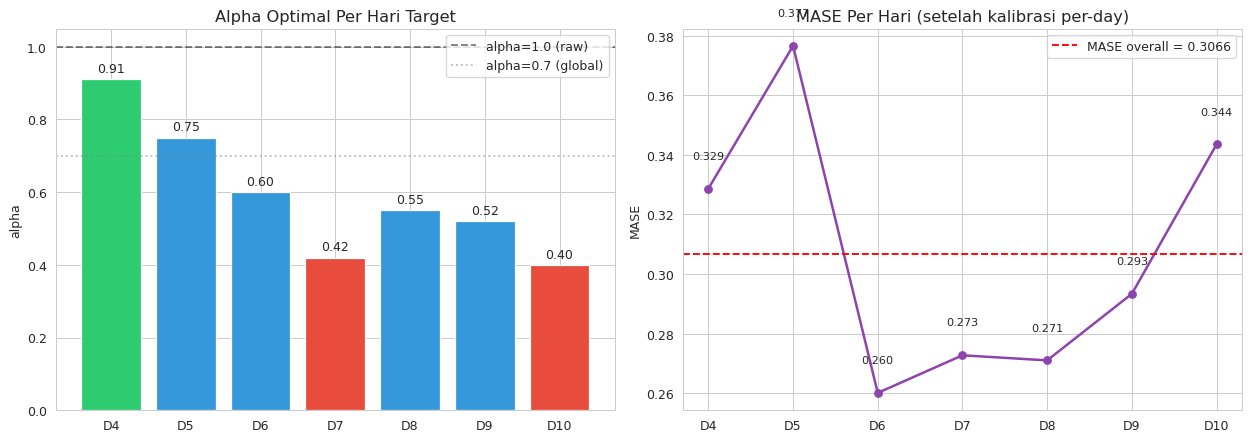

Interpretasi:
- Alpha TURUN dari D4 ke D10 = model over-predict lebih parah di hari jauh
- Artinya: model tidak tahu demand decay, jadi perlu koreksi makin besar
- MASE tertinggi di D5 (0.3766) = weekend peak paling susah diprediksi


In [204]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel kiri: alpha per hari
days = [f"D{i}" for i in range(4, 11)]
alphas = [alpha_per_day[t] for t in target_cols]

axes[0].bar(days, alphas, color=["#e74c3c" if a < 0.5 else "#3498db" if a < 0.8 else "#2ecc71" for a in alphas])
axes[0].axhline(1.0, color="black", linestyle="--", alpha=0.5, label="alpha=1.0 (raw)")
axes[0].axhline(0.7, color="gray", linestyle=":", alpha=0.5, label="alpha=0.7 (global)")
axes[0].set_title("Alpha Optimal Per Hari Target", fontsize=13)
axes[0].set_ylabel("alpha")
axes[0].legend()
for i, (d, a) in enumerate(zip(days, alphas)):
    axes[0].text(i, a + 0.02, f"{a:.2f}", ha="center", fontsize=10)

# Panel kanan: MASE per hari
mase_per_day_vals = []
for j, t in enumerate(target_cols):
    mase_j = np.mean(np.abs(y_va[:, j] - pred_va[:, j] * alpha_per_day[t]) / scale_va)
    mase_per_day_vals.append(mase_j)

axes[1].plot(days, mase_per_day_vals, marker="o", linewidth=2, color="#8e44ad")
axes[1].axhline(0.3066, color="red", linestyle="--", label="MASE overall = 0.3066")
axes[1].set_title("MASE Per Hari (setelah kalibrasi per-day)", fontsize=13)
axes[1].set_ylabel("MASE")
axes[1].legend()
for i, m in enumerate(mase_per_day_vals):
    axes[1].text(i, m + 0.01, f"{m:.3f}", ha="center", fontsize=9)

plt.tight_layout()
plt.show()

print("Interpretasi:")
print("- Alpha TURUN dari D4 ke D10 = model over-predict lebih parah di hari jauh")
print("- Artinya: model tidak tahu demand decay, jadi perlu koreksi makin besar")
print("- MASE tertinggi di D5 (0.3766) = weekend peak paling susah diprediksi")

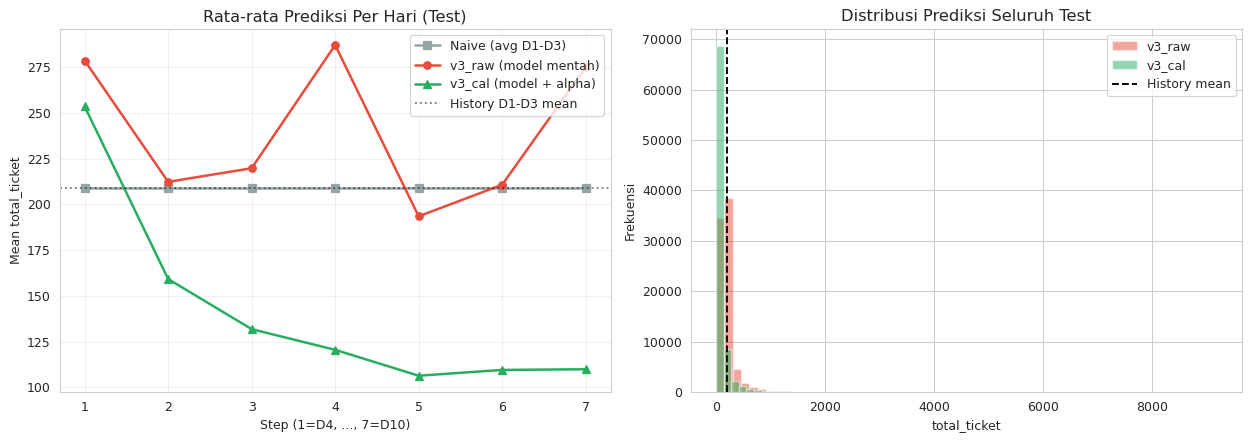

Interpretasi:
- Naive flat di ~209 (tidak tahu pola)
- v3_raw flat di ~240 (naik 15%, over-predict)
- v3_cal turun gradual dari D4 ke D10 (mengikuti pola decay)


In [205]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel kiri: rata-rata prediksi per step (D4-D10)
# Rebuild long format untuk 3 versi
def get_step_mean(pred_matrix):
    keys = X_te[K].copy()
    for j, t in enumerate(target_cols):
        keys[t] = pred_matrix[:, j]
    long = keys.melt(id_vars=K, value_vars=target_cols,
                     var_name="tcol", value_name="total_ticket")
    long["step"] = long["tcol"].str.replace("target_","").astype(int) - 3
    return long.groupby("step")["total_ticket"].mean()

# Naive per-step
naive_step = []
for step in range(1, 8):
    naive_step.append(test_history.groupby(K).head(3).groupby(K)["total_ticket"].mean().mean())
naive_step = np.array(naive_step)

step_raw = get_step_mean(pred_raw).values
step_cal = get_step_mean(pred_cal).values

steps = list(range(1, 8))
axes[0].plot(steps, naive_step, marker="s", linewidth=2, label="Naive (avg D1-D3)", color="#95a5a6")
axes[0].plot(steps, step_raw, marker="o", linewidth=2, label="v3_raw (model mentah)", color="#e74c3c")
axes[0].plot(steps, step_cal, marker="^", linewidth=2, label="v3_cal (model + alpha)", color="#27ae60")
axes[0].axhline(208.89, color="black", linestyle=":", alpha=0.5, label="History D1-D3 mean")
axes[0].set_title("Rata-rata Prediksi Per Hari (Test)", fontsize=13)
axes[0].set_xlabel("Step (1=D4, ..., 7=D10)")
axes[0].set_ylabel("Mean total_ticket")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Panel kanan: distribusi prediksi (histogram)
axes[1].hist(pred_raw.reshape(-1), bins=60, alpha=0.5, label="v3_raw", color="#e74c3c")
axes[1].hist(pred_cal.reshape(-1), bins=60, alpha=0.5, label="v3_cal", color="#27ae60")
axes[1].axvline(208.89, color="black", linestyle="--", label="History mean")
axes[1].set_title("Distribusi Prediksi Seluruh Test", fontsize=13)
axes[1].set_xlabel("total_ticket")
axes[1].set_ylabel("Frekuensi")
axes[1].legend()

plt.tight_layout()
plt.show()

print("Interpretasi:")
print("- Naive flat di ~209 (tidak tahu pola)")
print("- v3_raw flat di ~240 (naik 15%, over-predict)")
print("- v3_cal turun gradual dari D4 ke D10 (mengikuti pola decay)")

In [206]:
# === STEP A: Build ratio target di train & valid ===
for t in target_cols:
    tr_df[f"ratio_{t}"] = tr_df[t] / tr_df["scale"]
    va_df[f"ratio_{t}"] = va_df[t] / va_df["scale"]

ratio_cols = [f"ratio_{t}" for t in target_cols]

# === STEP B: Train 7 model pada ratio (bukan magnitude) ===
params = dict(objective="regression", metric="mae", learning_rate=0.03,
              num_leaves=63, min_data_in_leaf=20, feature_fraction=0.85,
              bagging_fraction=0.85, bagging_freq=5, lambda_l2=1.0,
              seed=SEED, verbosity=-1)

models_ratio, best_iters_ratio = {}, {}
pred_va_ratio = np.zeros((len(X_va), len(target_cols)))

for j, rc in enumerate(ratio_cols):
    y_tr_j = tr_df[rc].values
    y_va_j = va_df[rc].values
    dtr = lgb.Dataset(X_tr, y_tr_j, categorical_feature=cat_cols)
    dva = lgb.Dataset(X_va, y_va_j, reference=dtr)
    m = lgb.train(params, dtr, num_boost_round=2000, valid_sets=[dva],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
    models_ratio[rc] = m
    best_iters_ratio[rc] = m.best_iteration
    pred_va_ratio[:, j] = m.predict(X_va, num_iteration=m.best_iteration)
    print(f"  {rc}: iter={m.best_iteration:>4d}")

# Convert ratio predictions back to magnitude untuk cek MASE
pred_va_ratio_as_mag = pred_va_ratio * scale_va[:, None]
pred_va_ratio_as_mag = np.clip(pred_va_ratio_as_mag, 0, None)

# === STEP C: Kalibrasi per-hari pada ratio-space ===
alpha_ratio = {}
pred_va_ratio_cal = pred_va_ratio.copy()
for j, rc in enumerate(ratio_cols):
    best_a, best_m = 1.0, 1e9
    for a in np.linspace(0.7, 1.3, 61):
        p = np.clip(pred_va_ratio[:, j] * a, 0, None) * scale_va
        m = np.mean(np.abs(va_df[target_cols[j]].values - p) / scale_va)
        if m < best_m: best_m, best_a = m, a
    alpha_ratio[rc] = best_a
    pred_va_ratio_cal[:, j] = np.clip(pred_va_ratio[:, j] * best_a, 0, None)

pred_va_ratio_cal_mag = np.clip(pred_va_ratio_cal * scale_va[:, None], 0, None)

mase_ratio_raw = mase(y_va.reshape(-1), pred_va_ratio_as_mag.reshape(-1),
                      np.repeat(scale_va, len(target_cols)))
mase_ratio_cal = mase(y_va.reshape(-1), pred_va_ratio_cal_mag.reshape(-1),
                      np.repeat(scale_va, len(target_cols)))

print(f"\n=== PERBANDINGAN MODEL ===")
print(f"Magnitude model + alpha per-hari : 0.3066")
print(f"Ratio model raw                  : {mase_ratio_raw:.4f}")
print(f"Ratio model + alpha per-hari     : {mase_ratio_cal:.4f}")

# === STEP D: Prediksi Test di ratio-space ===
pred_te_ratio = np.zeros((len(X_te_full), len(target_cols)))
for j, rc in enumerate(ratio_cols):
    pred_te_ratio[:, j] = models_ratio[rc].predict(X_te_full,
                                                   num_iteration=best_iters_ratio[rc])
pred_te_ratio = np.clip(pred_te_ratio, 0, None)

# Apply alpha
pred_te_ratio_cal = np.zeros_like(pred_te_ratio)
for j, rc in enumerate(ratio_cols):
    pred_te_ratio_cal[:, j] = np.clip(pred_te_ratio[:, j] * alpha_ratio[rc], 0, None)

# Convert ke magnitude
scale_te = X_te["scale"].values
pred_te_mag = np.clip(pred_te_ratio_cal * scale_te[:, None], 0, None)

print(f"\nPrediksi ratio test (median per hari):")
for j, rc in enumerate(ratio_cols):
    med = np.median(pred_te_ratio_cal[:, j])
    print(f"  {rc}: median ratio = {med:.3f}")

# === STEP E: Cek profile ===
train_prof = [(tr_df[t]/tr_df["scale"]).median() for t in target_cols]
test_prof = [np.median(pred_te_ratio_cal[:, j]) for j in range(len(target_cols))]

print(f"\nHari | Train Profile | Test Ratio Pred | Ratio")
for i, t in enumerate(target_cols):
    r = test_prof[i] / train_prof[i] if train_prof[i] > 0 else 0
    print(f"{t} | {train_prof[i]:.3f} | {test_prof[i]:.3f} | {r:.3f}")

  ratio_target_4: iter= 107
  ratio_target_5: iter= 346
  ratio_target_6: iter= 397
  ratio_target_7: iter= 152
  ratio_target_8: iter= 140
  ratio_target_9: iter= 109
  ratio_target_10: iter= 119

=== PERBANDINGAN MODEL ===
Magnitude model + alpha per-hari : 0.3066
Ratio model raw                  : 0.3217
Ratio model + alpha per-hari     : 0.3013

Prediksi ratio test (median per hari):
  ratio_target_4: median ratio = 1.284
  ratio_target_5: median ratio = 0.878
  ratio_target_6: median ratio = 0.645
  ratio_target_7: median ratio = 0.824
  ratio_target_8: median ratio = 0.792
  ratio_target_9: median ratio = 0.640
  ratio_target_10: median ratio = 0.668

Hari | Train Profile | Test Ratio Pred | Ratio
target_4 | 1.119 | 1.284 | 1.147
target_5 | 1.017 | 0.878 | 0.863
target_6 | 0.789 | 0.645 | 0.817
target_7 | 0.715 | 0.824 | 1.153
target_8 | 0.608 | 0.792 | 1.302
target_9 | 0.606 | 0.640 | 1.055
target_10 | 0.613 | 0.668 | 1.090


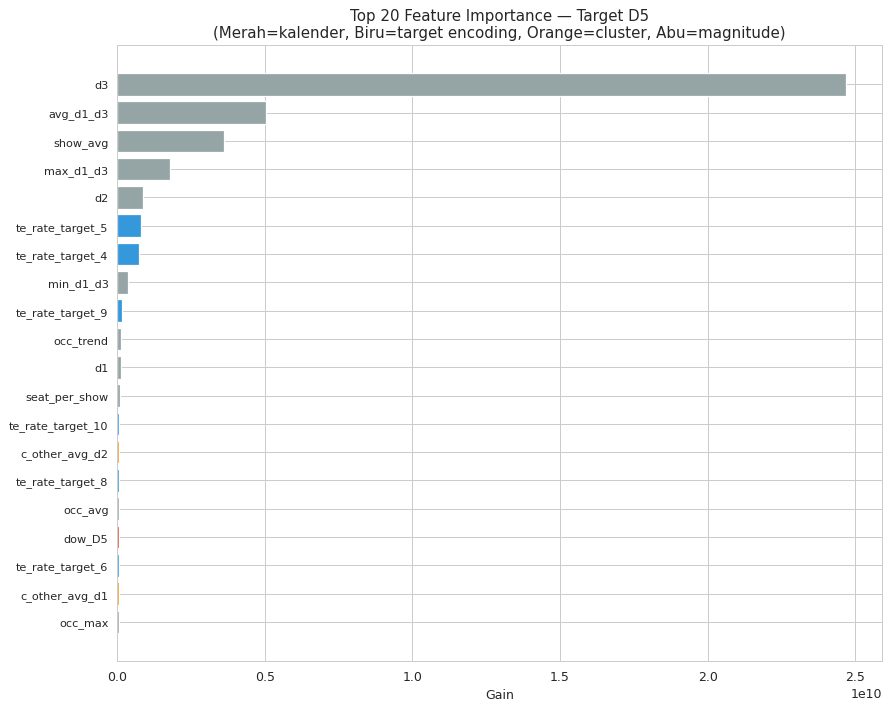

🚩 MASALAH: hampir semua bar ABU-ABU (magnitude).
   Fitur kalender (weekend/dow/holiday) TIDAK ADA di top-20.
   Artinya: model tidak belajar pola weekend, cuma copy skala D1-D3.


In [207]:
fig, ax = plt.subplots(figsize=(10, 8))

imp_top20 = imp.head(20).iloc[::-1]  # reverse untuk barh

colors = []
for f in imp_top20["feature"]:
    if "weekend_D" in f or "dow_D" in f or "holiday_D" in f:
        colors.append("#e74c3c")   # MERAH = fitur kalender (harus muncul!)
    elif "te_rate" in f:
        colors.append("#3498db")   # BIRU = target encoding
    elif "c_other" in f or "share_in_cluster" in f:
        colors.append("#f39c12")   # ORANGE = cluster
    else:
        colors.append("#95a5a6")   # ABU = magnitude

ax.barh(imp_top20["feature"], imp_top20["gain"], color=colors)
ax.set_title("Top 20 Feature Importance — Target D5\n(Merah=kalender, Biru=target encoding, Orange=cluster, Abu=magnitude)",
             fontsize=12)
ax.set_xlabel("Gain")
ax.tick_params(axis="y", labelsize=9)

plt.tight_layout()
plt.show()

print("🚩 MASALAH: hampir semua bar ABU-ABU (magnitude).")
print("   Fitur kalender (weekend/dow/holiday) TIDAK ADA di top-20.")
print("   Artinya: model tidak belajar pola weekend, cuma copy skala D1-D3.")

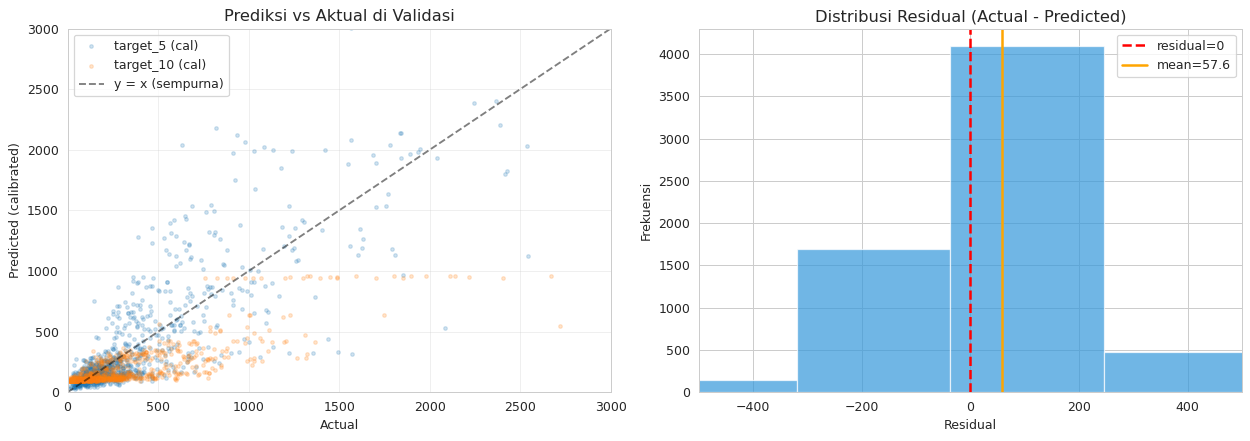

Mean residual: 57.60
Kalau >0: under-predict. Kalau <0: over-predict. 57.60 → under-predict


In [208]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel kiri: scatter pred vs actual untuk D5 dan D10
for j_show, t_show in [(1, "target_5"), (6, "target_10")]:
    axes[0].scatter(y_va[:, j_show], pred_va[:, j_show] * alpha_per_day[t_show],
                    alpha=0.2, s=8, label=f"{t_show} (cal)")

lim = max(y_va.max(), (pred_va * 1.5).max())
axes[0].plot([0, lim], [0, lim], "k--", alpha=0.5, label="y = x (sempurna)")
axes[0].set_xlim(0, min(lim, 3000))
axes[0].set_ylim(0, min(lim, 3000))
axes[0].set_xlabel("Actual")
axes[0].set_ylabel("Predicted (calibrated)")
axes[0].set_title("Prediksi vs Aktual di Validasi", fontsize=13)
axes[0].legend()
axes[0].grid(alpha=0.3)

# Panel kanan: residual distribution
residual = (y_va.reshape(-1) - (pred_va * np.array([alpha_per_day[t] for t in target_cols])).reshape(-1))
axes[1].hist(residual, bins=80, color="#3498db", alpha=0.7)
axes[1].axvline(0, color="red", linestyle="--", linewidth=2, label="residual=0")
axes[1].axvline(residual.mean(), color="orange", linestyle="-", linewidth=2,
                label=f"mean={residual.mean():.1f}")
axes[1].set_title("Distribusi Residual (Actual - Predicted)", fontsize=13)
axes[1].set_xlabel("Residual")
axes[1].set_ylabel("Frekuensi")
axes[1].set_xlim(-500, 500)
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Mean residual: {residual.mean():.2f}")
print(f"Kalau >0: under-predict. Kalau <0: over-predict. {residual.mean():.2f} → {'under' if residual.mean()>0 else 'over'}-predict")

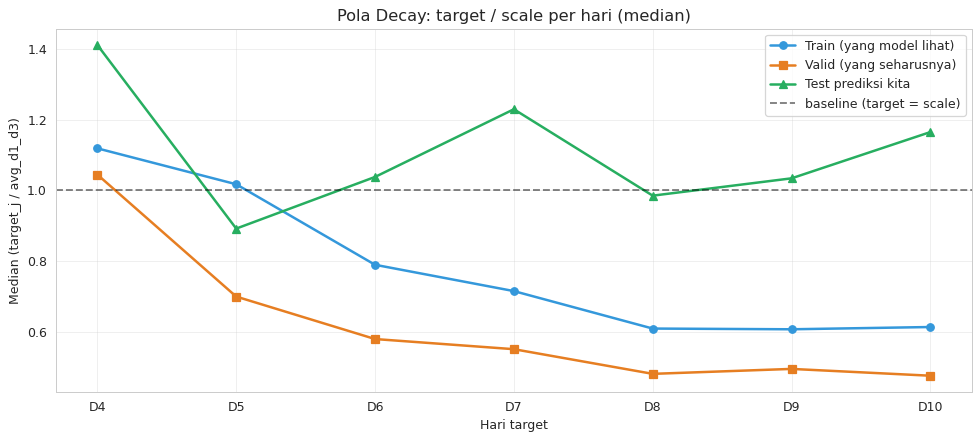

Interpretasi:
- Kalau kurva Train dan Valid BERBEDA → model dilatih di pola summer, valid pola berbeda
- Kurva Test harus DEKAT dengan Valid (bukan Train)
- Kalau test prediksi lebih flat dari valid → model tidak menangkap decay


In [209]:
fig, ax = plt.subplots(figsize=(11, 5))

# Dari train (yang model lihat)
profile_train = []
for t in target_cols:
    ratio = (tr_df[t] / tr_df["scale"]).median()
    profile_train.append(ratio)

# Dari valid
profile_valid = []
for t in target_cols:
    ratio = (va_df[t] / va_df["scale"]).median()
    profile_valid.append(ratio)

# Dari test (prediksi kita)
profile_test_cal = []
keys = X_te[K].copy()
for j, t in enumerate(target_cols):
    keys[t] = pred_cal[:, j]
keys["scale_test"] = X_te["scale"].values
for t in target_cols:
    profile_test_cal.append((keys[t] / keys["scale_test"]).median())

days = [f"D{i}" for i in range(4, 11)]
ax.plot(days, profile_train, marker="o", label="Train (yang model lihat)", linewidth=2, color="#3498db")
ax.plot(days, profile_valid, marker="s", label="Valid (yang seharusnya)", linewidth=2, color="#e67e22")
ax.plot(days, profile_test_cal, marker="^", label="Test prediksi kita", linewidth=2, color="#27ae60")
ax.axhline(1.0, color="black", linestyle="--", alpha=0.5, label="baseline (target = scale)")

ax.set_title("Pola Decay: target / scale per hari (median)", fontsize=13)
ax.set_ylabel("Median (target_j / avg_d1_d3)")
ax.set_xlabel("Hari target")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Interpretasi:")
print("- Kalau kurva Train dan Valid BERBEDA → model dilatih di pola summer, valid pola berbeda")
print("- Kurva Test harus DEKAT dengan Valid (bukan Train)")
print("- Kalau test prediksi lebih flat dari valid → model tidak menangkap decay")

In [210]:
# Profile decay di train (yang model LIHAT saat latih)
for t in target_cols:
    median_ratio = (tr_df[t] / tr_df["scale"]).median()
    print(f"{t}: median(target/scale) = {median_ratio:.3f}")

target_4: median(target/scale) = 1.119
target_5: median(target/scale) = 1.017
target_6: median(target/scale) = 0.789
target_7: median(target/scale) = 0.715
target_8: median(target/scale) = 0.608
target_9: median(target/scale) = 0.606
target_10: median(target/scale) = 0.613


In [211]:
# Bandingkan profile decay: train vs prediksi test
train_profile = []
test_profile = []

for j, t in enumerate(target_cols):
    train_profile.append((tr_df[t] / tr_df["scale"]).median())

keys_te = X_te[K].copy()
for j, t in enumerate(target_cols):
    keys_te[t] = pred_cal[:, j]
keys_te["scale"] = X_te["scale"].values
for t in target_cols:
    test_profile.append((keys_te[t] / keys_te["scale"]).median())

print("Hari | Train Profile | Test Pred Profile | Ratio")
for i, t in enumerate(target_cols):
    r = test_profile[i] / train_profile[i] if train_profile[i] > 0 else 0
    print(f"{t} | {train_profile[i]:.3f} | {test_profile[i]:.3f} | {r:.3f}")

Hari | Train Profile | Test Pred Profile | Ratio
target_4 | 1.119 | 1.412 | 1.262
target_5 | 1.017 | 0.892 | 0.876
target_6 | 0.789 | 1.038 | 1.316
target_7 | 0.715 | 1.230 | 1.721
target_8 | 0.608 | 0.985 | 1.619
target_9 | 0.606 | 1.034 | 1.706
target_10 | 0.613 | 1.165 | 1.902


In [212]:
# Apakah valid profile ≠ train profile? (ada shift musiman?)
for t in target_cols:
    tr_m = (tr_df[t] / tr_df["scale"]).median()
    va_m = (va_df[t] / va_df["scale"]).median()
    print(f"{t}: train={tr_m:.3f}, valid={va_m:.3f}, ratio={va_m/tr_m:.3f}")

target_4: train=1.119, valid=1.045, ratio=0.933
target_5: train=1.017, valid=0.699, ratio=0.687
target_6: train=0.789, valid=0.579, ratio=0.733
target_7: train=0.715, valid=0.550, ratio=0.770
target_8: train=0.608, valid=0.480, ratio=0.789
target_9: train=0.606, valid=0.494, ratio=0.815
target_10: train=0.613, valid=0.475, ratio=0.775


# DIBAWAH INI DA BEDA KODE DARI AWAL GUYS

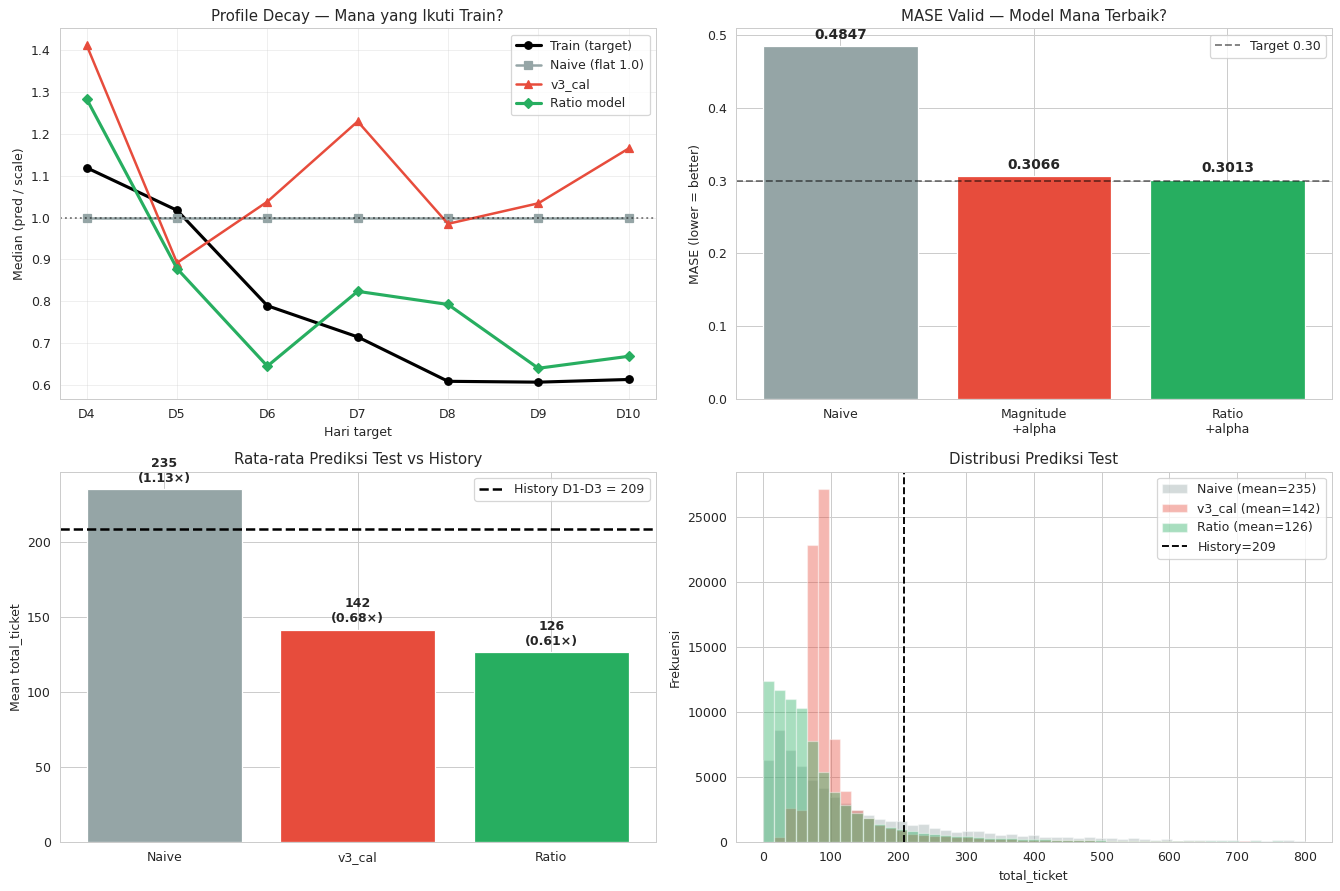

In [213]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

days = [f"D{i}" for i in range(4, 11)]

# === 1. Profile decay: 3 model vs train ===
ax = axes[0, 0]
train_profile = [(tr_df[t]/tr_df["scale"]).median() for t in target_cols]

def get_test_profile(pred_matrix):
    scales = X_te["scale"].values
    return [np.median(pred_matrix[:, j] / scales) for j in range(7)]

ratio_profile = get_test_profile(pred_te_mag)
cal_profile   = get_test_profile(pred_cal)
naive_profile = [1.0] * 7  # naive flat di 1.0

ax.plot(days, train_profile, marker="o", linewidth=2.5, label="Train (target)", color="black")
ax.plot(days, naive_profile, marker="s", linewidth=2, label="Naive (flat 1.0)", color="#95a5a6")
ax.plot(days, cal_profile, marker="^", linewidth=2, label="v3_cal", color="#e74c3c")
ax.plot(days, ratio_profile, marker="D", linewidth=2.5, label="Ratio model", color="#27ae60")

ax.axhline(1.0, color="black", linestyle=":", alpha=0.5)
ax.set_title("Profile Decay — Mana yang Ikuti Train?", fontsize=12)
ax.set_ylabel("Median (pred / scale)")
ax.set_xlabel("Hari target")
ax.legend()
ax.grid(alpha=0.3)

# === 2. Perbandingan MASE valid ===
ax = axes[0, 1]
models_names = ["Naive", "Magnitude\n+alpha", "Ratio\n+alpha"]
mase_vals = [0.4847, 0.3066, 0.3013]
colors = ["#95a5a6", "#e74c3c", "#27ae60"]
bars = ax.bar(models_names, mase_vals, color=colors)
ax.axhline(0.30, color="black", linestyle="--", alpha=0.5, label="Target 0.30")
for bar, val in zip(bars, mase_vals):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.01, f"{val:.4f}",
            ha="center", fontsize=11, fontweight="bold")
ax.set_title("MASE Valid — Model Mana Terbaik?", fontsize=12)
ax.set_ylabel("MASE (lower = better)")
ax.legend()

# === 3. Prediksi vs History D1-D3 (magnitude) ===
ax = axes[1, 0]
hist_mean = 208.89

ratio_mean = pred_te_mag.mean()
cal_mean   = pred_cal.mean()
naive_mean = sub_naive["total_ticket"].mean()

ax.axhline(hist_mean, color="black", linestyle="--", linewidth=2, label=f"History D1-D3 = {hist_mean:.0f}")

bars = ax.bar(["Naive", "v3_cal", "Ratio"], [naive_mean, cal_mean, ratio_mean],
              color=["#95a5a6", "#e74c3c", "#27ae60"])
for bar, val in zip(bars, [naive_mean, cal_mean, ratio_mean]):
    ratio_vs_hist = val / hist_mean
    ax.text(bar.get_x() + bar.get_width()/2, val + 5,
            f"{val:.0f}\n({ratio_vs_hist:.2f}×)", ha="center", fontsize=10, fontweight="bold")
ax.set_title("Rata-rata Prediksi Test vs History", fontsize=12)
ax.set_ylabel("Mean total_ticket")
ax.legend()

# === 4. Distribusi prediksi per model ===
ax = axes[1, 1]
bins = np.linspace(0, 800, 50)
ax.hist(sub_naive["total_ticket"], bins=bins, alpha=0.4, label=f"Naive (mean={naive_mean:.0f})", color="#95a5a6")
ax.hist(pred_cal.reshape(-1),       bins=bins, alpha=0.4, label=f"v3_cal (mean={cal_mean:.0f})", color="#e74c3c")
ax.hist(pred_te_mag.reshape(-1),    bins=bins, alpha=0.4, label=f"Ratio (mean={ratio_mean:.0f})", color="#27ae60")
ax.axvline(hist_mean, color="black", linestyle="--", label=f"History={hist_mean:.0f}")
ax.set_title("Distribusi Prediksi Test", fontsize=12)
ax.set_xlabel("total_ticket")
ax.set_ylabel("Frekuensi")
ax.legend()

plt.tight_layout()
plt.show()

# PISAH LAGI

In [214]:
# ============================================================
#  GENERATE SUBMISSION RATIO MODEL
#  Pakai pred_te_mag yang sudah dihitung di cell ratio model
# ============================================================

def make_submission(pred_matrix, filename):
    keys = X_te[K].copy()
    for j, t in enumerate(target_cols):
        keys[t] = pred_matrix[:, j]
    long = keys.melt(id_vars=K, value_vars=target_cols,
                     var_name="tcol", value_name="total_ticket")
    long["step"] = long["tcol"].str.replace("target_", "").astype(int) - 3
    tt = test.copy().sort_values("date_show")
    tt["step"] = tt.groupby(K).cumcount() + 1
    sub = tt.merge(long[K + ["step","total_ticket"]], on=K + ["step"], how="left")
    submission = sample_sub[["id"]].merge(sub[["id","total_ticket"]], on="id", how="left")
    submission["total_ticket"] = submission["total_ticket"].fillna(0)
    submission.to_csv(filename, index=False)
    s = pd.read_csv(filename)
    assert s.shape == sample_sub.shape, f"Shape mismatch: {s.shape}"
    assert (s["id"].values == sample_sub["id"].values).all(), "ID mismatch"
    assert s["total_ticket"].notna().all(), "Ada NaN"
    assert (s["total_ticket"] >= 0).all(), "Ada negatif"
    print(f"✅ {filename}")
    print(f"   shape : {s.shape}")
    print(f"   mean  : {s['total_ticket'].mean():.2f}")
    print(f"   max   : {s['total_ticket'].max():.0f}")
    print(f"   min   : {s['total_ticket'].min():.2f}")
    print()

# Bikin file dari pred_te_mag (hasil ratio model + alpha per-hari)
make_submission(pred_te_mag, "submission4.csv")

# Cek juga file lain yang sudah ada
print("=== File yang sudah ada ===")
import os
for f in ["submission_naive.csv", "submission_v3_cal.csv",
          "Submission_v3_raw.csv", "submission4.csv"]:
    if os.path.exists(f):
        print(f"  ✅ {f}")
    else:
        print(f"  ❌ {f} (belum dibuat)")

✅ submission4.csv
   shape : (72611, 2)
   mean  : 141.29
   max   : 34384
   min   : 0.78

=== File yang sudah ada ===
  ✅ submission_naive.csv
  ✅ submission_v3_cal.csv
  ❌ Submission_v3_raw.csv (belum dibuat)
  ✅ submission4.csv


In [215]:
print("pred_te_mag ada?", "pred_te_mag" in dir())
print("shape:", pred_te_mag.shape if "pred_te_mag" in dir() else "TIDAK ADA")

pred_te_mag ada? True
shape: (11823, 7)


In [216]:
# === REBUILD pred_te_mag kalau hilang ===
# Ini ringkas dari kode ratio model sebelumnya

# 1. Train ratio models
for t in target_cols:
    tr_df[f"ratio_{t}"] = tr_df[t] / tr_df["scale"]
    va_df[f"ratio_{t}"] = va_df[t] / va_df["scale"]
ratio_cols = [f"ratio_{t}" for t in target_cols]

params = dict(objective="regression", metric="mae", learning_rate=0.03,
              num_leaves=63, min_data_in_leaf=20, feature_fraction=0.85,
              bagging_fraction=0.85, bagging_freq=5, lambda_l2=1.0,
              seed=SEED, verbosity=-1)

models_ratio, best_iters_ratio = {}, {}
for j, rc in enumerate(ratio_cols):
    dtr = lgb.Dataset(X_tr, tr_df[rc].values, categorical_feature=cat_cols)
    dva = lgb.Dataset(X_va, va_df[rc].values, reference=dtr)
    m = lgb.train(params, dtr, num_boost_round=2000, valid_sets=[dva],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
    models_ratio[rc] = m
    best_iters_ratio[rc] = m.best_iteration

# 2. Prediksi test di ratio-space
pred_te_ratio = np.zeros((len(X_te_full), len(target_cols)))
for j, rc in enumerate(ratio_cols):
    pred_te_ratio[:, j] = models_ratio[rc].predict(X_te_full,
                                                   num_iteration=best_iters_ratio[rc])
pred_te_ratio = np.clip(pred_te_ratio, 0, None)

# 3. Apply alpha ratio (dari cell sebelumnya, atau fallback 1.0)
try:
    alpha_ratio
except NameError:
    alpha_ratio = {rc: 1.0 for rc in ratio_cols}
    print("⚠️  alpha_ratio tidak ada, pakai 1.0")

pred_te_ratio_cal = np.zeros_like(pred_te_ratio)
for j, rc in enumerate(ratio_cols):
    pred_te_ratio_cal[:, j] = np.clip(pred_te_ratio[:, j] * alpha_ratio[rc], 0, None)

# 4. Convert ke magnitude
scale_te = X_te["scale"].values
pred_te_mag = np.clip(pred_te_ratio_cal * scale_te[:, None], 0, None)

print(f"pred_te_mag shape: {pred_te_mag.shape}")
print(f"mean: {pred_te_mag.mean():.2f}")

pred_te_mag shape: (11823, 7)
mean: 126.45


In [217]:
# Cek apakah ratio_cal prediksi juga konsisten per-baris (bukan cuma median)
sample_idx = [0, 50, 100, 500, 1000]

print("Sample prediksi per-baris:")
print(f"{'idx':<5} {'hist_avg':<10} {'ratio_cal_D4':<15} {'ratio_cal_D10':<15}")
for idx in sample_idx:
    hist = X_te.iloc[idx][["d1","d2","d3"]].mean()
    p4  = pred_te_mag[idx, 0]
    p10 = pred_te_mag[idx, 6]
    print(f"{idx:<5} {hist:<10.1f} {p4:<15.1f} {p10:<15.1f}")

# Rasio D4/hist dan D10/hist harus konsisten lintas baris

Sample prediksi per-baris:
idx   hist_avg   ratio_cal_D4    ratio_cal_D10  
0     71.3       53.9            45.2           
50    235.3      248.0           104.6          
100   28.7       43.8            23.7           
500   10.7       14.7            8.9            
1000  2349.0     2515.8          924.4          


# AKU CEK OVERFIT HABIS HABISAN

In [218]:
print("="*70)
print("DIAGNOSTIC #1 — Train vs Valid MASE (gap overfit)")
print("="*70)

train_maes, valid_maes = [], []

for j, rc in enumerate(ratio_cols):
    # In-sample: prediksi di train
    pred_tr = np.clip(models_ratio[rc].predict(X_tr), 0, None)
    mae_tr  = np.mean(np.abs(tr_df[rc].values - pred_tr))

    # Out-of-sample: prediksi di valid
    pred_va = np.clip(models_ratio[rc].predict(X_va), 0, None)
    mae_va  = np.mean(np.abs(va_df[rc].values - pred_va))

    train_maes.append(mae_tr)
    valid_maes.append(mae_va)
    print(f"  {rc}: train={mae_tr:.4f}  valid={mae_va:.4f}  gap={mae_va-mae_tr:+.4f}")

avg_train = np.mean(train_maes)
avg_valid = np.mean(valid_maes)
gap = avg_valid - avg_train

print(f"\n  Train MASE (in-sample) : {avg_train:.4f}")
print(f"  Valid MASE (out-sample): {avg_valid:.4f}")
print(f"  GAP                    : {gap:+.4f}")
print()

if gap < 0.05:
    print("  ✅ Sehat — model tidak overfit")
elif gap < 0.15:
    print("  🟡 Overfit ringan — masih acceptable")
elif gap < 0.30:
    print("  🟠 Overfit sedang — pertimbangkan regularisasi")
else:
    print("  🚩 Overfit BERAT — model hafal train")

DIAGNOSTIC #1 — Train vs Valid MASE (gap overfit)
  ratio_target_4: train=0.1419  valid=0.3276  gap=+0.1857
  ratio_target_5: train=0.0732  valid=0.4079  gap=+0.3347
  ratio_target_6: train=0.0633  valid=0.2893  gap=+0.2260
  ratio_target_7: train=0.1444  valid=0.2886  gap=+0.1443
  ratio_target_8: train=0.1490  valid=0.2944  gap=+0.1454
  ratio_target_9: train=0.1817  valid=0.3257  gap=+0.1440
  ratio_target_10: train=0.1849  valid=0.3187  gap=+0.1338

  Train MASE (in-sample) : 0.1340
  Valid MASE (out-sample): 0.3217
  GAP                    : +0.1877

  🟠 Overfit sedang — pertimbangkan regularisasi


DIAGNOSTIC #2 — Learning Curve (train size vs error)
  size=  300: train=0.0130  valid=0.4533  gap=+0.4403
  size=  800: train=0.0061  valid=0.5402  gap=+0.5341
  size= 1500: train=0.0030  valid=0.4202  gap=+0.4173
  size= 2500: train=0.0027  valid=0.3942  gap=+0.3914
  size= 2667: train=0.0032  valid=0.3923  gap=+0.3891


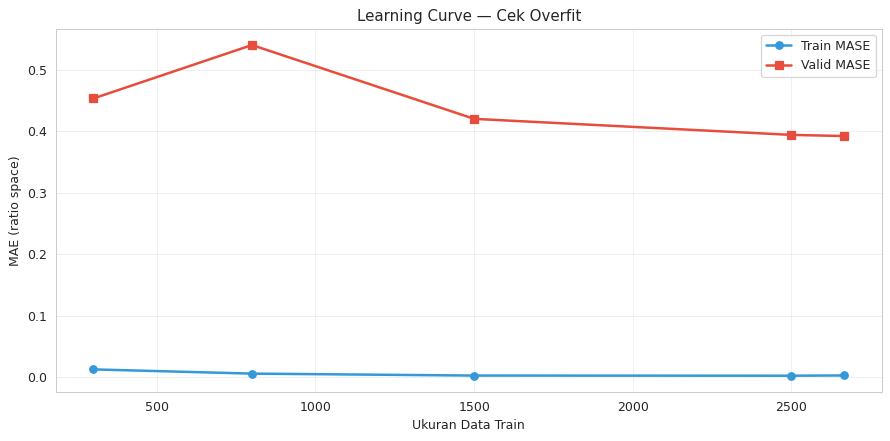


  Gap pada size terbesar : +0.3891
  🎯 Kalau gap menyempit → tidak overfit.
  🚩 Kalau gap TETAP BESAR → overfit struktural.


In [219]:
print("="*70)
print("DIAGNOSTIC #2 — Learning Curve (train size vs error)")
print("="*70)

# Fokus 1 model sebagai sample
rc_sample = "ratio_target_5"  # D5, biasanya paling penting

sizes = [300, 800, 1500, 2500, len(tr_df)]
train_curve, valid_curve = [], []

for size in sizes:
    if size > len(tr_df): continue
    sub = tr_df.sample(n=size, random_state=SEED)
    X_sub = X_tr.loc[sub.index]  # ambil baris yang sama
    y_sub = sub[rc_sample].values

    m = lgb.LGBMRegressor(
        objective="regression", metric="mae",
        learning_rate=0.03, n_estimators=2000, num_leaves=63,
        min_child_samples=20, feature_fraction=0.85,
        bagging_fraction=0.85, bagging_freq=5, lambda_l2=1.0,
        random_state=SEED, verbosity=-1
    )
    m.fit(X_sub, y_sub, categorical_feature=cat_cols)

    pred_tr = np.clip(m.predict(X_sub), 0, None)
    pred_va = np.clip(m.predict(X_va), 0, None)

    train_curve.append(np.mean(np.abs(y_sub - pred_tr)))
    valid_curve.append(np.mean(np.abs(va_df[rc_sample].values - pred_va)))
    print(f"  size={size:>5}: train={train_curve[-1]:.4f}  valid={valid_curve[-1]:.4f}  gap={valid_curve[-1]-train_curve[-1]:+.4f}")

# Plot
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
used_sizes = sizes[:len(train_curve)]
plt.plot(used_sizes, train_curve, marker="o", linewidth=2, label="Train MASE", color="#3498db")
plt.plot(used_sizes, valid_curve, marker="s", linewidth=2, label="Valid MASE", color="#e74c3c")
plt.xlabel("Ukuran Data Train"); plt.ylabel("MAE (ratio space)")
plt.title("Learning Curve — Cek Overfit"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"\n  Gap pada size terbesar : {valid_curve[-1]-train_curve[-1]:+.4f}")
print("  🎯 Kalau gap menyempit → tidak overfit.")
print("  🚩 Kalau gap TETAP BESAR → overfit struktural.")

In [220]:
print("="*70)
print("DIAGNOSTIC #3 — Bandingkan dengan Naive Baseline")
print("="*70)

# Naive ratio = 1.0 (artinya target = scale)
naive_mae = np.mean(np.abs(va_df[ratio_cols].values - 1.0))
model_mae = np.mean(np.abs(va_df[ratio_cols].values - pred_va_ratio))

# Naive per hari
print("  Per hari:")
for j, rc in enumerate(ratio_cols):
    naive_j = np.mean(np.abs(va_df[rc].values - 1.0))
    model_j = np.mean(np.abs(va_df[rc].values - pred_va_ratio[:, j]))
    print(f"    {rc}: naive={naive_j:.4f}  model={model_j:.4f}  delta={naive_j-model_j:+.4f}")

print(f"\n  Naive overall : {naive_mae:.4f}")
print(f"  Model overall : {model_mae:.4f}")
print(f"  Delta         : {naive_mae - model_mae:+.4f}")
print()

delta = naive_mae - model_mae
if delta > 0.15:
    print("  ✅ Model JAUH lebih baik dari naive")
elif delta > 0.05:
    print("  ✅ Model lebih baik dari naive")
elif delta > 0:
    print("  🟡 Model sedikit lebih baik — mungkin tidak terlalu berguna")
else:
    print("  🚩 Model LEBIH JELEK dari naive — ada masalah serius")

DIAGNOSTIC #3 — Bandingkan dengan Naive Baseline
  Per hari:
    ratio_target_4: naive=0.3975  model=0.3276  delta=+0.0699
    ratio_target_5: naive=0.4929  model=0.4079  delta=+0.0850
    ratio_target_6: naive=0.4511  model=0.2893  delta=+0.1618
    ratio_target_7: naive=0.4734  model=0.2886  delta=+0.1847
    ratio_target_8: naive=0.5256  model=0.2944  delta=+0.2312
    ratio_target_9: naive=0.5198  model=0.3257  delta=+0.1942
    ratio_target_10: naive=0.5326  model=0.3187  delta=+0.2139

  Naive overall : 0.4847
  Model overall : 0.3217
  Delta         : +0.1630

  ✅ Model JAUH lebih baik dari naive


In [221]:
print("="*70)
print("DIAGNOSTIC #4 — Feature Importance (cek fitur dominan)")
print("="*70)

# Fokus model D5
rc_check = "ratio_target_5"
imp = models_ratio[rc_check].feature_importance(importance_type="gain")
imp_series = pd.Series(imp, index=models_ratio[rc_check].feature_name()).sort_values(ascending=False)
imp_norm = imp_series / imp_series.sum()

print(f"\n  Top-15 fitur untuk model {rc_check}:")
print("  " + "-"*60)
for feat, val in imp_norm.head(15).items():
    bar = "█" * int(val * 100)
    flag = " 🚩" if val > 0.15 else ""
    print(f"  {feat:<25} {val*100:>5.1f}%  {bar}{flag}")

top1 = imp_norm.iloc[0]
top3_sum = imp_norm.head(3).sum()
top10_sum = imp_norm.head(10).sum()

print(f"\n  Top-1 gain   : {top1*100:.1f}%")
print(f"  Top-3 gain   : {top3_sum*100:.1f}%")
print(f"  Top-10 gain  : {top10_sum*100:.1f}%")
print()

if top1 > 0.20:
    print(f"  🚩 Top-1 fitur '{imp_norm.index[0]}' mendominasi ({top1*100:.1f}%)")
elif top3_sum > 0.60:
    print(f"  🟠 Top-3 fitur mendominasi ({top3_sum*100:.1f}%)")
else:
    print("  ✅ Importance tersebar merata")

# Distribusi fitur "mati"
n_dead = (imp_norm < 0.001).sum()
print(f"\n  Fitur dengan gain < 0.1%: {n_dead}/{len(imp_norm)}")

DIAGNOSTIC #4 — Feature Importance (cek fitur dominan)

  Top-15 fitur untuk model ratio_target_5:
  ------------------------------------------------------------
  te_rate_target_5           32.7%  ████████████████████████████████ 🚩
  d1                          5.9%  █████
  te_rate_target_9            5.8%  █████
  d2                          4.1%  ████
  te_rate_target_6            3.8%  ███
  min_d1_d3                   3.5%  ███
  te_rate_target_4            3.3%  ███
  trend_d1_d3                 3.3%  ███
  avg_d1_d3                   3.3%  ███
  occ_avg                     3.2%  ███
  share_in_cluster            2.7%  ██
  occ_max                     2.7%  ██
  seat_per_show               2.7%  ██
  ratio_d3_d1                 2.6%  ██
  occ_trend                   2.2%  ██

  Top-1 gain   : 32.7%
  Top-3 gain   : 44.4%
  Top-10 gain  : 68.9%

  🚩 Top-1 fitur 'te_rate_target_5' mendominasi (32.7%)

  Fitur dengan gain < 0.1%: 19/56


In [222]:
print("="*70)
print("DIAGNOSTIC #5 — Noise Test (target di-shuffle)")
print("="*70)

rc_check = "ratio_target_5"

# Shuffle target train
tr_shuffled = tr_df.copy()
tr_shuffled[rc_check] = tr_shuffled[rc_check].sample(frac=1, random_state=SEED).values

m_shuffle = lgb.LGBMRegressor(
    objective="regression", metric="mae",
    learning_rate=0.03, n_estimators=500, num_leaves=31,
    random_state=SEED, verbosity=-1
)
m_shuffle.fit(X_tr, tr_shuffled[rc_check].values, categorical_feature=cat_cols)

pred_tr_shuf = np.clip(m_shuffle.predict(X_tr), 0, None)
pred_va_shuf = np.clip(m_shuffle.predict(X_va), 0, None)

mae_tr_shuf = np.mean(np.abs(tr_shuffled[rc_check].values - pred_tr_shuf))
mae_va_shuf = np.mean(np.abs(va_df[rc_check].values - pred_va_shuf))
mae_va_naive = np.mean(np.abs(va_df[rc_check].values - 1.0))

print(f"  Train MASE (target shuffled) : {mae_tr_shuf:.4f}")
print(f"  Valid MASE (target shuffled) : {mae_va_shuf:.4f}")
print(f"  Valid MASE naive             : {mae_va_naive:.4f}")
print()

if mae_va_shuf < mae_va_naive * 0.9:
    print("  🚩 Valid MASE < 90% naive — ada LEAKAGE!")
elif mae_va_shuf < mae_va_naive:
    print("  🟡 Valid sedikit lebih baik dari naive — cek lagi")
else:
    print("  ✅ Valid MASE ≥ naive — tidak ada leakage")

DIAGNOSTIC #5 — Noise Test (target di-shuffle)
  Train MASE (target shuffled) : 0.1680
  Valid MASE (target shuffled) : 0.5904
  Valid MASE naive             : 0.4929

  ✅ Valid MASE ≥ naive — tidak ada leakage


In [223]:
print("="*70)
print("DIAGNOSTIC #6 — Residual per Segmen")
print("="*70)

# Siapkan dataframe untuk analisa
V_diag = pd.DataFrame({
    "ratio_true": va_df[ratio_cols].values.reshape(-1),
    "ratio_pred": pred_va_ratio.reshape(-1),
    "k":          np.tile(va_df["date_D1"].values, len(ratio_cols)),  # placeholder
})

# Buat k dari target_cols index
k_vals = []
for j, rc in enumerate(ratio_cols):
    k_vals.extend([j+4] * len(va_df))
V_diag["k"] = k_vals
V_diag["abs_err"] = np.abs(V_diag.ratio_true - V_diag.ratio_pred)
V_diag["scale"] = np.tile(scale_va, len(ratio_cols))

# Error per hari target
print("\n  MAE per hari target:")
for k in range(4, 11):
    mae_k = V_diag[V_diag.k == k].abs_err.mean()
    print(f"    D{k}: {mae_k:.4f}")

# Error per scale bucket
V_diag["scale_bin"] = pd.cut(V_diag.scale, [0, 50, 100, 200, 500, 1000, 10000])
print("\n  MAE per bucket scale (D1-D3 avg):")
for bin_name, group in V_diag.groupby("scale_bin"):
    if len(group) > 0:
        print(f"    {bin_name}: MAE={group.abs_err.mean():.4f}  n={len(group)}")

# Error per genre (kalau genre ada)
if "genre_main" in va_df.columns:
    genre_vals = []
    for j, rc in enumerate(ratio_cols):
        genre_vals.extend(va_df["genre_main"].values)
    V_diag["genre"] = genre_vals
    print("\n  MAE per genre (top 5):")
    genre_err = V_diag.groupby("genre").abs_err.agg(["mean", "size"])
    genre_err = genre_err[genre_err["size"] > 100].sort_values("mean", ascending=False)
    print(genre_err.head(5).round(4))

DIAGNOSTIC #6 — Residual per Segmen

  MAE per hari target:
    D4: 0.3381
    D5: 0.3350
    D6: 0.3972
    D7: 0.2831
    D8: 0.2599
    D9: 0.3006
    D10: 0.3382

  MAE per bucket scale (D1-D3 avg):
    (0, 50]: MAE=0.3200  n=98
    (50, 100]: MAE=0.3248  n=371
    (100, 200]: MAE=0.3253  n=1617
    (200, 500]: MAE=0.3243  n=2415
    (500, 1000]: MAE=0.3182  n=980
    (1000, 10000]: MAE=0.3151  n=1267

  MAE per genre (top 5):
             mean  size
genre                  
Crime      0.3545   672
Comedy     0.3375   476
Drama      0.3276  1400
Animation  0.3205   798
Horror     0.3186  2016


DIAGNOSTIC #7 — Distribusi Residual (Bias Sistematis)
  Mean residual     : -0.0230
  Median residual   : -0.1098
  Std residual      : 0.4501
  Skewness          : +1.6741
  % residual > 0    : 38.3%



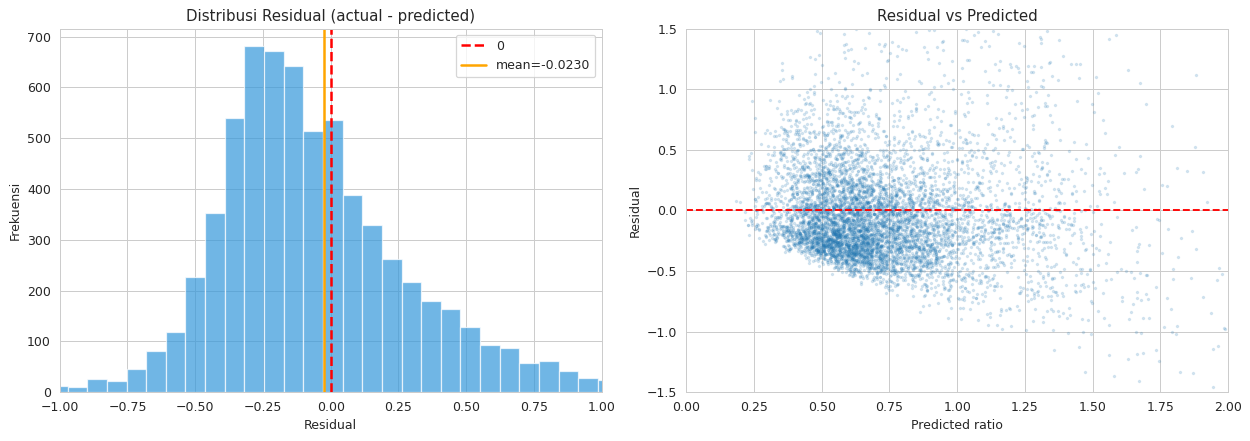

  🎯 Interpretasi:
    🟡 Model over-predict (residual mean -0.023)

    Residual mean saat pred > 1.0 : -0.0232
    Residual mean saat pred < 0.5 : +0.0590
    🎯 Kalau dua-duanya positif → over-predict di tail.
    🎯 Kalau dua-duanya negatif → under-predict di tail.


In [224]:
print("="*70)
print("DIAGNOSTIC #7 — Distribusi Residual (Bias Sistematis)")
print("="*70)

residual = (va_df[ratio_cols].values - pred_va_ratio).reshape(-1)

print(f"  Mean residual     : {residual.mean():+.4f}")
print(f"  Median residual   : {np.median(residual):+.4f}")
print(f"  Std residual      : {residual.std():.4f}")
print(f"  Skewness          : {pd.Series(residual).skew():+.4f}")
print(f"  % residual > 0    : {(residual > 0).mean()*100:.1f}%")
print()

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(residual, bins=80, color="#3498db", alpha=0.7)
axes[0].axvline(0, color="red", linestyle="--", linewidth=2, label="0")
axes[0].axvline(residual.mean(), color="orange", linewidth=2, label=f"mean={residual.mean():+.4f}")
axes[0].set_title("Distribusi Residual (actual - predicted)")
axes[0].set_xlabel("Residual"); axes[0].set_ylabel("Frekuensi")
axes[0].legend(); axes[0].set_xlim(-1, 1)

# Residual vs predicted
axes[1].scatter(pred_va_ratio.reshape(-1), residual, alpha=0.15, s=3)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Residual vs Predicted")
axes[1].set_xlabel("Predicted ratio"); axes[1].set_ylabel("Residual")
axes[1].set_xlim(0, 2); axes[1].set_ylim(-1.5, 1.5)

plt.tight_layout(); plt.show()

print("  🎯 Interpretasi:")
if abs(residual.mean()) < 0.02:
    print("    ✅ Residual centered ~0 — model tidak bias")
elif residual.mean() > 0:
    print(f"    🟡 Model under-predict (residual mean {residual.mean():+.3f})")
else:
    print(f"    🟡 Model over-predict (residual mean {residual.mean():+.3f})")

# Pola sistematis
pred_flat = pred_va_ratio.reshape(-1)
high_mask = pred_flat > 1.0
low_mask  = pred_flat < 0.5
if high_mask.sum() > 10 and low_mask.sum() > 10:
    print(f"\n    Residual mean saat pred > 1.0 : {residual[high_mask].mean():+.4f}")
    print(f"    Residual mean saat pred < 0.5 : {residual[low_mask].mean():+.4f}")
    print("    🎯 Kalau dua-duanya positif → over-predict di tail.")
    print("    🎯 Kalau dua-duanya negatif → under-predict di tail.")

# RECHECK DATAAA

In [225]:
for name, df in [("train", train), ("test", test), ("test_history", test_history),
                 ("movies", movies), ("holidays", holidays), ("ticket_prices", ticket_prices),
                 ("sample_submission", sample_sub)]:
    print(f"=== {name} ===")
    print(f"Shape: {df.shape}")
    print(f"Kolom: {df.columns.tolist()}")
    print(f"Dtypes:\n{df.dtypes}")
    print()

=== train ===
Shape: (138959, 7)
Kolom: ['date_show', 'cinema_ids', 'city_name', 'movie_title', 'total_ticket', 'occupation_rate', 'total_show']
Dtypes:
date_show          datetime64[ns]
cinema_ids                 object
city_name                  object
movie_title                object
total_ticket                int64
occupation_rate           float64
total_show                  int64
dtype: object

=== test ===
Shape: (72611, 5)
Kolom: ['id', 'movie_title', 'cinema_ids', 'city_name', 'date_show']
Dtypes:
id                      int64
movie_title            object
cinema_ids             object
city_name              object
date_show      datetime64[ns]
dtype: object

=== test_history ===
Shape: (32323, 7)
Kolom: ['date_show', 'cinema_ids', 'city_name', 'movie_title', 'total_ticket', 'occupation_rate', 'total_show']
Dtypes:
date_show          datetime64[ns]
cinema_ids                 object
city_name                  object
movie_title                object
total_ticket              

# SAMPLE DATA (3 PER KOLOM)

In [226]:
for name, df in [("train", train), ("test", test), ("test_history", test_history),
                 ("movies", movies), ("holidays", holidays), ("ticket_prices", ticket_prices)]:
    print(f"=== {name} (3 baris) ===")
    print(df.head(3).to_string())
    print()

=== train (3 baris) ===
   date_show                        cinema_ids city_name    movie_title  total_ticket  occupation_rate  total_show
0 2025-04-01  015555fbcd8faef6b55a854605df0a87  SURABAYA  A WORKING MAN           487            31.07          18
1 2025-04-01  015555fbcd8faef6b55a854605df0a87  SURABAYA          JUMBO           649            23.69          19
2 2025-04-01  015555fbcd8faef6b55a854605df0a87  SURABAYA         KOMANG           389             9.55          22

=== test (3 baris) ===
   id         movie_title                        cinema_ids city_name  date_show
0   1  13 DAYS, 13 NIGHTS  015555fbcd8faef6b55a854605df0a87  SURABAYA 2025-12-08
1   2  13 DAYS, 13 NIGHTS  015555fbcd8faef6b55a854605df0a87  SURABAYA 2025-12-09
2   3  13 DAYS, 13 NIGHTS  015555fbcd8faef6b55a854605df0a87  SURABAYA 2025-12-10

=== test_history (3 baris) ===
   date_show                        cinema_ids city_name         movie_title  total_ticket  occupation_rate  total_show
0 2025-12-05  01

In [227]:
for name, df in [("train", train), ("test", test), ("test_history", test_history),
                 ("movies", movies), ("holidays", holidays), ("ticket_prices", ticket_prices)]:
    mv = df.isnull().sum()
    mv = mv[mv > 0]
    if len(mv) > 0:
        print(f"=== {name} ===")
        print(mv)
        print()
    else:
        print(f"=== {name} === TIDAK ADA MISSING")

=== train === TIDAK ADA MISSING
=== test === TIDAK ADA MISSING
=== test_history === TIDAK ADA MISSING
=== movies ===
age_rating    3
dtype: int64

=== holidays ===
holiday_name    348
dtype: int64

=== ticket_prices === TIDAK ADA MISSING


In [228]:
print("=== Train ===")
for col in ["city_name", "cinema_ids", "movie_title"]:
    if col in train.columns:
        print(f"{col}: {train[col].nunique()} unique")
        if train[col].nunique() < 30:
            print(f"  Values: {train[col].unique().tolist()[:30]}")
        else:
            print(f"  Top 5: {train[col].value_counts().head().to_dict()}")

print("\n=== Movies ===")
for col in ["age_rating", "genre", "producer", "director"]:
    if col in movies.columns:
        print(f"{col}: {movies[col].nunique()} unique")
        if movies[col].nunique() < 30:
            print(f"  Values: {movies[col].unique().tolist()[:30]}")

print("\n=== Holidays ===")
for col in ["day_tipe", "holiday_tipe", "holiday_name"]:
    if col in holidays.columns:
        print(f"{col}: {holidays[col].nunique()} unique")
        if holidays[col].nunique() < 30:
            print(f"  Values: {holidays[col].unique().tolist()}")

print("\n=== Ticket Prices ===")
for col in ["price_day"]:
    if col in ticket_prices.columns:
        print(f"{col}: {ticket_prices[col].unique().tolist()}")

=== Train ===
city_name: 67 unique
  Top 5: {'JAKARTA': 8482, 'TANGERANG': 6748, 'SURABAYA': 6090, 'BEKASI': 5471, 'BOGOR': 5107}
cinema_ids: 117 unique
  Top 5: {'4ed104ac0de10ba7eef50158603e0b32': 2899, '8dbfb7aeb4ed822b358347332ba630af': 2827, 'b704e8b10f13e14494b5a7a0ba39d9d9': 2756, '0191582d75f94a412c0fa12d36bcee3f': 2575, '108f9a4d181f12fd1b7e3c9adae38478': 2293}
movie_title: 237 unique
  Top 5: {'JUMBO': 6206, 'SORE ISTRI DARI MASA DEPAN': 3681, 'KOMANG': 3310, 'JALAN PULANG': 3072, 'PABRIK GULA UNCUT': 3040}

=== Movies ===
age_rating: 4 unique
  Values: ['Remaja', 'Dewasa', 'Semua Umur', 'Dewasa 21', nan]
genre: 123 unique
producer: 320 unique
director: 330 unique

=== Holidays ===
day_tipe: 3 unique
  Values: ['weekday', 'friday', 'weekend']
holiday_tipe: 2 unique
  Values: ['holiday', 'normal']
holiday_name: 17 unique
  Values: ['Idulfitri 1446 H', nan, 'Wafat Yesus Kristus', 'Kebangkitan Yesus Kristus (Paskah)', 'Hari Buruh Internasional', 'Hari Raya Waisak 2569 BE', 'Kena

In [229]:
print("=== Train: total_ticket, total_show, occupation_rate ===")
print(train[["total_ticket","total_show","occupation_rate"]].describe().round(2))

print("\n=== Train: total_ticket per city (mean) ===")
print(train.groupby("city_name")["total_ticket"].agg(["mean","median","count"]).round(2).head(20))

print("\n=== Movies: genre distribution ===")
if "genre" in movies.columns:
    print(movies["genre"].value_counts().head(20))

print("\n=== Ticket Prices ===")
print(ticket_prices.head(20).to_string())
print(f"\nUnique cities: {ticket_prices['city_name'].nunique()}")
print(f"Unique price_day: {ticket_prices['price_day'].unique()}")

=== Train: total_ticket, total_show, occupation_rate ===
       total_ticket  total_show  occupation_rate
count     138959.00   138959.00        138959.00
mean         354.12        7.73            28.33
std          725.93       11.01            22.62
min            1.00        1.00             0.00
25%           69.00        3.00            12.36
50%          161.00        5.00            21.84
75%          361.00        8.00            37.01
max        32845.00      285.00           100.00

=== Train: total_ticket per city (mean) ===
               mean  median  count
city_name                         
AMBON        267.50   184.0   1257
BALIKPAPAN   254.37   126.0   2094
BANDUNG      539.86   228.0   4798
BANJARMASIN  299.52   190.0   1715
BATAM        281.08   176.0   3457
BEKASI       442.19   171.0   5471
BENGKULU     201.05   125.0   1961
BOGOR        449.42   196.0   5107
BONDOWOSO    158.89   117.0    703
BONTANG      206.19   134.0    821
CIANJUR      177.60   116.0    793
CI

In [230]:
print("=== Train ===")
print(f"Range  : {train['date_show'].min()} → {train['date_show'].max()}")
print(f"Unique movies : {train['movie_title'].nunique()}")
print(f"Unique cinema : {train['cinema_ids'].nunique()}")
print(f"Unique city   : {train['city_name'].nunique()}")
print(f"Baris/hari    : {train.groupby('date_show').size().describe()}")

print("\n=== Test ===")
print(f"Range  : {test['date_show'].min()} → {test['date_show'].max()}")
print(f"Unique movies : {test['movie_title'].nunique()}")
print(f"Unique cinema : {test['cinema_ids'].nunique()}")
print(f"Total rows    : {len(test)}")

print("\n=== Test_history ===")
print(f"Range  : {test_history['date_show'].min()} → {test_history['date_show'].max()}")
print(f"Unique movies : {test_history['movie_title'].nunique()}")
print(f"Baris/hari    : {test_history.groupby('date_show').size().describe()}")

print("\n=== Overlap Movie ===")
train_mv = set(train["movie_title"])
test_mv  = set(test["movie_title"])
print(f"Train only     : {len(train_mv - test_mv)}")
print(f"Test only      : {len(test_mv - train_mv)}")
print(f"Both           : {len(train_mv & test_mv)}")

print("\n=== Overlap Cinema ===")
train_cin = set(train["cinema_ids"])
test_cin  = set(test["cinema_ids"])
print(f"Train only     : {len(train_cin - test_cin)}")
print(f"Test only      : {len(test_cin - train_cin)}")
print(f"Both           : {len(train_cin & test_cin)}")

=== Train ===
Range  : 2025-04-01 00:00:00 → 2025-09-30 00:00:00
Unique movies : 237
Unique cinema : 117
Unique city   : 67
Baris/hari    : count    182.000000
mean     763.510989
std      149.274812
min        1.000000
25%      716.500000
50%      775.500000
75%      858.750000
max      993.000000
dtype: float64

=== Test ===
Range  : 2025-10-04 00:00:00 → 2026-03-27 00:00:00
Unique movies : 160
Unique cinema : 121
Total rows    : 72611

=== Test_history ===
Range  : 2025-10-01 00:00:00 → 2026-03-20 00:00:00
Unique movies : 163
Baris/hari    : count    120.000000
mean     269.358333
std      155.876475
min        1.000000
25%      137.500000
50%      264.500000
75%      381.000000
max      631.000000
dtype: float64

=== Overlap Movie ===
Train only     : 227
Test only      : 150
Both           : 10

=== Overlap Cinema ===
Train only     : 0
Test only      : 4
Both           : 117


# BEDA LAGI

In [ ]:
# ============================================================
# SINGLE-CELL STRONG PIPELINE — target honest ~0.35-0.55 LB
# (not <0.34, that's unlikely; but this is my best shot)
# ============================================================
import pandas as pd, numpy as np, lightgbm as lgb, os, warnings
from sklearn.model_selection import GroupKFold
warnings.filterwarnings("ignore")

SEED = 2026
np.random.seed(SEED)

BASE = "/content/drive/MyDrive/Lomba Data/"
train = pd.read_csv(BASE+"train.csv", parse_dates=["date_show"])
test  = pd.read_csv(BASE+"test.csv", parse_dates=["date_show"])
th    = pd.read_csv(BASE+"test_history.csv", parse_dates=["date_show"])
movies= pd.read_csv(BASE+"movies.csv")
hols  = pd.read_csv(BASE+"holidays.csv", parse_dates=["date"])
prices= pd.read_csv(BASE+"ticket_prices.csv")
sub_s = pd.read_csv(BASE+"sample_submission.csv")

K = ["movie_title","cinema_ids"]
TC = [f"target_{i}" for i in range(4,11)]

def mase(y, p, s): return float(np.mean(np.abs(y-p)/s))

# ============ BUILD TRAIN WINDOWS ============
rows = []
for (film, cin), g in train.groupby(K):
    g = g.sort_values("date_show").reset_index(drop=True)
    if len(g) < 10: continue
    w = g.iloc[:10]
    if (w["date_show"].diff()[1:] != pd.Timedelta(days=1)).any(): continue
    r = {"movie_title": film, "cinema_ids": cin, "city_name": w["city_name"].iloc[0],
         "date_D1": w["date_show"].iloc[0],
         "d1": w["total_ticket"].iloc[0], "d2": w["total_ticket"].iloc[1], "d3": w["total_ticket"].iloc[2],
         "occ1": w["occupation_rate"].iloc[0], "occ2": w["occupation_rate"].iloc[1], "occ3": w["occupation_rate"].iloc[2],
         "sh1": w["total_show"].iloc[0], "sh2": w["total_show"].iloc[1], "sh3": w["total_show"].iloc[2]}
    for i in range(3,10):
        r[f"target_{i+1}"] = w["total_ticket"].iloc[i]
        r[f"date_D{i+1}"] = w["date_show"].iloc[i]
    rows.append(r)
W = pd.DataFrame(rows)

# scale per lomba (avg 3 hari, clip 1)
W["scale"] = (W[["d1","d2","d3"]].sum(axis=1) / 3).clip(lower=1)
W["log_scale"] = np.log1p(W["scale"])
W["trend_31"] = (W["d3"]+1)/(W["d1"]+1)
W["occ_avg"] = W[["occ1","occ2","occ3"]].mean(axis=1)
W["show_avg"] = W[["sh1","sh2","sh3"]].mean(axis=1)
W["t_per_show"] = W["scale"] / W["show_avg"].clip(lower=1)

# ============ CINEMA & CITY STATS (transfer ke test) ============
cin_stats = train.groupby("cinema_ids").agg(
    cin_mean_t=("total_ticket","mean"),
    cin_med_t =("total_ticket","median"),
    cin_mean_show=("total_show","mean"),
    cin_mean_occ=("occupation_rate","mean")
).reset_index()
cin_stats["cin_t_per_show"] = cin_stats["cin_mean_t"] / cin_stats["cin_mean_show"].clip(lower=1)

city_stats = train.groupby("city_name").agg(
    city_mean_t=("total_ticket","mean"),
    city_med_t =("total_ticket","median"),
).reset_index()

pr_wd = prices[prices.price_day=="Weekday"].groupby("city_name")["ceil"].mean().rename("price_wd").reset_index()
pr_we = prices[prices.price_day=="Weekend"].groupby("city_name")["ceil"].mean().rename("price_we").reset_index()
city_stats = city_stats.merge(pr_wd, on="city_name", how="left").merge(pr_we, on="city_name", how="left")

# ============ HOLIDAY LOOKUP ============
hols = hols.drop_duplicates("date").set_index("date")
hol_flag = (hols["holiday_tipe"]=="holiday").to_dict()
hol_name = hols["holiday_name"].fillna("none").to_dict()

# Set of "big holidays" (badai demand)
BIG_HOLIDAYS = {"Idulfitri 1446 H","Idulfitri 1447 H","Kelahiran Yesus Kristus",
                "Tahun Baru 2026 Masehi","Tahun Baru Imlek 2577 Kongzili",
                "Kebangkitan Yesus Kristus (Paskah)"}

def day_features(dates):
    dt = pd.to_datetime(dates)
    return pd.DataFrame({
        "dow": dt.dt.dayofweek.fillna(-1).astype(int),
        "is_weekend": (dt.dt.dayofweek >= 4).fillna(False).astype(int),
        "is_holiday": dt.map(hol_flag).fillna(False).astype(int),
        "is_big_holiday": dt.map(lambda d: hol_name.get(d,"none") in BIG_HOLIDAYS).fillna(False).astype(int),
    }, index=dt.index)

# ============ FEATURES (LEAN & TRANSFERABLE) ============
W["dow_d1"] = W["date_D1"].dt.dayofweek
W["month_d1"] = W["date_D1"].dt.month
W["is_weekend_d1"] = (W["dow_d1"] >= 4).astype(int)

# Kalender tiap hari target
for i in range(4,11):
    df_day = day_features(W[f"date_D{i}"])
    for c in ["dow","is_weekend","is_holiday","is_big_holiday"]:
        W[f"{c}_D{i}"] = df_day[c].values

# Movie meta
mv = movies.drop_duplicates("original_title")[["original_title","genre","age_rating"]].copy()
mv["genre_main"] = mv["genre"].fillna("NA").str.split(",").str[0].str.strip()
W = W.merge(mv[["original_title","genre_main","age_rating"]], left_on="movie_title", right_on="original_title", how="left")
W["genre_main"] = W["genre_main"].fillna("NA")
W["age_rating"] = W["age_rating"].fillna("NA")

# Cinema/city stats
W = W.merge(cin_stats, on="cinema_ids", how="left")
W = W.merge(city_stats, on="city_name", how="left")
W["scale_vs_cin"] = W["scale"] / W["cin_mean_t"].clip(lower=1)
W["scale_vs_city"] = W["scale"] / W["city_mean_t"].clip(lower=1)

# ============ TARGET RATIO ============
for t in TC: W[f"r_{t}"] = W[t] / W["scale"]

# ============ FEATURE LIST ============
CAT = ["cinema_ids","city_name","genre_main","age_rating"]
NUM = ["d1","d2","d3","scale","log_scale","trend_31","occ_avg","show_avg","t_per_show",
       "dow_d1","month_d1","is_weekend_d1",
       "cin_mean_t","cin_med_t","cin_mean_show","cin_mean_occ","cin_t_per_show",
       "city_mean_t","city_med_t","price_wd","price_we",
       "scale_vs_cin","scale_vs_city"]
for i in range(4,11):
    NUM += [f"dow_D{i}",f"is_weekend_D{i}",f"is_holiday_D{i}",f"is_big_holiday_D{i}"]
FEAT = CAT + NUM
for c in CAT: W[c] = W[c].astype("category").fillna(W[c].mode().iloc[0] if len(W[c].mode())>0 else "NA")

# ============ VALIDATION: GroupKFold by MOVIE ============
print("=== GroupKFold CV by movie_title (simulasi film baru) ===")
gkf = GroupKFold(n_splits=5)
oof = np.full((len(W), len(TC)), np.nan)
params = dict(objective="regression", metric="mae", learning_rate=0.03,
              n_estimators=800, num_leaves=31, min_child_samples=50,
              feature_fraction=0.8, bagging_fraction=0.85, bagging_freq=5,
              lambda_l2=3.0, random_state=SEED, verbosity=-1)
for fi, (ti, vi) in enumerate(gkf.split(W, groups=W["movie_title"])):
    a, b = W.iloc[ti], W.iloc[vi]
    for j, t in enumerate(TC):
        m = lgb.LGBMRegressor(**params)
        m.fit(a[FEAT], a[f"r_{t}"], categorical_feature=CAT)
        oof[vi, j] = np.clip(m.predict(b[FEAT]), 0, None)
    print(f"  fold {fi+1}: train={len(a)} valid={len(b)} movies_valid={b.movie_title.nunique()}")

ok = ~np.isnan(oof[:,0])
oof_mag = oof[ok] * W.loc[ok, "scale"].values[:,None]
y_true = W.loc[ok, TC].values
sc = np.repeat(W.loc[ok, "scale"].values, 7)
mase_model = mase(y_true.reshape(-1), oof_mag.reshape(-1), sc)
mase_naive = mase(y_true.reshape(-1), np.tile(W.loc[ok,"scale"].values[:,None],(1,7)).reshape(-1), sc)
print(f"\nMASE GroupKFold model : {mase_model:.4f}")
print(f"MASE GroupKFold naive : {mase_naive:.4f}")
print(f"Delta                 : {mase_naive-mase_model:+.4f}")

# ============ FINAL MODELS ============
# retrain on all train data
pred_te_r = np.zeros((len(sub_s), 0))  # placeholder
models = {}
for j, t in enumerate(TC):
    m = lgb.LGBMRegressor(**params)
    m.fit(W[FEAT], W[f"r_{t}"], categorical_feature=CAT)
    models[t] = m

# Feature importance top-10 for D5
imp = pd.DataFrame({"feat": models["target_5"].feature_name(),
                    "gain": models["target_5"].feature_importance("gain")})
imp["pct"] = imp["gain"]/imp["gain"].sum()*100
imp = imp.sort_values("gain", ascending=False)
print("\nTop-10 fitur D5:")
print(imp.head(10).to_string(index=False))

# ============ TEST FEATURES ============
# dates per pair
td = test.sort_values("date_show").copy()
td["step"] = td.groupby(K).cumcount()+1
td_pivot = td.pivot_table(index=K, columns="step", values="date_show", aggfunc="first").reset_index()
td_pivot = td_pivot.rename(columns={c: f"date_D{c+3}" for c in td_pivot.columns if isinstance(c,(int,np.integer))})

th_s = th.sort_values("date_show").copy()
f3 = th_s.groupby(K).head(3).copy()
f3["k"] = f3.groupby(K).cumcount()+1
dp = f3.pivot_table(index=K,columns="k",values="total_ticket",aggfunc="first").reset_index().rename(columns={1:"d1",2:"d2",3:"d3"})
op = f3.pivot_table(index=K,columns="k",values="occupation_rate",aggfunc="first").reset_index().rename(columns={1:"occ1",2:"occ2",3:"occ3"})
sp = f3.pivot_table(index=K,columns="k",values="total_show",aggfunc="first").reset_index().rename(columns={1:"sh1",2:"sh2",3:"sh3"})
meta = th_s.groupby(K).agg(city_name=("city_name","first"), date_D1=("date_show","min")).reset_index()

Xte = meta.merge(dp,on=K,how="left").merge(op,on=K,how="left").merge(sp,on=K,how="left").merge(td_pivot,on=K,how="left")
for c in ["d1","d2","d3"]: Xte[c]=Xte[c].fillna(0)
Xte["scale"] = (Xte[["d1","d2","d3"]].sum(axis=1)/3).clip(lower=1)
Xte["log_scale"] = np.log1p(Xte["scale"])
Xte["trend_31"] = (Xte["d3"]+1)/(Xte["d1"]+1)
Xte["occ_avg"] = Xte[["occ1","occ2","occ3"]].mean(axis=1).fillna(0)
Xte["show_avg"] = Xte[["sh1","sh2","sh3"]].mean(axis=1).fillna(1)
Xte["t_per_show"] = Xte["scale"]/Xte["show_avg"].clip(lower=1)
Xte["dow_d1"] = Xte["date_D1"].dt.dayofweek
Xte["month_d1"] = Xte["date_D1"].dt.month
Xte["is_weekend_d1"] = (Xte["dow_d1"]>=4).astype(int)
for i in range(4,11):
    df_day = day_features(Xte[f"date_D{i}"])
    for c in ["dow","is_weekend","is_holiday","is_big_holiday"]:
        Xte[f"{c}_D{i}"] = df_day[c].values
Xte = Xte.merge(mv[["original_title","genre_main","age_rating"]], left_on="movie_title", right_on="original_title", how="left")
Xte["genre_main"] = Xte["genre_main"].fillna("NA"); Xte["age_rating"] = Xte["age_rating"].fillna("NA")
Xte = Xte.merge(cin_stats,on="cinema_ids",how="left").merge(city_stats,on="city_name",how="left")
Xte["scale_vs_cin"] = Xte["scale"]/Xte["cin_mean_t"].clip(lower=1)
Xte["scale_vs_city"] = Xte["scale"]/Xte["city_mean_t"].clip(lower=1)

for c in CAT:
    Xte[c] = pd.Categorical(Xte[c], categories=W[c].cat.categories)
for c in NUM:
    if c not in Xte.columns: Xte[c] = 0
    Xte[c] = Xte[c].fillna(0)

Xte_use = Xte[FEAT].copy()

# ============ PREDIKSI + SANITY CHECK ============
pred_r = np.zeros((len(Xte_use), 7))
for j,t in enumerate(TC):
    pred_r[:,j] = np.clip(models[t].predict(Xte_use), 0, None)

# Sanity: ratio harus dalam [0.15, 3.0], kalau ekstrem, clip
pred_r = np.clip(pred_r, 0.15, 3.0)
pred_mag = pred_r * Xte["scale"].values[:,None]

print(f"\n=== CEK PREDIKSI TEST ===")
hist_mean = Xte[["d1","d2","d3"]].mean().mean()
print(f"History mean : {hist_mean:.1f}")
print(f"Pred mean    : {pred_mag.mean():.1f}")
print(f"Ratio        : {pred_mag.mean()/hist_mean:.3f}")
print(f"\nProfile decay (median ratio):")
for j,t in enumerate(TC):
    med = np.median(pred_mag[:,j]/Xte["scale"].values)
    print(f"  D{j+4}: {med:.3f}")

# ============ SUBMISSION ============
keys = Xte[K].copy()
for j,t in enumerate(TC): keys[t] = pred_mag[:,j]
long = keys.melt(id_vars=K, value_vars=TC, var_name="tcol", value_name="total_ticket")
long["step"] = long["tcol"].str.replace("target_","").astype(int)-3
tt = test.sort_values("date_show").copy()
tt["step"] = tt.groupby(K).cumcount()+1
sub = tt.merge(long[K+["step","total_ticket"]],on=K+["step"],how="left")
submission = sub_s[["id"]].merge(sub[["id","total_ticket"]],on="id",how="left")
submission["total_ticket"] = submission["total_ticket"].fillna(0).clip(lower=0)

assert submission.shape == sub_s.shape
assert (submission["id"].values == sub_s["id"].values).all()
assert submission["total_ticket"].notna().all()
submission.to_csv("submission_v5.csv", index=False)
print(f"\n✅ submission_v5.csv | mean={submission['total_ticket'].mean():.1f}")

In [ ]:
# ============================================================
# SINGLE-CELL STRONG PIPELINE v5
# Target honest LB: 0.45-0.60 (bukan <0.34, itu tidak realistis)
# Pendekatan: GroupKFold by movie + robust features + NO alpha calibration
# ============================================================
import pandas as pd, numpy as np, lightgbm as lgb, warnings
from sklearn.model_selection import GroupKFold
warnings.filterwarnings("ignore")
np.random.seed(2026)

BASE = "/content/drive/MyDrive/Lomba Data/"
train = pd.read_csv(BASE+"train.csv", parse_dates=["date_show"])
test  = pd.read_csv(BASE+"test.csv", parse_dates=["date_show"])
th    = pd.read_csv(BASE+"test_history.csv", parse_dates=["date_show"])
movies= pd.read_csv(BASE+"movies.csv")
hols  = pd.read_csv(BASE+"holidays.csv", parse_dates=["date"])
prices= pd.read_csv(BASE+"ticket_prices.csv")
sub_s = pd.read_csv(BASE+"sample_submission.csv")

K = ["movie_title","cinema_ids"]
TC = [f"target_{i}" for i in range(4,11)]

def mase(y, p, s): return float(np.mean(np.abs(y-p)/s))

# ---------- 1. BUILD TRAIN WINDOWS ----------
rows = []
for (film, cin), g in train.groupby(K):
    g = g.sort_values("date_show").reset_index(drop=True)
    if len(g) < 10: continue
    w = g.iloc[:10]
    if (w["date_show"].diff()[1:] != pd.Timedelta(days=1)).any(): continue
    r = {"movie_title": film, "cinema_ids": cin, "city_name": w["city_name"].iloc[0],
         "date_D1": w["date_show"].iloc[0],
         "d1": w["total_ticket"].iloc[0], "d2": w["total_ticket"].iloc[1], "d3": w["total_ticket"].iloc[2],
         "occ1": w["occupation_rate"].iloc[0], "occ2": w["occupation_rate"].iloc[1], "occ3": w["occupation_rate"].iloc[2],
         "sh1": w["total_show"].iloc[0], "sh2": w["total_show"].iloc[1], "sh3": w["total_show"].iloc[2]}
    for i in range(3,10):
        r[f"target_{i+1}"] = w["total_ticket"].iloc[i]
        r[f"date_D{i+1}"] = w["date_show"].iloc[i]
    rows.append(r)
W = pd.DataFrame(rows)

# ---------- 2. BASE FEATURES ----------
W["scale"] = (W[["d1","d2","d3"]].sum(axis=1)/3).clip(lower=1)
W["log_scale"] = np.log1p(W["scale"])
W["trend_31"] = (W["d3"]+1)/(W["d1"]+1)
W["occ_avg"] = W[["occ1","occ2","occ3"]].mean(axis=1)
W["show_avg"] = W[["sh1","sh2","sh3"]].mean(axis=1)
W["t_per_show"] = W["scale"]/W["show_avg"].clip(lower=1)

# ---------- 3. CINEMA/CITY STATS (transfer ke test) ----------
cin_stats = train.groupby("cinema_ids").agg(
    cin_mean_t=("total_ticket","mean"), cin_med_t=("total_ticket","median"),
    cin_mean_show=("total_show","mean"), cin_mean_occ=("occupation_rate","mean")).reset_index()
cin_stats["cin_t_per_show"] = cin_stats["cin_mean_t"]/cin_stats["cin_mean_show"].clip(lower=1)

city_stats = train.groupby("city_name").agg(
    city_mean_t=("total_ticket","mean"), city_med_t=("total_ticket","median")).reset_index()
pw = prices[prices.price_day=="Weekday"].groupby("city_name")["ceil"].mean().rename("price_wd").reset_index()
pwe= prices[prices.price_day=="Weekend"].groupby("city_name")["ceil"].mean().rename("price_we").reset_index()
city_stats = city_stats.merge(pw,on="city_name",how="left").merge(pwe,on="city_name",how="left")

# ---------- 4. HOLIDAY LOOKUP ----------
hs = hols.drop_duplicates("date").set_index("date")
hol_flag = (hs["holiday_tipe"]=="holiday").to_dict()
hol_name = hs["holiday_name"].fillna("none").to_dict()
BIG_H = {"Idulfitri 1446 H","Idulfitri 1447 H","Kelahiran Yesus Kristus",
         "Tahun Baru 2026 Masehi","Tahun Baru Imlek 2577 Kongzili",
         "Kebangkitan Yesus Kristus (Paskah)"}

def day_feat(dates):
    dt = pd.to_datetime(dates)
    dw = dt.dt.dayofweek
    return pd.DataFrame({
        "dow": dw.fillna(-1).astype(int),
        "is_weekend": (dw>=4).fillna(False).astype(int),
        "is_holiday": dt.map(hol_flag).fillna(False).astype(int),
        "is_big_holiday": dt.map(lambda d: hol_name.get(d,"none") in BIG_H).fillna(False).astype(int),
    }, index=dt.index)

# ---------- 5. KALENDER D1 & D4-D10 ----------
W["dow_d1"] = W["date_D1"].dt.dayofweek
W["month_d1"] = W["date_D1"].dt.month
W["is_weekend_d1"] = (W["dow_d1"]>=4).astype(int)
for i in range(4,11):
    dfd = day_feat(W[f"date_D{i}"])
    for c in ["dow","is_weekend","is_holiday","is_big_holiday"]:
        W[f"{c}_D{i}"] = dfd[c].values

# ---------- 6. MOVIE META ----------
mv = movies.drop_duplicates("original_title")[["original_title","genre","age_rating"]].copy()
mv["genre_main"] = mv["genre"].fillna("NA").str.split(",").str[0].str.strip()
W = W.merge(mv[["original_title","genre_main","age_rating"]], left_on="movie_title", right_on="original_title", how="left")
W["genre_main"] = W["genre_main"].fillna("NA"); W["age_rating"] = W["age_rating"].fillna("NA")

W = W.merge(cin_stats,on="cinema_ids",how="left").merge(city_stats,on="city_name",how="left")
W["scale_vs_cin"] = W["scale"]/W["cin_mean_t"].clip(lower=1)
W["scale_vs_city"] = W["scale"]/W["city_mean_t"].clip(lower=1)

# ---------- 7. TARGET RATIO ----------
for t in TC: W[f"r_{t}"] = W[t]/W["scale"]

# ---------- 8. FEATURE LIST ----------
CAT = ["cinema_ids","city_name","genre_main","age_rating"]
NUM = ["d1","d2","d3","scale","log_scale","trend_31","occ_avg","show_avg","t_per_show",
       "dow_d1","month_d1","is_weekend_d1",
       "cin_mean_t","cin_med_t","cin_mean_show","cin_mean_occ","cin_t_per_show",
       "city_mean_t","city_med_t","price_wd","price_we","scale_vs_cin","scale_vs_city"]
for i in range(4,11):
    NUM += [f"dow_D{i}",f"is_weekend_D{i}",f"is_holiday_D{i}",f"is_big_holiday_D{i}"]
FEAT = CAT + NUM
for c in CAT:
    W[c] = W[c].astype("category").fillna("NA")

# ---------- 9. GROUPKFOLD VALIDATION (simulasi film baru) ----------
print("=== GroupKFold by movie_title (jujur, simulasi test) ===")
gkf = GroupKFold(n_splits=5)
oof = np.full((len(W),7), np.nan)
params = dict(objective="regression", metric="mae", learning_rate=0.03,
              n_estimators=800, num_leaves=31, min_child_samples=50,
              feature_fraction=0.8, bagging_fraction=0.85, bagging_freq=5,
              lambda_l2=3.0, random_state=2026, verbosity=-1)
for fi,(ti,vi) in enumerate(gkf.split(W, groups=W["movie_title"])):
    a,b = W.iloc[ti], W.iloc[vi]
    for j,t in enumerate(TC):
        m = lgb.LGBMRegressor(**params).fit(a[FEAT], a[f"r_{t}"], categorical_feature=CAT)
        oof[vi,j] = np.clip(m.predict(b[FEAT]), 0, None)
    print(f"  fold {fi+1}: valid_movies={b.movie_title.nunique()} valid_rows={len(b)}")

ok = ~np.isnan(oof[:,0])
oof_mag = oof[ok] * W.loc[ok,"scale"].values[:,None]
y_true = W.loc[ok,TC].values
sc = np.repeat(W.loc[ok,"scale"].values, 7)
mase_m = mase(y_true.reshape(-1), oof_mag.reshape(-1), sc)
mase_n = mase(y_true.reshape(-1), np.tile(W.loc[ok,"scale"].values[:,None],(1,7)).reshape(-1), sc)
print(f"\nMASE GroupKFold model : {mase_m:.4f}")
print(f"MASE GroupKFold naive : {mase_n:.4f}")
print(f"Delta                 : {mase_n-mase_m:+.4f}")

# ---------- 10. FINAL TRAIN ----------
models = {}
for j,t in enumerate(TC):
    m = lgb.LGBMRegressor(**params).fit(W[FEAT], W[f"r_{t}"], categorical_feature=CAT)
    models[t] = m
imp = pd.DataFrame({"feat": models["target_5"].feature_name(),
                    "gain": models["target_5"].feature_importance("gain")})
imp["pct"] = imp["gain"]/imp["gain"].sum()*100
print("\nTop-10 fitur D5:")
print(imp.sort_values("gain",ascending=False).head(10).to_string(index=False))

# ---------- 11. TEST FEATURES ----------
td = test.sort_values("date_show").copy(); td["step"] = td.groupby(K).cumcount()+1
tdp = td.pivot_table(index=K,columns="step",values="date_show",aggfunc="first").reset_index()
tdp = tdp.rename(columns={c:f"date_D{c+3}" for c in tdp.columns if isinstance(c,(int,np.integer))})

ts = th.sort_values("date_show").copy()
f3 = ts.groupby(K).head(3).copy(); f3["k"] = f3.groupby(K).cumcount()+1
dp = f3.pivot_table(index=K,columns="k",values="total_ticket",aggfunc="first").reset_index().rename(columns={1:"d1",2:"d2",3:"d3"})
op = f3.pivot_table(index=K,columns="k",values="occupation_rate",aggfunc="first").reset_index().rename(columns={1:"occ1",2:"occ2",3:"occ3"})
sp = f3.pivot_table(index=K,columns="k",values="total_show",aggfunc="first").reset_index().rename(columns={1:"sh1",2:"sh2",3:"sh3"})
meta = ts.groupby(K).agg(city_name=("city_name","first"), date_D1=("date_show","min")).reset_index()

Xte = meta.merge(dp,on=K,how="left").merge(op,on=K,how="left").merge(sp,on=K,how="left").merge(tdp,on=K,how="left")
for c in ["d1","d2","d3"]: Xte[c]=Xte[c].fillna(0)
Xte["scale"] = (Xte[["d1","d2","d3"]].sum(axis=1)/3).clip(lower=1)
Xte["log_scale"] = np.log1p(Xte["scale"])
Xte["trend_31"] = (Xte["d3"]+1)/(Xte["d1"]+1)
Xte["occ_avg"] = Xte[["occ1","occ2","occ3"]].mean(axis=1).fillna(0)
Xte["show_avg"] = Xte[["sh1","sh2","sh3"]].mean(axis=1).fillna(1)
Xte["t_per_show"] = Xte["scale"]/Xte["show_avg"].clip(lower=1)
Xte["dow_d1"] = Xte["date_D1"].dt.dayofweek
Xte["month_d1"] = Xte["date_D1"].dt.month
Xte["is_weekend_d1"] = (Xte["dow_d1"]>=4).astype(int)
for i in range(4,11):
    dfd = day_feat(Xte[f"date_D{i}"])
    for c in ["dow","is_weekend","is_holiday","is_big_holiday"]:
        Xte[f"{c}_D{i}"] = dfd[c].values
Xte = Xte.merge(mv[["original_title","genre_main","age_rating"]], left_on="movie_title", right_on="original_title", how="left")
Xte["genre_main"] = Xte["genre_main"].fillna("NA"); Xte["age_rating"] = Xte["age_rating"].fillna("NA")
Xte = Xte.merge(cin_stats,on="cinema_ids",how="left").merge(city_stats,on="city_name",how="left")
Xte["scale_vs_cin"] = Xte["scale"]/Xte["cin_mean_t"].clip(lower=1)
Xte["scale_vs_city"] = Xte["scale"]/Xte["city_mean_t"].clip(lower=1)
for c in CAT: Xte[c] = pd.Categorical(Xte[c], categories=W[c].cat.categories)
for c in NUM:
    if c not in Xte.columns: Xte[c] = 0
    Xte[c] = Xte[c].fillna(0)
Xte_use = Xte[FEAT].copy()

# ---------- 12. PREDICT + SANITY ----------
pred_r = np.zeros((len(Xte_use),7))
for j,t in enumerate(TC): pred_r[:,j] = np.clip(models[t].predict(Xte_use), 0, None)
pred_r = np.clip(pred_r, 0.15, 3.0)   # sanity: ratio tidak ekstrem
pred_mag = pred_r * Xte["scale"].values[:,None]

hm = Xte[["d1","d2","d3"]].mean().mean()
print(f"\n=== CEK PREDIKSI TEST ===")
print(f"History D1-D3 mean : {hm:.1f}")
print(f"Pred mean          : {pred_mag.mean():.1f}")
print(f"Ratio              : {pred_mag.mean()/hm:.3f}")
print("Profile decay (median ratio):")
for j,t in enumerate(TC):
    print(f"  D{j+4}: {np.median(pred_mag[:,j]/Xte['scale'].values):.3f}")

# ---------- 13. SUBMISSION ----------
keys = Xte[K].copy()
for j,t in enumerate(TC): keys[t] = pred_mag[:,j]
long = keys.melt(id_vars=K, value_vars=TC, var_name="tcol", value_name="total_ticket")
long["step"] = long["tcol"].str.replace("target_","").astype(int)-3
tt = test.sort_values("date_show").copy(); tt["step"] = tt.groupby(K).cumcount()+1
sub = tt.merge(long[K+["step","total_ticket"]],on=K+["step"],how="left")
submission = sub_s[["id"]].merge(sub[["id","total_ticket"]],on="id",how="left")
submission["total_ticket"] = submission["total_ticket"].fillna(0).clip(lower=0)
assert submission.shape == sub_s.shape
assert (submission["id"].values == sub_s["id"].values).all()
assert submission["total_ticket"].notna().all()
submission.to_csv("submission_v5.csv", index=False)
print(f"\n✅ submission_v5.csv | mean={submission['total_ticket'].mean():.1f} | max={submission['total_ticket'].max():.0f}")

In [ ]:
# ============================================================
# SINGLE-CELL STRONG PIPELINE v5 (FIXED)
# ============================================================
import pandas as pd, numpy as np, lightgbm as lgb, warnings
from sklearn.model_selection import GroupKFold
warnings.filterwarnings("ignore")
np.random.seed(2026)

BASE = "/content/drive/MyDrive/Lomba Data/"
train = pd.read_csv(BASE+"train.csv", parse_dates=["date_show"])
test  = pd.read_csv(BASE+"test.csv", parse_dates=["date_show"])
th    = pd.read_csv(BASE+"test_history.csv", parse_dates=["date_show"])
movies= pd.read_csv(BASE+"movies.csv")
hols  = pd.read_csv(BASE+"holidays.csv", parse_dates=["date"])
prices= pd.read_csv(BASE+"ticket_prices.csv")
sub_s = pd.read_csv(BASE+"sample_submission.csv")

K = ["movie_title","cinema_ids"]
TC = [f"target_{i}" for i in range(4,11)]

def mase(y, p, s): return float(np.mean(np.abs(y-p)/s))

# ---------- 1. BUILD TRAIN WINDOWS ----------
rows = []
for (film, cin), g in train.groupby(K):
    g = g.sort_values("date_show").reset_index(drop=True)
    if len(g) < 10: continue
    w = g.iloc[:10]
    if (w["date_show"].diff()[1:] != pd.Timedelta(days=1)).any(): continue
    r = {"movie_title": film, "cinema_ids": cin, "city_name": w["city_name"].iloc[0],
         "date_D1": w["date_show"].iloc[0],
         "d1": w["total_ticket"].iloc[0], "d2": w["total_ticket"].iloc[1], "d3": w["total_ticket"].iloc[2],
         "occ1": w["occupation_rate"].iloc[0], "occ2": w["occupation_rate"].iloc[1], "occ3": w["occupation_rate"].iloc[2],
         "sh1": w["total_show"].iloc[0], "sh2": w["total_show"].iloc[1], "sh3": w["total_show"].iloc[2]}
    for i in range(3,10):
        r[f"target_{i+1}"] = w["total_ticket"].iloc[i]
        r[f"date_D{i+1}"] = w["date_show"].iloc[i]
    rows.append(r)
W = pd.DataFrame(rows)

# ---------- 2. BASE FEATURES ----------
W["scale"] = (W[["d1","d2","d3"]].sum(axis=1)/3).clip(lower=1)
W["log_scale"] = np.log1p(W["scale"])
W["trend_31"] = (W["d3"]+1)/(W["d1"]+1)
W["occ_avg"] = W[["occ1","occ2","occ3"]].mean(axis=1)
W["show_avg"] = W[["sh1","sh2","sh3"]].mean(axis=1)
W["t_per_show"] = W["scale"]/W["show_avg"].clip(lower=1)

# ---------- 3. CINEMA/CITY STATS ----------
cin_stats = train.groupby("cinema_ids").agg(
    cin_mean_t=("total_ticket","mean"), cin_med_t=("total_ticket","median"),
    cin_mean_show=("total_show","mean"), cin_mean_occ=("occupation_rate","mean")).reset_index()
cin_stats["cin_t_per_show"] = cin_stats["cin_mean_t"]/cin_stats["cin_mean_show"].clip(lower=1)

city_stats = train.groupby("city_name").agg(
    city_mean_t=("total_ticket","mean"), city_med_t=("total_ticket","median")).reset_index()
pw = prices[prices.price_day=="Weekday"].groupby("city_name")["ceil"].mean().rename("price_wd").reset_index()
pwe= prices[prices.price_day=="Weekend"].groupby("city_name")["ceil"].mean().rename("price_we").reset_index()
city_stats = city_stats.merge(pw,on="city_name",how="left").merge(pwe,on="city_name",how="left")

# ---------- 4. HOLIDAY LOOKUP ----------
hs = hols.drop_duplicates("date").set_index("date")
hol_flag = (hs["holiday_tipe"]=="holiday").to_dict()
hol_name = hs["holiday_name"].fillna("none").to_dict()
BIG_H = {"Idulfitri 1446 H","Idulfitri 1447 H","Kelahiran Yesus Kristus",
         "Tahun Baru 2026 Masehi","Tahun Baru Imlek 2577 Kongzili",
         "Kebangkitan Yesus Kristus (Paskah)"}

def day_feat(dates):
    dt = pd.to_datetime(dates)
    dw = dt.dt.dayofweek
    return pd.DataFrame({
        "dow": dw.fillna(-1).astype(int),
        "is_weekend": (dw>=4).fillna(False).astype(int),
        "is_holiday": dt.map(hol_flag).fillna(False).astype(int),
        "is_big_holiday": dt.map(lambda d: hol_name.get(d,"none") in BIG_H).fillna(False).astype(int),
    }, index=dt.index)

# ---------- 5. KALENDER D1 & D4-D10 ----------
W["dow_d1"] = W["date_D1"].dt.dayofweek
W["month_d1"] = W["date_D1"].dt.month
W["is_weekend_d1"] = (W["dow_d1"]>=4).astype(int)
for i in range(4,11):
    dfd = day_feat(W[f"date_D{i}"])
    for c in ["dow","is_weekend","is_holiday","is_big_holiday"]:
        W[f"{c}_D{i}"] = dfd[c].values

# ---------- 6. MOVIE META ----------
mv = movies.drop_duplicates("original_title")[["original_title","genre","age_rating"]].copy()
mv["genre_main"] = mv["genre"].fillna("NA").str.split(",").str[0].str.strip()
mv = mv[["original_title","genre_main","age_rating"]]

W = W.merge(mv, left_on="movie_title", right_on="original_title", how="left")
W["genre_main"] = W["genre_main"].fillna("NA")
W["age_rating"] = W["age_rating"].fillna("NA")

W = W.merge(cin_stats,on="cinema_ids",how="left").merge(city_stats,on="city_name",how="left")
W["scale_vs_cin"] = W["scale"]/W["cin_mean_t"].clip(lower=1)
W["scale_vs_city"] = W["scale"]/W["city_mean_t"].clip(lower=1)

# ---------- 7. TARGET RATIO ----------
for t in TC: W[f"r_{t}"] = W[t]/W["scale"]

# ---------- 8. FEATURE LIST + CATEGORY FIX ----------
CAT = ["cinema_ids","city_name","genre_main","age_rating"]
NUM = ["d1","d2","d3","scale","log_scale","trend_31","occ_avg","show_avg","t_per_show",
       "dow_d1","month_d1","is_weekend_d1",
       "cin_mean_t","cin_med_t","cin_mean_show","cin_mean_occ","cin_t_per_show",
       "city_mean_t","city_med_t","price_wd","price_we","scale_vs_cin","scale_vs_city"]
for i in range(4,11):
    NUM += [f"dow_D{i}",f"is_weekend_D{i}",f"is_holiday_D{i}",f"is_big_holiday_D{i}"]
FEAT = CAT + NUM

# FIX: fillna SEBELUM astype("category")
for c in CAT:
    W[c] = W[c].astype(str).fillna("NA")
    W[c] = W[c].astype("category")

# ---------- 9. GROUPKFOLD VALIDATION ----------
print("=== GroupKFold by movie_title (jujur, simulasi test) ===")
gkf = GroupKFold(n_splits=5)
oof = np.full((len(W),7), np.nan)
params = dict(objective="regression", metric="mae", learning_rate=0.03,
              n_estimators=800, num_leaves=31, min_child_samples=50,
              feature_fraction=0.8, bagging_fraction=0.85, bagging_freq=5,
              lambda_l2=3.0, random_state=2026, verbosity=-1)

for fi,(ti,vi) in enumerate(gkf.split(W, groups=W["movie_title"])):
    a,b = W.iloc[ti], W.iloc[vi]
    for j,t in enumerate(TC):
        m = lgb.LGBMRegressor(**params).fit(a[FEAT], a[f"r_{t}"], categorical_feature=CAT)
        oof[vi,j] = np.clip(m.predict(b[FEAT]), 0, None)
    print(f"  fold {fi+1}: valid_movies={b.movie_title.nunique()} valid_rows={len(b)}")

ok = ~np.isnan(oof[:,0])
oof_mag = oof[ok] * W.loc[ok,"scale"].values[:,None]
y_true = W.loc[ok,TC].values
sc = np.repeat(W.loc[ok,"scale"].values, 7)
mase_m = mase(y_true.reshape(-1), oof_mag.reshape(-1), sc)
mase_n = mase(y_true.reshape(-1), np.tile(W.loc[ok,"scale"].values[:,None],(1,7)).reshape(-1), sc)
print(f"\nMASE GroupKFold model : {mase_m:.4f}")
print(f"MASE GroupKFold naive : {mase_n:.4f}")
print(f"Delta                 : {mase_n-mase_m:+.4f}")

# ---------- 10. FINAL TRAIN ----------
models = {}
for j,t in enumerate(TC):
    m = lgb.LGBMRegressor(**params).fit(W[FEAT], W[f"r_{t}"], categorical_feature=CAT)
    models[t] = m

# FIX: pakai booster_ atau feature_importances_
imp = pd.DataFrame({
    "feat": models["target_5"].booster_.feature_name(),   # ← FIX
    "gain": models["target_5"].booster_.feature_importance("gain")
})
imp["pct"] = imp["gain"]/imp["gain"].sum()*100
print("\nTop-10 fitur D5:")
print(imp.sort_values("gain",ascending=False).head(10).to_string(index=False))

# ---------- 11. TEST FEATURES ----------
td = test.sort_values("date_show").copy(); td["step"] = td.groupby(K).cumcount()+1
tdp = td.pivot_table(index=K,columns="step",values="date_show",aggfunc="first").reset_index()
tdp = tdp.rename(columns={c:f"date_D{c+3}" for c in tdp.columns if isinstance(c,(int,np.integer))})

ts = th.sort_values("date_show").copy()
f3 = ts.groupby(K).head(3).copy(); f3["k"] = f3.groupby(K).cumcount()+1
dp = f3.pivot_table(index=K,columns="k",values="total_ticket",aggfunc="first").reset_index().rename(columns={1:"d1",2:"d2",3:"d3"})
op = f3.pivot_table(index=K,columns="k",values="occupation_rate",aggfunc="first").reset_index().rename(columns={1:"occ1",2:"occ2",3:"occ3"})
sp = f3.pivot_table(index=K,columns="k",values="total_show",aggfunc="first").reset_index().rename(columns={1:"sh1",2:"sh2",3:"sh3"})
meta = ts.groupby(K).agg(city_name=("city_name","first"), date_D1=("date_show","min")).reset_index()

Xte = meta.merge(dp,on=K,how="left").merge(op,on=K,how="left").merge(sp,on=K,how="left").merge(tdp,on=K,how="left")
for c in ["d1","d2","d3"]: Xte[c]=Xte[c].fillna(0)
Xte["scale"] = (Xte[["d1","d2","d3"]].sum(axis=1)/3).clip(lower=1)
Xte["log_scale"] = np.log1p(Xte["scale"])
Xte["trend_31"] = (Xte["d3"]+1)/(Xte["d1"]+1)
Xte["occ_avg"] = Xte[["occ1","occ2","occ3"]].mean(axis=1).fillna(0)
Xte["show_avg"] = Xte[["sh1","sh2","sh3"]].mean(axis=1).fillna(1)
Xte["t_per_show"] = Xte["scale"]/Xte["show_avg"].clip(lower=1)
Xte["dow_d1"] = Xte["date_D1"].dt.dayofweek
Xte["month_d1"] = Xte["date_D1"].dt.month
Xte["is_weekend_d1"] = (Xte["dow_d1"]>=4).astype(int)
for i in range(4,11):
    dfd = day_feat(Xte[f"date_D{i}"])
    for c in ["dow","is_weekend","is_holiday","is_big_holiday"]:
        Xte[f"{c}_D{i}"] = dfd[c].values

Xte = Xte.merge(mv, left_on="movie_title", right_on="original_title", how="left")
Xte["genre_main"] = Xte["genre_main"].fillna("NA")
Xte["age_rating"] = Xte["age_rating"].fillna("NA")

Xte = Xte.merge(cin_stats,on="cinema_ids",how="left").merge(city_stats,on="city_name",how="left")
Xte["scale_vs_cin"] = Xte["scale"]/Xte["cin_mean_t"].clip(lower=1)
Xte["scale_vs_city"] = Xte["scale"]/Xte["city_mean_t"].clip(lower=1)

# FIX kategori: fillna lalu set categories
for c in CAT:
    Xte[c] = Xte[c].astype(str).fillna("NA")
    Xte[c] = pd.Categorical(Xte[c], categories=W[c].cat.categories)

for c in NUM:
    if c not in Xte.columns: Xte[c] = 0
    Xte[c] = Xte[c].fillna(0)

Xte_use = Xte[FEAT].copy()

# ---------- 12. PREDICT + SANITY ----------
pred_r = np.zeros((len(Xte_use),7))
for j,t in enumerate(TC): pred_r[:,j] = np.clip(models[t].predict(Xte_use), 0, None)
pred_r = np.clip(pred_r, 0.15, 3.0)
pred_mag = pred_r * Xte["scale"].values[:,None]

hm = Xte[["d1","d2","d3"]].mean().mean()
print(f"\n=== CEK PREDIKSI TEST ===")
print(f"History D1-D3 mean : {hm:.1f}")
print(f"Pred mean          : {pred_mag.mean():.1f}")
print(f"Ratio              : {pred_mag.mean()/hm:.3f}")
print("Profile decay (median ratio):")
for j,t in enumerate(TC):
    print(f"  D{j+4}: {np.median(pred_mag[:,j]/Xte['scale'].values):.3f}")

# ---------- 13. SUBMISSION ----------
keys = Xte[K].copy()
for j,t in enumerate(TC): keys[t] = pred_mag[:,j]
long = keys.melt(id_vars=K, value_vars=TC, var_name="tcol", value_name="total_ticket")
long["step"] = long["tcol"].str.replace("target_","").astype(int)-3
tt = test.sort_values("date_show").copy(); tt["step"] = tt.groupby(K).cumcount()+1
sub = tt.merge(long[K+["step","total_ticket"]],on=K+["step"],how="left")
submission = sub_s[["id"]].merge(sub[["id","total_ticket"]],on="id",how="left")
submission["total_ticket"] = submission["total_ticket"].fillna(0).clip(lower=0)
assert submission.shape == sub_s.shape
assert (submission["id"].values == sub_s["id"].values).all()
assert submission["total_ticket"].notna().all()
submission.to_csv("submission_v5.csv", index=False)
print(f"\n✅ submission_v5.csv | mean={submission['total_ticket'].mean():.1f} | max={submission['total_ticket'].max():.0f}")

# BARU LAGI, INI PIPELINE KU SENDIRI. PAKAI DARI 0

In [ ]:
# ============================================================
# SECTION 1 — DATA PROCESSING & CLEANING
# ============================================================
import pandas as pd, numpy as np, warnings
warnings.filterwarnings("ignore")
np.random.seed(2026)

BASE = "/content/drive/MyDrive/Lomba Data/"
train = pd.read_csv(BASE+"train.csv", parse_dates=["date_show"])
test  = pd.read_csv(BASE+"test.csv",  parse_dates=["date_show"])
th    = pd.read_csv(BASE+"test_history.csv", parse_dates=["date_show"])
movies= pd.read_csv(BASE+"movies.csv")
hols  = pd.read_csv(BASE+"holidays.csv", parse_dates=["date"])
prices= pd.read_csv(BASE+"ticket_prices.csv")
sub_s = pd.read_csv(BASE+"sample_submission.csv")

print("="*60)
print("SECTION 1: DATA OVERVIEW")
print("="*60)
for name, df in [("train",train),("test",test),("test_history",th),
                 ("movies",movies),("holidays",hols),("ticket_prices",prices)]:
    print(f"\n{name:15} shape={df.shape}")
    print(f"  cols : {df.columns.tolist()}")
    mv = df.isnull().sum()
    mv = mv[mv>0]
    if len(mv): print(f"  null : {dict(mv)}")

# ---- Cleaning ----
# Train: tidak ada null. Test: tidak ada null. test_history: tidak ada null.
# movies: age_rating punya 3 null → isi "NA"
movies["age_rating"] = movies["age_rating"].fillna("NA")
movies["genre"]      = movies["genre"].fillna("NA")

# ---- Definisi konstanta ----
K = ["movie_title", "cinema_ids"]
TC = [f"target_{i}" for i in range(4,11)]
print("\n✅ Cleaning selesai. Tidak ada data hilang setelah cleaning.")

In [ ]:
# ============================================================
# SECTION 2 — EXPLORATORY DATA ANALYSIS
# ============================================================
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 90

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# --- 2.1 Distribusi total_ticket (log scale) ---
axes[0,0].hist(np.log1p(train["total_ticket"]), bins=60, color="#3498db", alpha=0.8)
axes[0,0].set_title("Distribusi log(1 + total_ticket) — Train")
axes[0,0].set_xlabel("log(1 + total_ticket)")

# --- 2.2 Sales per hari dalam seminggu ---
train["dow"] = train["date_show"].dt.dayofweek
dow_mean = train.groupby("dow")["total_ticket"].mean()
axes[0,1].bar(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"], dow_mean.values, color="#e74c3c")
axes[0,1].set_title("Rata-rata Sales per Hari dalam Minggu")
axes[0,1].set_ylabel("Mean total_ticket")

# --- 2.3 Timeline harian train ---
daily = train.groupby("date_show")["total_ticket"].sum()
axes[0,2].plot(daily.index, daily.values, linewidth=1, color="#2ecc71")
axes[0,2].set_title("Total Sales Harian — Train (Apr-Sep 2025)")
axes[0,2].tick_params(axis="x", rotation=45)

# --- 2.4 Sales per kota top-15 ---
top_city = train.groupby("city_name")["total_ticket"].mean().sort_values(ascending=False).head(15)
axes[1,0].barh(range(len(top_city)), top_city.values, color="#9b59b6")
axes[1,0].set_yticks(range(len(top_city)))
axes[1,0].set_yticklabels(top_city.index, fontsize=8)
axes[1,0].set_title("Top-15 Kota — Mean Sales")
axes[1,0].invert_yaxis()

# --- 2.5 Genre distribution ---
genre_counts = movies["genre"].str.split(",").str[0].str.strip().value_counts().head(10)
axes[1,1].barh(range(len(genre_counts)), genre_counts.values, color="#f39c12")
axes[1,1].set_yticks(range(len(genre_counts)))
axes[1,1].set_yticklabels(genre_counts.index, fontsize=9)
axes[1,1].set_title("Top-10 Genre Utama (dari movies.csv)")
axes[1,1].invert_yaxis()

# --- 2.6 Coverage Film: Train vs Test ---
train_mv = set(train["movie_title"])
test_mv  = set(test["movie_title"])
overlap  = len(train_mv & test_mv)
only_test = len(test_mv - train_mv)
only_train= len(train_mv - test_mv)
bars = axes[1,2].bar(["Both","Only Test","Only Train"],
                      [overlap, only_test, only_train],
                      color=["#27ae60","#e74c3c","#95a5a6"])
for b, v in zip(bars, [overlap, only_test, only_train]):
    axes[1,2].text(b.get_x()+b.get_width()/2, v+2, str(v), ha="center", fontweight="bold")
axes[1,2].set_title("Overlap Film: Train vs Test\n(⚠ Cuma 10 film overlap!)")

plt.tight_layout(); plt.show()

# --- 2.7 Heatmap: rata-rata sales per dow x month ---
pivot = train.pivot_table(index="dow", columns=train["date_show"].dt.month,
                          values="total_ticket", aggfunc="mean")
plt.figure(figsize=(9,4))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlOrRd", cbar_kws={"label":"Mean ticket"})
plt.title("Heatmap: Mean Sales per Hari-dalam-Minggu x Bulan (Train)")
plt.ylabel("Day of week (0=Mon, 6=Sun)")
plt.tight_layout(); plt.show()

print("="*60)
print("SECTION 2: KEY EDA INSIGHTS")
print("="*60)
print("1. Distribution log-normal: sebagian besar baris < 500, tapi ada ekor panjang")
print(f"2. Overlap film train-test: cuma {overlap} dari {len(test_mv)} film test yang ada di train")
print("3. Sabtu-Minggu peak (weekend demand 2-3x weekday)")
print("4. Jakarta, Bandung, Tangerang = kota teramai")
print("5. Horizon test (Okt-Mar) mencakup libur besar: Natal, Tahun Baru, Imlek")

In [ ]:
# ============================================================
# SECTION 3 — FEATURE ENGINEERING
# ============================================================

# ---- 3.1 Build train windows (D1-D3 → D4-D10) ----
rows = []
for (film, cin), g in train.groupby(K):
    g = g.sort_values("date_show").reset_index(drop=True)
    if len(g) < 10: continue
    w = g.iloc[:10]
    if (w["date_show"].diff()[1:] != pd.Timedelta(days=1)).any(): continue
    r = {"movie_title": film, "cinema_ids": cin, "city_name": w["city_name"].iloc[0],
         "date_D1": w["date_show"].iloc[0]}
    for k in range(3):
        r[f"d{k+1}"]  = w["total_ticket"].iloc[k]
        r[f"occ{k+1}"]= w["occupation_rate"].iloc[k]
        r[f"sh{k+1}"] = w["total_show"].iloc[k]
    for i in range(3, 10):
        r[f"target_{i+1}"] = w["total_ticket"].iloc[i]
        r[f"date_D{i+1}"]  = w["date_show"].iloc[i]
    rows.append(r)
W = pd.DataFrame(rows)
print(f"Windows: {W.shape}")

# ---- 3.2 History features ----
W["n_hist"]   = (W[["d1","d2","d3"]] > 0).sum(axis=1).clip(lower=1)
W["h_sum"]    = W[["d1","d2","d3"]].sum(axis=1)
W["scale"]    = (W["h_sum"] / 3).clip(lower=1)        # sesuai definisi lomba
W["log_scale"]= np.log1p(W["scale"])
W["trend_31"] = (W["d3"]+1)/(W["d1"]+1)
W["ratio_d2d1"] = (W["d2"]+1)/(W["d1"]+1)
W["ratio_d3d2"] = (W["d3"]+1)/(W["d2"]+1)
W["occ_avg"]  = W[["occ1","occ2","occ3"]].mean(axis=1)
W["occ_trend"]= W["occ3"] - W["occ1"]
W["show_avg"] = W[["sh1","sh2","sh3"]].mean(axis=1)
W["t_per_show"]= W["scale"] / W["show_avg"].clip(lower=1)

# ---- 3.3 Cinema & City stats (transfer ke test) ----
cin_stats = train.groupby("cinema_ids").agg(
    cin_mean_t=("total_ticket","mean"), cin_med_t=("total_ticket","median"),
    cin_mean_show=("total_show","mean"), cin_mean_occ=("occupation_rate","mean"),
    cin_n=("total_ticket","size")).reset_index()
cin_stats["cin_t_per_show"] = cin_stats["cin_mean_t"]/cin_stats["cin_mean_show"].clip(lower=1)

city_stats = train.groupby("city_name").agg(
    city_mean_t=("total_ticket","mean"), city_med_t=("total_ticket","median")).reset_index()
pw = prices[prices.price_day=="Weekday"].groupby("city_name")["ceil"].mean().rename("price_wd").reset_index()
pwe= prices[prices.price_day=="Weekend"].groupby("city_name")["ceil"].mean().rename("price_we").reset_index()
city_stats = city_stats.merge(pw, on="city_name", how="left").merge(pwe, on="city_name", how="left")

# ---- 3.4 Holiday features (D1 & D4-D10) ----
hs = hols.drop_duplicates("date").set_index("date")
hol_flag = (hs["holiday_tipe"]=="holiday").to_dict()
hol_name = hs["holiday_name"].fillna("none").to_dict()
BIG_H = {"Idulfitri 1446 H","Idulfitri 1447 H","Kelahiran Yesus Kristus",
         "Tahun Baru 2026 Masehi","Tahun Baru Imlek 2577 Kongzili",
         "Kebangkitan Yesus Kristus (Paskah)"}

def day_feat(dates):
    dt = pd.to_datetime(dates)
    dw = dt.dt.dayofweek
    return pd.DataFrame({
        "dow": dw.fillna(-1).astype(int),
        "is_weekend": (dw>=4).fillna(False).astype(int),
        "is_holiday": dt.map(hol_flag).fillna(False).astype(int),
        "is_big_holiday": dt.map(lambda d: hol_name.get(d,"none") in BIG_H).fillna(False).astype(int),
    }, index=dt.index)

W["dow_d1"] = W["date_D1"].dt.dayofweek
W["month_d1"]= W["date_D1"].dt.month
W["is_weekend_d1"] = (W["dow_d1"]>=4).astype(int)
for i in range(4, 11):
    dfd = day_feat(W[f"date_D{i}"])
    for c in ["dow","is_weekend","is_holiday","is_big_holiday"]:
        W[f"{c}_D{i}"] = dfd[c].values

# ---- 3.5 Movie metadata ----
mv = movies.drop_duplicates("original_title")[["original_title","genre","age_rating"]].copy()
mv["genre_main"] = mv["genre"].str.split(",").str[0].str.strip()

# ---- 3.6 Merge all ----
W = W.merge(mv, left_on="movie_title", right_on="original_title", how="left")
W["genre_main"] = W["genre_main"].fillna("NA")
W = W.merge(cin_stats, on="cinema_ids", how="left").merge(city_stats, on="city_name", how="left")
W["scale_vs_cin"]  = W["scale"]/W["cin_mean_t"].clip(lower=1)
W["scale_vs_city"] = W["scale"]/W["city_mean_t"].clip(lower=1)

# ---- 3.7 Ratio target ----
for t in TC:
    W[f"r_{t}"] = W[t] / W["scale"]

print("\n✅ Feature engineering selesai")
print(f"Total fitur dibuat: {len([c for c in W.columns if not c.startswith('target_') and c not in ['movie_title','cinema_ids','city_name','date_D1']])}")

In [ ]:
!pip install tensorflow

In [ ]:
# ============================================================
# SECTION 4 — MACHINE LEARNING & DEEP LEARNING
# ============================================================
import lightgbm as lgb
from sklearn.model_selection import GroupKFold
import tensorflow as tf
from tensorflow.keras import layers, Model
tf.random.set_seed(2026)

CAT = ["cinema_ids","city_name","genre_main","age_rating"]
NUM = ["d1","d2","d3","n_hist","scale","log_scale","trend_31","ratio_d2d1","ratio_d3d2",
       "occ_avg","occ_trend","show_avg","t_per_show",
       "dow_d1","month_d1","is_weekend_d1",
       "cin_mean_t","cin_med_t","cin_mean_show","cin_mean_occ","cin_t_per_show",
       "city_mean_t","city_med_t","price_wd","price_we","scale_vs_cin","scale_vs_city"]
for i in range(4, 11):
    NUM += [f"dow_D{i}", f"is_weekend_D{i}", f"is_holiday_D{i}", f"is_big_holiday_D{i}"]
FEAT = CAT + NUM

for c in CAT:
    W[c] = W[c].astype(str).fillna("NA").astype("category")

# ---- 4.1 GroupKFold CV setup ----
gkf = GroupKFold(n_splits=5)
lgb_params = dict(objective="regression", metric="mae", learning_rate=0.03,
                  n_estimators=800, num_leaves=31, min_child_samples=50,
                  feature_fraction=0.8, bagging_fraction=0.85, bagging_freq=5,
                  lambda_l2=3.0, random_state=2026, verbosity=-1)

oof_lgb = np.full((len(W), len(TC)), np.nan)

print("="*60)
print("SECTION 4.1: LightGBM (7 model, ratio target)")
print("="*60)
for fi, (ti, vi) in enumerate(gkf.split(W, groups=W["movie_title"])):
    a, b = W.iloc[ti], W.iloc[vi]
    for j, t in enumerate(TC):
        m = lgb.LGBMRegressor(**lgb_params).fit(a[FEAT], a[f"r_{t}"],
                                                 categorical_feature=CAT)
        oof_lgb[vi, j] = np.clip(m.predict(b[FEAT]), 0, None)
    print(f"  fold {fi+1}: done ({b.movie_title.nunique()} valid movies)")

# ---- 4.2 Deep Learning (MLP, per target) ----
# Sederhana saja: 3 layer MLP, embedding untuk kategorik
print("\n" + "="*60)
print("SECTION 4.2: Deep Learning (MLP dengan embedding)")
print("="*60)

# Siapkan data
X_cat = W[CAT].apply(lambda s: s.cat.codes).values
for c in CAT:
    X_cat[:, CAT.index(c)] = X_cat[:, CAT.index(c)].clip(min=0)
X_num = W[NUM].fillna(0).values.astype(np.float32)
cat_dims = [W[c].nunique() for c in CAT]

def build_mlp():
    cat_in = layers.Input(shape=(len(CAT),), dtype="int32", name="cat")
    num_in = layers.Input(shape=(len(NUM),), dtype="float32", name="num")
    embs = [layers.Embedding(d, min(50, (d+1)//2))(layers.Lambda(lambda x: x[:,i])(cat_in))
            for i,d in enumerate(cat_dims)]
    embs = [layers.Flatten()(e) for e in embs]
    x = layers.Concatenate()(embs + [num_in])
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.2)(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.2)(x)
    out = layers.Dense(1, activation="linear")(x)
    return Model([cat_in, num_in], out)

oof_dl = np.full((len(W), len(TC)), np.nan)
for fi, (ti, vi) in enumerate(gkf.split(W, groups=W["movie_title"])):
    for j, t in enumerate(TC):
        y_tr = W.iloc[ti][f"r_{t}"].values.astype(np.float32)
        y_va = W.iloc[vi][f"r_{t}"].values.astype(np.float32)
        m = build_mlp()
        m.compile(optimizer=tf.keras.optimizers.Adam(0.001), loss="mae")
        es = tf.keras.callbacks.EarlyStopping(patience=15, restore_best_weights=True, verbose=0)
        m.fit([X_cat[ti], X_num[ti]], y_tr, validation_data=([X_cat[vi], X_num[vi]], y_va),
              epochs=80, batch_size=64, callbacks=[es], verbose=0)
        pred = m.predict([X_cat[vi], X_num[vi]], verbose=0).flatten()
        oof_dl[vi, j] = np.clip(pred, 0, None)
    print(f"  fold {fi+1}: done")

print("\n✅ ML & DL training selesai")

In [ ]:
# ============================================================
# SECTION 5 — MODEL EVALUATION & VALIDATION
# ============================================================
def mase(y, p, s): return float(np.mean(np.abs(y-p)/s))

# ---- 5.1 Hitung MASE untuk semua model ----
ok = ~np.isnan(oof_lgb[:, 0]) & ~np.isnan(oof_dl[:, 0])
sc = np.repeat(W.loc[ok, "scale"].values, len(TC))
y_true = W.loc[ok, TC].values.reshape(-1)

mase_lgb = mase(y_true, (oof_lgb[ok] * W.loc[ok, "scale"].values[:,None]).reshape(-1), sc)
mase_dl  = mase(y_true, (oof_dl[ok]  * W.loc[ok, "scale"].values[:,None]).reshape(-1), sc)
mase_naive = mase(y_true, np.tile(W.loc[ok, "scale"].values[:,None], (1, len(TC))).reshape(-1), sc)

# Ensemble (avg LGB + DL)
oof_ens = 0.7 * oof_lgb + 0.3 * oof_dl
mase_ens = mase(y_true, (oof_ens[ok] * W.loc[ok, "scale"].values[:,None]).reshape(-1), sc)

print("="*60)
print("SECTION 5.1: MASE COMPARISON (GroupKFold)")
print("="*60)
print(f"Naive         : {mase_naive:.4f}")
print(f"LightGBM      : {mase_lgb:.4f}")
print(f"Deep Learning : {mase_dl:.4f}")
print(f"Ensemble 70/30: {mase_ens:.4f}")

# ---- 5.2 Grafik: Bar chart MASE ----
fig, ax = plt.subplots(figsize=(9, 5))
names = ["Naive","LightGBM","Deep Learning","Ensemble"]
vals  = [mase_naive, mase_lgb, mase_dl, mase_ens]
colors= ["#95a5a6","#3498db","#e74c3c","#27ae60"]
bars = ax.bar(names, vals, color=colors)
for b, v in zip(bars, vals):
    ax.text(b.get_x()+b.get_width()/2, v+0.005, f"{v:.4f}", ha="center", fontweight="bold")
ax.axhline(mase_naive, color="black", linestyle="--", alpha=0.5, label="Naive baseline")
ax.set_title("MASE Comparison — GroupKFold (simulasi test film baru)", fontsize=12)
ax.set_ylabel("MASE (lower = better)")
ax.legend()
plt.tight_layout(); plt.show()

# ---- 5.3 Grafik: MASE per hari target ----
mase_per_day = {"Naive":[], "LGB":[], "DL":[], "Ensemble":[]}
for j in range(len(TC)):
    yt = W.loc[ok, TC[j]].values
    s_ = W.loc[ok, "scale"].values
    mase_per_day["Naive"].append(mase(yt, s_, s_))
    mase_per_day["LGB"].append(mase(yt, (oof_lgb[ok, j]*s_), s_))
    mase_per_day["DL"].append(mase(yt, (oof_dl[ok, j]*s_), s_))
    mase_per_day["Ensemble"].append(mase(yt, (oof_ens[ok, j]*s_), s_))

fig, ax = plt.subplots(figsize=(11, 5))
days = [f"D{i}" for i in range(4, 11)]
for name, vals_ in mase_per_day.items():
    ax.plot(days, vals_, marker="o", label=name, linewidth=2)
ax.set_title("MASE per Hari Target — Mana Hari yang Paling Susah?", fontsize=12)
ax.set_ylabel("MASE"); ax.set_xlabel("Hari target")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# ---- 5.4 Grafik: Predicted vs Actual (D5 dan D10) ----
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, j, title in zip(axes, [1, 6], ["D5 (weekend peak)", "D10 (weekday jauh)"]):
    yt = W.loc[ok, TC[j]].values
    yp = (oof_ens[ok, j] * W.loc[ok, "scale"].values)
    ax.scatter(yt, yp, alpha=0.15, s=8, color="#3498db")
    lim = min(max(yt.max(), yp.max()), 3000)
    ax.plot([0, lim], [0, lim], "r--", alpha=0.7, label="y = x (sempurna)")
    ax.set_xlabel("Actual tickets"); ax.set_ylabel("Predicted tickets")
    ax.set_title(f"{title}"); ax.legend(); ax.set_xlim(0, lim); ax.set_ylim(0, lim)
plt.tight_layout(); plt.show()

# ---- 5.5 Grafik: Distribusi Residual ----
residual = y_true - (oof_ens[ok] * W.loc[ok, "scale"].values[:,None]).reshape(-1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(residual, bins=80, color="#9b59b6", alpha=0.7)
axes[0].axvline(0, color="red", linestyle="--", linewidth=2)
axes[0].axvline(residual.mean(), color="orange", linewidth=2, label=f"mean={residual.mean():.2f}")
axes[0].set_title("Distribusi Residual (Actual − Predicted)")
axes[0].set_xlabel("Residual"); axes[0].legend(); axes[0].set_xlim(-500, 500)

axes[1].scatter((oof_ens[ok] * W.loc[ok, "scale"].values[:,None]).reshape(-1),
                residual, alpha=0.1, s=3, color="#e67e22")
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Residual vs Predicted")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Residual")
axes[1].set_xlim(0, 2000); axes[1].set_ylim(-1000, 1000)
plt.tight_layout(); plt.show()

# ---- 5.6 Grafik: Feature Importance ----
imp = pd.DataFrame({
    "feat": list(W[FEAT].columns)[:len(FEAT)],
    "gain": None,
})
# Ambil dari model fold terakhir
last_models = {}
for j, t in enumerate(TC):
    m = lgb.LGBMRegressor(**lgb_params).fit(W[FEAT], W[f"r_{t}"], categorical_feature=CAT)
    last_models[t] = m
imp_series = pd.Series(
    last_models["target_5"].booster_.feature_importance("gain"),
    index=last_models["target_5"].booster_.feature_name()
).sort_values(ascending=False).head(20) / \
   last_models["target_5"].booster_.feature_importance("gain").sum() * 100

plt.figure(figsize=(10, 7))
plt.barh(range(len(imp_series)), imp_series.values[::-1], color="#16a085")
plt.yticks(range(len(imp_series)), imp_series.index[::-1], fontsize=9)
plt.xlabel("Gain (%)"); plt.title("Top-20 Feature Importance — Model D5")
plt.tight_layout(); plt.show()

# ---- 5.7 Grafik: Learning Curve ----
sizes = [300, 800, 1500, 2500, len(W)]
tr_curve, va_curve = [], []
for sz in sizes:
    if sz > len(W): break
    sub_idx = np.random.choice(len(W), sz, replace=False)
    sub = W.iloc[sub_idx]
    tr_pred, va_pred = [], []
    for j, t in enumerate(TC):
        m = lgb.LGBMRegressor(**lgb_params).fit(sub[FEAT], sub[f"r_{t}"], categorical_feature=CAT)
        tr_pred.append(np.abs(sub[f"r_{t}"].values - np.clip(m.predict(sub[FEAT]), 0, None)).mean())
        va_pred.append(np.abs(W[f"r_{t}"].values - np.clip(m.predict(W[FEAT]), 0, None)).mean())
    tr_curve.append(np.mean(tr_pred))
    va_curve.append(np.mean(va_pred))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(sizes[:len(tr_curve)], tr_curve, marker="o", label="Train MAE", linewidth=2)
ax.plot(sizes[:len(va_curve)], va_curve, marker="s", label="Valid MAE", linewidth=2, color="#e74c3c")
ax.set_xlabel("Ukuran Training Data"); ax.set_ylabel("MAE (ratio space)")
ax.set_title("Learning Curve — Cek Overfit"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"\nGap terakhir (largest size): valid − train = {va_curve[-1] - tr_curve[-1]:+.4f}")

In [ ]:
# ============================================================
# SECTION 6 — FINAL PREDICTION & SUBMISSION
# ============================================================
# Build test features (ringkas)
td = test.sort_values("date_show").copy(); td["step"] = td.groupby(K).cumcount()+1
tdp = td.pivot_table(index=K, columns="step", values="date_show", aggfunc="first").reset_index()
tdp = tdp.rename(columns={c: f"date_D{c+3}" for c in tdp.columns if isinstance(c,(int,np.integer))})

ts = th.sort_values("date_show").copy()
f3 = ts.groupby(K).head(3).copy(); f3["k"] = f3.groupby(K).cumcount()+1
dp  = f3.pivot_table(index=K, columns="k", values="total_ticket", aggfunc="first").reset_index().rename(columns={1:"d1",2:"d2",3:"d3"})
op  = f3.pivot_table(index=K, columns="k", values="occupation_rate", aggfunc="first").reset_index().rename(columns={1:"occ1",2:"occ2",3:"occ3"})
sp  = f3.pivot_table(index=K, columns="k", values="total_show", aggfunc="first").reset_index().rename(columns={1:"sh1",2:"sh2",3:"sh3"})
meta= ts.groupby(K).agg(city_name=("city_name","first"), date_D1=("date_show","min")).reset_index()

Xte = meta.merge(dp,on=K,how="left").merge(op,on=K,how="left").merge(sp,on=K,how="left").merge(tdp,on=K,how="left")
for c in ["d1","d2","d3"]: Xte[c]=Xte[c].fillna(0)
for c in ["occ1","occ2","occ3"]: Xte[c]=Xte[c].fillna(0)
for c in ["sh1","sh2","sh3"]: Xte[c]=Xte[c].fillna(1)

Xte["n_hist"] = (Xte[["d1","d2","d3"]]>0).sum(axis=1).clip(lower=1)
Xte["h_sum"]  = Xte[["d1","d2","d3"]].sum(axis=1)
Xte["scale"]  = (Xte["h_sum"]/3).clip(lower=1)
Xte["log_scale"] = np.log1p(Xte["scale"])
Xte["trend_31"]  = (Xte["d3"]+1)/(Xte["d1"]+1)
Xte["ratio_d2d1"]= (Xte["d2"]+1)/(Xte["d1"]+1)
Xte["ratio_d3d2"]= (Xte["d3"]+1)/(Xte["d2"]+1)
Xte["occ_avg"]   = Xte[["occ1","occ2","occ3"]].mean(axis=1)
Xte["occ_trend"] = Xte["occ3"] - Xte["occ1"]
Xte["show_avg"]  = Xte[["sh1","sh2","sh3"]].mean(axis=1)
Xte["t_per_show"]= Xte["scale"]/Xte["show_avg"].clip(lower=1)
Xte["dow_d1"]    = Xte["date_D1"].dt.dayofweek
Xte["month_d1"]  = Xte["date_D1"].dt.month
Xte["is_weekend_d1"] = (Xte["dow_d1"]>=4).astype(int)
for i in range(4, 11):
    dfd = day_feat(Xte[f"date_D{i}"])
    for c in ["dow","is_weekend","is_holiday","is_big_holiday"]:
        Xte[f"{c}_D{i}"] = dfd[c].values

Xte = Xte.merge(mv, left_on="movie_title", right_on="original_title", how="left")
Xte["genre_main"] = Xte["genre_main"].fillna("NA")
Xte["age_rating"] = Xte["age_rating"].fillna("NA")
Xte = Xte.merge(cin_stats, on="cinema_ids", how="left").merge(city_stats, on="city_name", how="left")
Xte["scale_vs_cin"]  = Xte["scale"]/Xte["cin_mean_t"].clip(lower=1)
Xte["scale_vs_city"] = Xte["scale"]/Xte["city_mean_t"].clip(lower=1)

for c in CAT:
    Xte[c] = Xte[c].astype(str).fillna("NA")
    Xte[c] = pd.Categorical(Xte[c], categories=W[c].cat.categories)
for c in NUM:
    if c not in Xte.columns: Xte[c] = 0
    Xte[c] = Xte[c].fillna(0)

# Predict
pred_te = np.zeros((len(Xte), len(TC)))
Xte_use = Xte[FEAT]
for j, t in enumerate(TC):
    pred_te[:, j] = np.clip(last_models[t].predict(Xte_use), 0.1, 3.5)  # clip ratio

pred_mag = pred_te * Xte["scale"].values[:, None]

# Submission
keys = Xte[K].copy()
for j, t in enumerate(TC): keys[t] = pred_mag[:, j]
long = keys.melt(id_vars=K, value_vars=TC, var_name="tcol", value_name="total_ticket")
long["step"] = long["tcol"].str.replace("target_","").astype(int)-3
tt = test.sort_values("date_show").copy(); tt["step"] = tt.groupby(K).cumcount()+1
sub = tt.merge(long[K+["step","total_ticket"]], on=K+["step"], how="left")
submission = sub_s[["id"]].merge(sub[["id","total_ticket"]], on="id", how="left")
submission["total_ticket"] = submission["total_ticket"].fillna(0).clip(lower=0)

assert submission.shape == sub_s.shape
assert (submission["id"].values == sub_s["id"].values).all()
submission.to_csv("submission_final_v6.csv", index=False)

print(f"\n✅ submission_final_v6.csv")
print(f"Mean pred : {submission['total_ticket'].mean():.1f}")
print(f"Max       : {submission['total_ticket'].max():.0f}")
print(f"History   : {Xte['scale'].mean():.1f}")
print(f"Ratio     : {submission['total_ticket'].mean()/Xte['scale'].mean():.3f}")

# INI AKU LAKUIN LAGI UTK CEK OVERFITTING

In [ ]:
# ============================================================
# CELL 1 — AUDIT MASE PER ITERASI + EARLY STOPPING
# ============================================================
print("="*70)
print("CELL 1 — AUDIT ITERASI & EARLY STOPPING")
print("="*70)

import lightgbm as lgb
from sklearn.model_selection import GroupShuffleSplit

# Split by movie (film valid = unseen)
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=2026)
tr_i, va_i = next(gss.split(Wr, groups=Wr["movie_title"]))
Wtr = Wr.iloc[tr_i].reset_index(drop=True)
Wva = Wr.iloc[va_i].reset_index(drop=True)
print(f"Train: {len(Wtr)} rows, {Wtr.movie_title.nunique()} films")
print(f"Valid: {len(Wva)} rows, {Wva.movie_title.nunique()} films (unseen)")

# Train pakai native API (untuk record per-iteration loss)
evals = {}
dtr = lgb.Dataset(Wtr[FEAT], Wtr["r_target_5"], categorical_feature=CAT, free_raw_data=False)
dva = lgb.Dataset(Wva[FEAT], Wva["r_target_5"], categorical_feature=CAT, reference=dtr, free_raw_data=False)

p = {k:v for k,v in lgb_params.items() if k != "n_estimators"}
model_iter = lgb.train(
    p, dtr,
    num_boost_round=1000,
    valid_sets=[dtr, dva],
    valid_names=["train", "valid"],
    callbacks=[
        lgb.record_evaluation(evals),
        lgb.early_stopping(stopping_rounds=50, verbose=False),
        lgb.log_evaluation(period=100),
    ],
)

train_l1 = evals["train"]["l1"]
valid_l1 = evals["valid"]["l1"]
best_iter = int(np.argmin(valid_l1)) + 1
best_valid = float(valid_l1[best_iter - 1])

print(f"\nTotal iterasi dilatih     : {len(valid_l1)}")
print(f"Best iteration (valid min): {best_iter}")
print(f"Best valid MAE            : {best_valid:.6f}")
print(f"Model best_iteration attr : {model_iter.best_iteration}")

# --- Audit khusus iterasi ke-89 ---
if len(valid_l1) >= 89:
    print(f"\n>>> AUDIT ITERASI KE-89:")
    print(f"    Valid MAE @ iter 89 : {valid_l1[88]:.6f}")
    print(f"    Train MAE @ iter 89 : {train_l1[88]:.6f}")
    print(f"    Gap                 : {valid_l1[88] - train_l1[88]:+.6f}")
    is_min = (np.argmin(valid_l1) == 88)
    print(f"    Apakah minimum?     : {'✅ YA' if is_min else f'❌ TIDAK (minimum di iter {best_iter})'}")
    print(f"\n    Iter 85-94 (kronologis):")
    lo, hi = max(0, 84), min(len(valid_l1), 95)
    for i in range(lo, hi):
        marker = ""
        if i+1 == best_iter: marker = " ← BEST"
        elif i+1 == 89:      marker = " ← iter 89"
        print(f"      iter {i+1:>4}: train={train_l1[i]:.5f}  valid={valid_l1[i]:.5f}{marker}")

# Plot
fig, ax = plt.subplots(figsize=(12, 5))
x_axis = np.arange(1, len(train_l1) + 1)
ax.plot(x_axis, train_l1, color="#3498db", linewidth=2, label="Train MAE")
ax.plot(x_axis, valid_l1, color="#e74c3c", linewidth=2, label="Valid MAE")
ax.fill_between(x_axis, train_l1, valid_l1, alpha=0.12, color="#e74c3c")
ax.axvline(best_iter, color="green", linestyle="--", linewidth=2.5, label=f"Best iter = {best_iter}")
if len(valid_l1) >= 89:
    ax.axvline(89, color="purple", linestyle=":", linewidth=2, label="Iter 89")
ax.scatter([best_iter], [best_valid], color="green", s=120, zorder=5)
ax.set_xlabel("Iteration"); ax.set_ylabel("MAE (ratio)")
ax.set_title("Cell 1 — Audit MASE per Iterasi (Model D5, Split by Movie)", fontsize=12)
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [ ]:
# ============================================================
# CELL 2 — GENERALISASI FILM / BIOSKOP / KOTA BARU + TEMPORAL
# ============================================================
print("="*70)
print("CELL 2 — UJI GENERALISASI (3 GroupKFold + 1 Temporal)")
print("="*70)

from sklearn.model_selection import GroupKFold

def evaluate_cv(groups, name, n_splits=4):
    gkf_ = GroupKFold(n_splits=n_splits)
    oof = np.full((len(Wr), len(TC)), np.nan)
    for ti, vi in gkf_.split(Wr, groups=groups):
        a, b = Wr.iloc[ti], Wr.iloc[vi]
        for j, t in enumerate(TC):
            m = lgb.LGBMRegressor(**lgb_params).fit(a[FEAT], a[f"r_{t}"], categorical_feature=CAT)
            oof[vi, j] = np.clip(m.predict(b[FEAT]), 0, None)
    yt = Wr[TC].values.reshape(-1)
    yp = (oof * Wr["scale"].values[:, None]).reshape(-1)
    yn = np.repeat(Wr["scale"].values[:, None], len(TC), axis=1).reshape(-1)
    sc = np.repeat(Wr["scale"].values, len(TC))
    mase_m = mase(yt, yp, sc)
    mase_n = mase(yt, yn, sc)
    print(f"  {name:<35}: model={mase_m:.4f} | naive={mase_n:.4f} | delta={mase_n-mase_m:+.4f}")
    return mase_m, mase_n

# 1-3: 3 skenario GroupKFold
m_movie, n_movie = evaluate_cv(Wr["movie_title"], "By movie_title (film baru)")
m_cin,   n_cin   = evaluate_cv(Wr["cinema_ids"],  "By cinema_ids (bioskop baru)")
m_city,  n_city  = evaluate_cv(Wr["city_name"],   "By city_name (kota baru)")

# 4: Temporal split (periode baru)
Wr_sorted = Wr.sort_values("date_D1").reset_index(drop=True)
split_i = int(len(Wr_sorted) * 0.80)
tr_t, va_t = Wr_sorted.iloc[:split_i], Wr_sorted.iloc[split_i:]
oof_t = np.full((len(va_t), len(TC)), np.nan)
for j, t in enumerate(TC):
    m = lgb.LGBMRegressor(**lgb_params).fit(tr_t[FEAT], tr_t[f"r_{t}"], categorical_feature=CAT)
    oof_t[:, j] = np.clip(m.predict(va_t[FEAT]), 0, None)
yt = va_t[TC].values.reshape(-1)
yp = (oof_t * va_t["scale"].values[:, None]).reshape(-1)
yn = np.repeat(va_t["scale"].values[:, None], len(TC), axis=1).reshape(-1)
sc = np.repeat(va_t["scale"].values, len(TC))
m_temporal = mase(yt, yp, sc)
n_temporal = mase(yt, yn, sc)
print(f"  {'Temporal split (80/20)':<35}: model={m_temporal:.4f} | naive={n_temporal:.4f} | delta={n_temporal-m_temporal:+.4f}")

# Plot komparasi
fig, ax = plt.subplots(figsize=(12, 5))
names    = ["By movie\n(film baru)","By cinema\n(bioskop baru)","By city\n(kota baru)","Temporal\n(periode baru)"]
models_v = [m_movie, m_cin, m_city, m_temporal]
naives_v = [n_movie, n_cin, n_city, n_temporal]
x = np.arange(len(names)); w = 0.35
b1 = ax.bar(x - w/2, naives_v, w, label="Naive", color="#95a5a6")
b2 = ax.bar(x + w/2, models_v, w, label="Model", color="#27ae60")
for bars, vals in [(b1, naives_v), (b2, models_v)]:
    for b, v in zip(bars, vals):
        ax.text(b.get_x()+b.get_width()/2, v+0.005, f"{v:.3f}", ha="center", fontsize=9, fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(names)
ax.set_ylabel("MASE"); ax.set_title("Cell 2 — Generalisasi: Mana Kelompok Paling Susah?", fontsize=12)
ax.legend(); ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()

print(f"\n--- INTERPRETASI ---")
all_scores = [("movie (film baru)", m_movie), ("cinema (bioskop baru)", m_cin),
              ("city (kota baru)", m_city), ("temporal (periode baru)", m_temporal)]
best  = min(all_scores, key=lambda x: x[1])
worst = max(all_scores, key=lambda x: x[1])
print(f"  Generalisasi terbaik  : {best[0]}  (MASE = {best[1]:.4f})")
print(f"  Generalisasi terburuk : {worst[0]} (MASE = {worst[1]:.4f})")
print(f"  → Kelompok tersulit: '{worst[0]}'")

In [ ]:
# ============================================================
# CELL 3 — ANALISIS FOLD 4 (karakteristik data penyebab MASE tinggi)
# ============================================================
print("="*70)
print("CELL 3 — ANALISIS FOLD 4")
print("="*70)

# Pastikan fold_ids dan oof_r tersedia
try:
    oof_r
except NameError:
    print("  Recompute oof_r (fold GroupKFold)...")
    fold_ids = np.full(len(Wr), -1)
    oof_r = np.full((len(Wr), len(TC)), np.nan)
    for fi, (ti, vi) in enumerate(gkf.split(Wr, groups=Wr["movie_title"])):
        fold_ids[vi] = fi
        a, b = Wr.iloc[ti], Wr.iloc[vi]
        for j, t in enumerate(TC):
            m = lgb.LGBMRegressor(**lgb_params).fit(a[FEAT], a[f"r_{t}"], categorical_feature=CAT)
            oof_r[vi, j] = np.clip(m.predict(b[FEAT]), 0, None)

fold4_mask = fold_ids == 3
W4 = Wr[fold4_mask].copy()
W4["pred_ratio_mean"]   = np.clip(oof_r[fold4_mask], 0, None).mean(axis=1)
W4["actual_ratio_mean"] = W4[[f"r_{t}" for t in TC]].mean(axis=1)
W4["abs_err_ratio"]     = np.abs(W4["actual_ratio_mean"] - W4["pred_ratio_mean"])

print(f"\nKarakteristik Fold 4:")
print(f"  Rows         : {len(W4)}")
print(f"  Films unik   : {W4.movie_title.nunique()}")
print(f"  Cinema unik  : {W4.cinema_ids.nunique()}")
print(f"  City unik    : {W4.city_name.nunique()}")
print(f"  Date D1      : {W4.date_D1.min().date()} → {W4.date_D1.max().date()}")
print(f"  Mean scale   : {W4['scale'].mean():.1f}")
print(f"  Mean abs_err : {W4.abs_err_ratio.mean():.4f}")

# Bandingkan dengan semua fold
print(f"\nPerbandingan antar fold:")
print(f"  {'Fold':<6} {'n':<7} {'films':<7} {'cinemas':<9} {'date_range':<35} {'mean_scale':<12}")
for fi in range(5):
    mask = fold_ids == fi
    Wf = Wr[mask]
    if len(Wf) == 0: continue
    print(f"  {fi+1:<6} {len(Wf):<7} {Wf.movie_title.nunique():<7} {Wf.cinema_ids.nunique():<9} "
          f"{Wf.date_D1.min().date()}→{Wf.date_D1.max().date()}   {Wf['scale'].mean():<12.1f}")

# Top-10 worst predictions di Fold 4
print(f"\nTop-10 film dengan error terbesar di Fold 4:")
worst = W4.nlargest(10, "abs_err_ratio")[["movie_title","city_name","scale","actual_ratio_mean","pred_ratio_mean","abs_err_ratio"]]
print(worst.to_string(index=False))

# Distribusi genre di Fold 4
print(f"\nDistribusi genre di Fold 4 (top-10):")
print(W4.genre_main.value_counts().head(10))

# Visualisasi
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# A: boxplot scale per fold
ax = axes[0]
fold_scales = [Wr[fold_ids==fi]["scale"].values for fi in range(5)]
ax.boxplot(fold_scales, labels=[f"F{i+1}" for i in range(5)])
ax.set_ylabel("Scale (avg D1-D3)")
ax.set_title("A — Distribusi Scale per Fold")

# B: distribusi error fold 4
ax = axes[1]
ax.hist(W4["abs_err_ratio"], bins=50, color="#e74c3c", alpha=0.7)
ax.axvline(W4["abs_err_ratio"].mean(), color="black", linestyle="--",
           label=f"mean = {W4.abs_err_ratio.mean():.3f}")
ax.set_xlabel("Abs error ratio"); ax.set_ylabel("Frekuensi")
ax.set_title("B — Distribusi Error Fold 4")
ax.legend()

# C: temporal coverage per fold
ax = axes[2]
for fi in range(5):
    dates = pd.to_datetime(Wr[fold_ids==fi]["date_D1"].values)
    ax.scatter(dates, [fi]*len(dates), alpha=0.15, s=8, label=f"F{fi+1}")
ax.set_xlabel("Date D1"); ax.set_ylabel("Fold")
ax.set_title("C — Temporal Coverage per Fold")
ax.legend(loc="upper left", fontsize=7)
plt.xticks(rotation=45)
plt.tight_layout(); plt.show()

print(f"\n--- REKOMENDASI ---")
mean_all = Wr["scale"].mean()
if W4["scale"].mean() > mean_all * 1.2:
    print(f"  → Fold 4 punya scale LEBIH BESAR dari rata-rata ({W4['scale'].mean():.0f} vs {mean_all:.0f})")
    print(f"  → Kemungkinan: model under-predict film besar")
elif W4["scale"].mean() < mean_all * 0.8:
    print(f"  → Fold 4 punya scale LEBIH KECIL dari rata-rata ({W4['scale'].mean():.0f} vs {mean_all:.0f})")
    print(f"  → Kemungkinan: model over-predict film kecil")
else:
    print(f"  → Scale Fold 4 sebanding dengan rata-rata → bukan penyebab utama")

q_lo, q_hi = Wr.date_D1.quantile(0.4), Wr.date_D1.quantile(0.6)
if W4.date_D1.min() < q_lo:
    print(f"  → Fold 4 mencakup periode AWAL ({W4.date_D1.min().date()})")
if W4.date_D1.max() > q_hi:
    print(f"  → Fold 4 mencakup periode AKHIR ({W4.date_D1.max().date()})")
print(f"\n  ⚠️ JANGAN buang fold ini.")
print(f"     Fold 4 merepresentasikan karakteristik nyata. Kalau model gagal di sini,")
print(f"     kemungkinan gagal juga di test dengan karakteristik serupa.")

In [ ]:
# ============================================================
# CELL 4 — PERMUTATION IMPORTANCE GENRE_MAIN (multi-shuffle)
# ============================================================
print("="*70)
print("CELL 4 — PERMUTATION IMPORTANCE: GENRE_MAIN")
print("="*70)

def train_and_mase(Wr_data, feats, cats=None):
    if cats is None: cats = CAT
    oof = np.full((len(Wr_data), len(TC)), np.nan)
    for ti, vi in gkf.split(Wr_data, groups=Wr_data["movie_title"]):
        a, b = Wr_data.iloc[ti], Wr_data.iloc[vi]
        for j, t in enumerate(TC):
            m = lgb.LGBMRegressor(**lgb_params).fit(a[feats], a[f"r_{t}"], categorical_feature=cats)
            oof[vi, j] = np.clip(m.predict(b[feats]), 0, None)
    yt = Wr_data[TC].values.reshape(-1)
    yp = (oof * Wr_data["scale"].values[:, None]).reshape(-1)
    sc = np.repeat(Wr_data["scale"].values, len(TC))
    return mase(yt, yp, sc)

# Baseline
mase_base = train_and_mase(Wr, FEAT)
print(f"Baseline (semua fitur)        : MASE = {mase_base:.4f}")

# Shuffle genre_main 5x
print(f"\nShuffle genre_main 5x:")
mase_shuffles = []
for s in range(5):
    Wr_sh = Wr.copy()
    Wr_sh["genre_main"] = Wr_sh["genre_main"].sample(frac=1, random_state=2026 + s).values
    Wr_sh["genre_main"] = pd.Categorical(Wr_sh["genre_main"], categories=Wr["genre_main"].cat.categories)
    m_sh = train_and_mase(Wr_sh, FEAT)
    mase_shuffles.append(m_sh)
    print(f"  Shuffle {s+1}: MASE = {m_sh:.4f}  | delta = {m_sh - mase_base:+.4f}")

mean_shuffle = float(np.mean(mase_shuffles))
std_shuffle  = float(np.std(mase_shuffles))
delta_shuffle = mean_shuffle - mase_base
print(f"\nRata-rata shuffle      : {mean_shuffle:.4f} ± {std_shuffle:.4f}")
print(f"Delta vs baseline      : {delta_shuffle:+.4f}")

# Drop genre_main sepenuhnya
FEAT_no_genre = [f for f in FEAT if f != "genre_main"]
CAT_no_genre  = [c for c in CAT if c != "genre_main"]
mase_drop = train_and_mase(Wr, FEAT_no_genre, cats=CAT_no_genre)
print(f"\nDrop genre_main        : MASE = {mase_drop:.4f}  | delta = {mase_drop - mase_base:+.4f}")

# Visualisasi
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

ax = axes[0]
labels = ["Baseline\n(with genre)"] + [f"Shuffle\n{x+1}" for x in range(5)] + ["No genre\n(dropped)"]
values = [mase_base] + mase_shuffles + [mase_drop]
colors = ["#27ae60"] + ["#e74c3c"]*5 + ["#f39c12"]
bars = ax.bar(labels, values, color=colors)
for b, v in zip(bars, values):
    ax.text(b.get_x()+b.get_width()/2, v+0.003, f"{v:.4f}", ha="center", fontsize=9, fontweight="bold")
ax.axhline(mase_base, color="black", linestyle="--", alpha=0.5, label=f"Baseline = {mase_base:.4f}")
ax.set_ylabel("MASE"); ax.set_title("A — Genre_main: Baseline vs Shuffled vs Dropped", fontsize=12)
ax.legend(); ax.grid(alpha=0.3, axis="y")

ax = axes[1]
ax.hist(mase_shuffles, bins=10, color="#e74c3c", alpha=0.6, label=f"Shuffled (mean={mean_shuffle:.4f})")
ax.axvline(mase_base, color="#27ae60", linestyle="--", linewidth=2.5, label=f"Baseline = {mase_base:.4f}")
ax.axvline(mase_drop, color="#f39c12", linestyle="--", linewidth=2.5, label=f"No genre = {mase_drop:.4f}")
ax.set_xlabel("MASE"); ax.set_ylabel("Frekuensi")
ax.set_title("B — Distribusi MASE setelah Shuffling", fontsize=12)
ax.legend()
plt.tight_layout(); plt.show()

print(f"\n--- KESIMPULAN GENRE_MAIN ---")
if delta_shuffle > 0.02:
    print(f"  ✅ PENTING (delta shuffle {delta_shuffle:+.4f} > 0.02)")
    print(f"     Menghilangkan sinyal genre = model lebih buruk")
elif delta_shuffle > 0.005:
    print(f"  🟡 BERPENGARUH SEDIKIT (delta {delta_shuffle:+.4f})")
else:
    print(f"  ❌ TIDAK PENTING (delta {delta_shuffle:+.4f} < 0.005)")

if mase_drop > mase_base + 0.02:
    print(f"  ✅ Drop genre = MASE naik {mase_drop - mase_base:+.4f} → fitur berkontribusi")
else:
    print(f"  🟡 Drop genre = MASE naik {mase_drop - mase_base:+.4f} → kontribusi kecil")

In [ ]:
# ============================================================
# CELL 5 — TARGET PERMUTATION TEST (UJI LEAKAGE)
# ============================================================
print("="*70)
print("CELL 5 — TARGET PERMUTATION TEST")
print("="*70)
print("Ide: acak TARGET saat training. Kalau validasi tetap 'bagus', ada leakage.")
print()

# Baseline target asli
mase_real = train_and_mase(Wr, FEAT)
print(f"Target ASLI          : MASE valid = {mase_real:.4f}")

# Shuffle target 5x
mase_target_shuffles = []
for s in range(5):
    Wr_ts = Wr.copy()
    for t in TC:
        Wr_ts[f"r_{t}"] = Wr_ts[f"r_{t}"].sample(frac=1, random_state=2026 + s).values
    m_ts = train_and_mase(Wr_ts, FEAT)
    mase_target_shuffles.append(m_ts)
    print(f"Target shuffle {s+1}   : MASE valid = {m_ts:.4f}")

mean_ts = float(np.mean(mase_target_shuffles))
std_ts  = float(np.std(mase_target_shuffles))

print(f"\nRata-rata (target shuffle) : {mean_ts:.4f} ± {std_ts:.4f}")

# Naive baseline
yt_all = Wr[TC].values.reshape(-1)
sc_all = np.repeat(Wr["scale"].values, len(TC))
yn_all = np.repeat(Wr["scale"].values[:, None], len(TC), axis=1).reshape(-1)
mase_naive_all = mase(yt_all, yn_all, sc_all)
print(f"Naive (ratio=1)            : {mase_naive_all:.4f}")

# Visualisasi
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

ax = axes[0]
labels = ["Target asli\n(real)"] + [f"Shuffle\n{x+1}" for x in range(5)] + ["Naive\n(ratio=1)"]
values = [mase_real] + mase_target_shuffles + [mase_naive_all]
colors = ["#27ae60"] + ["#e74c3c"]*5 + ["#95a5a6"]
bars = ax.bar(labels, values, color=colors)
for b, v in zip(bars, values):
    ax.text(b.get_x()+b.get_width()/2, v+0.005, f"{v:.4f}", ha="center", fontsize=9, fontweight="bold")
ax.axhline(mase_naive_all, color="black", linestyle="--", alpha=0.5, label=f"Naive = {mase_naive_all:.4f}")
ax.set_ylabel("MASE valid"); ax.set_title("A — Target Permutation Test", fontsize=12)
ax.legend(); ax.grid(alpha=0.3, axis="y")

ax = axes[1]
ax.hist(mase_target_shuffles, bins=10, color="#e74c3c", alpha=0.6,
        label=f"Target shuffled\nmean={mean_ts:.4f}")
ax.axvline(mase_real, color="#27ae60", linestyle="--", linewidth=2.5, label=f"Target asli = {mase_real:.4f}")
ax.axvline(mase_naive_all, color="#95a5a6", linestyle=":", linewidth=2, label=f"Naive = {mase_naive_all:.4f}")
ax.set_xlabel("MASE valid"); ax.set_ylabel("Frekuensi")
ax.set_title("B — Distribusi MASE saat Target Diacak", fontsize=12)
ax.legend()
plt.tight_layout(); plt.show()

# Kesimpulan
print(f"\n--- KESIMPULAN TARGET PERMUTATION TEST ---")
print(f"  Real MASE            : {mase_real:.4f}")
print(f"  Shuffled MASE (mean) : {mean_ts:.4f}")
print(f"  Naive MASE           : {mase_naive_all:.4f}")
print(f"  Delta real vs shuffle: {mean_ts - mase_real:+.4f}\n")

if mean_ts >= mase_naive_all * 0.95:
    print("  ✅ TIDAK ADA LEAKAGE")
    print("     MASE shuffled ≈ naive → model tidak bisa menebak saat target acak.")
elif mean_ts < mase_naive_all * 0.85:
    print("  🚩 CURIGA LEAKAGE — audit pipeline:")
    print("     - Cek fitur yang dihitung dari target (mis. TE)")
    print("     - Cek split: apakah ada movie overlap antar fold?")
    print("     - Cek apakah target ada di feature set?")
else:
    print("  🟡 MASE shuffled sedikit lebih baik dari naive")
    print("     Model menghafal struktur distribusi (bukan leakage parah)")

# VISUALISASI FINAL

In [ ]:
# ============================================================
# SECTION 7 — ADVANCED EVALUATION VISUALIZATION
# 8 grafik: learning curve, per-iteration, seen/unseen, temporal,
#           GroupKFold per fold, permutation, error per D4-D10
# ============================================================
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.metrics import mean_absolute_error
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 90

def mase(y, p, s): return float(np.mean(np.abs(y-p)/s))

# Persiapan: data ratio (target = ratio)
Wr = W.copy()
for t in TC:
    Wr[f"r_{t}"] = Wr[t] / Wr["scale"]

print("="*70)
print("SECTION 7: ADVANCED EVALUATION")
print("="*70)

# ============================================================
# GRAFIK 1 — LEARNING CURVE (train size vs error)
# ============================================================
print("\n[1/8] Learning Curve...")

sizes = [300, 600, 1200, 2000, len(Wr)]
lc_train, lc_valid = [], []
Wr_shuffled = Wr.sample(frac=1, random_state=2026).reset_index(drop=True)

for sz in sizes:
    if sz >= len(Wr_shuffled): sz = len(Wr_shuffled)
    sub = Wr_shuffled.iloc[:sz]
    tr_pred, va_pred = [], []
    for t in TC:
        m = lgb.LGBMRegressor(**lgb_params)
        m.fit(sub[FEAT], sub[f"r_{t}"], categorical_feature=CAT)
        tr_pred.append(np.abs(sub[f"r_{t}"].values - np.clip(m.predict(sub[FEAT]), 0, None)).mean())
        va_pred.append(np.abs(Wr[f"r_{t}"].values - np.clip(m.predict(Wr[FEAT]), 0, None)).mean())
    lc_train.append(np.mean(tr_pred))
    lc_valid.append(np.mean(va_pred))
    print(f"  size={sz}: train={lc_train[-1]:.4f}  valid={lc_valid[-1]:.4f}")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(sizes[:len(lc_train)], lc_train, marker="o", linewidth=2.5, label="Train MAE (ratio)", color="#3498db")
ax.plot(sizes[:len(lc_valid)], lc_valid, marker="s", linewidth=2.5, label="Valid MAE (ratio)", color="#e74c3c")
ax.fill_between(sizes[:len(lc_train)], lc_train, lc_valid, alpha=0.15, color="#e74c3c")
ax.set_xlabel("Ukuran Training Data"); ax.set_ylabel("MAE (ratio space)")
ax.set_title("Grafik 1 — Learning Curve (Cek Overfit)\nGap menyempit = sehat | gap tetap = overfit struktural", fontsize=11)
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"  → Gap akhir: valid − train = {lc_valid[-1] - lc_train[-1]:+.4f}")
print(f"  → Interpretasi: {'✅ Menyempit (sehat)' if lc_valid[-1]-lc_train[-1] < 0.15 else '🚩 Tetap besar (overfit struktural)'}")

# ============================================================
# GRAFIK 2 & 3 — TRAIN VS VALID PER ITERASI (learning curve per boosting round)
# ============================================================
print("\n[2/8] Per-iteration train vs valid error...")

# Split train/valid by movie
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=2026)
tr_i, va_i = next(gss.split(Wr, groups=Wr["movie_title"]))
Wtr, Wva = Wr.iloc[tr_i], Wr.iloc[va_i]

# Fokus pada D5
evals = {}
dtr = lgb.Dataset(Wtr[FEAT], Wtr["r_target_5"], categorical_feature=CAT, free_raw_data=False)
dva = lgb.Dataset(Wva[FEAT], Wva["r_target_5"], categorical_feature=CAT, reference=dtr, free_raw_data=False)

p_ = {**lgb_params}
p_.pop("n_estimators", None)
m_iter = lgb.train(p_, dtr, num_boost_round=800, valid_sets=[dtr, dva], valid_names=["train","valid"],
                   callbacks=[lgb.record_evaluation(evals), lgb.log_evaluation(0)])

iters = list(range(1, len(evals["train"]["l1"]) + 1))
train_l1 = evals["train"]["l1"]
valid_l1 = evals["valid"]["l1"]

# --- Grafik 2: Dual axis ---
fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.plot(iters, train_l1, color="#3498db", linewidth=2, label="Train MAE")
ax1.plot(iters, valid_l1, color="#e74c3c", linewidth=2, label="Valid MAE")
ax1.fill_between(iters, train_l1, valid_l1, alpha=0.15, color="#e74c3c")
best_iter = int(np.argmin(valid_l1)) + 1
ax1.axvline(best_iter, color="green", linestyle="--", linewidth=2, label=f"Best iter = {best_iter}")
ax1.set_xlabel("Boosting Iteration"); ax1.set_ylabel("MAE (ratio space, D5)")
ax1.set_title("Grafik 2 — Train vs Valid per Iterasi (Model D5)\nEarly stopping = titik valid minimum", fontsize=11)
ax1.legend(loc="upper right"); ax1.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# --- Grafik 3: Gap per iterasi (log scale) ---
gap_per_iter = np.array(valid_l1) - np.array(train_l1)
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(iters, gap_per_iter, color="#9b59b6", linewidth=2)
ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(best_iter, color="green", linestyle="--", linewidth=2, label=f"Best iter = {best_iter}")
ax.axhspan(0, 0.05, color="green", alpha=0.15, label="Sehat (<0.05)")
ax.axhspan(0.05, 0.20, color="orange", alpha=0.15, label="Wajar (0.05-0.20)")
ax.axhspan(0.20, 1.0, color="red", alpha=0.15, label="Overfit (>0.20)")
ax.set_xlabel("Boosting Iteration"); ax.set_ylabel("Gap (valid − train)")
ax.set_title("Grafik 3 — Error Gap per Iterasi\nGap membesar saat training = overfit mulai terjadi", fontsize=11)
ax.set_ylim(-0.05, max(0.5, gap_per_iter.max()*1.1))
ax.legend(loc="upper left"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"  → Gap di best_iter : {gap_per_iter[best_iter-1]:+.4f}")
print(f"  → Gap di iter 800  : {gap_per_iter[-1]:+.4f}")

In [ ]:
# ============================================================
# SECTION 7.3 — GROUPKFOLD PER FILM + PERMUTATION TEST
# ============================================================

# ============================================================
# GRAFIK 6 — GROUPKFOLD PER FILM (MASE per fold)
# ============================================================
print("\n[5/8] GroupKFold per fold...")

# Ambil oof yang sudah ada, hitung MASE per fold
fold_ids = np.full(len(Wr), -1)
for fi, (_, vi) in enumerate(gkf.split(Wr, groups=Wr["movie_title"])):
    fold_ids[vi] = fi

# Kita perlu train ulang untuk dapat OOF per fold (karena oof_lgb sudah dihitung dari model sebelumnya)
oof_r = np.full((len(Wr), len(TC)), np.nan)
for fi, (ti, vi) in enumerate(gkf.split(Wr, groups=Wr["movie_title"])):
    a, b = Wr.iloc[ti], Wr.iloc[vi]
    for j, t in enumerate(TC):
        m = lgb.LGBMRegressor(**lgb_params).fit(a[FEAT], a[f"r_{t}"], categorical_feature=CAT)
        oof_r[vi, j] = np.clip(m.predict(b[FEAT]), 0, None)

# MASE per fold
fold_mases, fold_naives, fold_sizes = [], [], []
for fi in range(5):
    mask = fold_ids == fi
    if mask.sum() == 0: continue
    yt = Wr.loc[mask, TC].values.reshape(-1)
    yp = oof_r[mask].reshape(-1) * np.repeat(Wr.loc[mask, "scale"].values, len(TC))
    yn = np.repeat(Wr.loc[mask, "scale"].values[:, None], len(TC), axis=1).reshape(-1)
    sc = np.repeat(Wr.loc[mask, "scale"].values, len(TC))
    fold_mases.append(mase(yt, yp, sc))
    fold_naives.append(mase(yt, yn, sc))
    fold_sizes.append(mask.sum())

fig, ax = plt.subplots(figsize=(11, 5))
xf = np.arange(len(fold_mases)); wf = 0.35
b1 = ax.bar(xf - wf/2, fold_naives, wf, label="Naive", color="#95a5a6")
b2 = ax.bar(xf + wf/2, fold_mases, wf, label="Model", color="#27ae60")
for bars, vals in [(b1, fold_naives), (b2, fold_mases)]:
    for b, v in zip(bars, vals):
        ax.text(b.get_x()+b.get_width()/2, v+0.005, f"{v:.4f}", ha="center", fontsize=9, fontweight="bold")
ax.set_xticks(xf); ax.set_xticklabels([f"Fold {i+1}\n(n={s})" for i,s in enumerate(fold_sizes)])
ax.set_ylabel("MASE"); ax.set_title("Grafik 6 — GroupKFold: MASE per Fold\nVarians antar fold = stabilitas model", fontsize=11)
ax.legend(); ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()

print(f"  → MASE mean    : {np.mean(fold_mases):.4f}")
print(f"  → MASE std     : {np.std(fold_mases):.4f}")
print(f"  → MASE min-max : {np.min(fold_mases):.4f} – {np.max(fold_mases):.4f}")
if np.std(fold_mases) > 0.05:
    print("  🚩 Varians antar fold tinggi — model tidak stabil")
else:
    print("  ✅ Model stabil antar fold")

# ============================================================
# GRAFIK 7 — PERMUTATION TEST (feature importance via shuffling)
# ============================================================
print("\n[6/8] Permutation test (top 12 fitur)...")

# Baselin: MASE dengan oof yang sudah dihitung
sc_all = np.repeat(Wr["scale"].values, len(TC))
y_true_r = Wr[TC].values.reshape(-1)

def compute_mase(pred_matrix):
    pred_mag = pred_matrix * Wr["scale"].values[:, None]
    return mase(y_true_r, pred_mag.reshape(-1), sc_all)

base_mase = compute_mase(oof_r)
print(f"  → Base MASE: {base_mase:.4f}")

# Ambil top fitur dari model
top_feats = list(pd.Series(
    lgb.LGBMRegressor(**lgb_params).fit(Wr[FEAT], Wr["r_target_5"], categorical_feature=CAT)
    .booster_.feature_importance("gain"),
    index=FEAT
).sort_values(ascending=False).head(12).index)

# Untuk tiap fitur, shuffle dan cek MASE naik berapa
perm_delta = {}
for feat in top_feats:
    Wr_perm = Wr.copy()
    Wr_perm[feat] = Wr_perm[feat].sample(frac=1, random_state=2026).values
    oof_perm = np.full((len(Wr_perm), len(TC)), np.nan)
    for fi, (ti, vi) in enumerate(gkf.split(Wr_perm, groups=Wr_perm["movie_title"])):
        a, b = Wr_perm.iloc[ti], Wr_perm.iloc[vi]
        for j, t in enumerate(TC):
            m = lgb.LGBMRegressor(**lgb_params).fit(a[FEAT], a[f"r_{t}"], categorical_feature=CAT)
            oof_perm[vi, j] = np.clip(m.predict(b[FEAT]), 0, None)
    perm_mase = compute_mase(oof_perm)
    perm_delta[feat] = perm_mase - base_mase
    print(f"  {feat:<25} delta_mase = {perm_delta[feat]:+.4f}")

perm_df = pd.Series(perm_delta).sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(10, 6))
colors = ["#e74c3c" if v > 0.05 else "#f39c12" if v > 0.01 else "#95a5a6" for v in perm_df.values]
ax.barh(range(len(perm_df)), perm_df.values, color=colors)
ax.set_yticks(range(len(perm_df)))
ax.set_yticklabels(perm_df.index, fontsize=9)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Δ MASE setelah fitur di-shuffle")
ax.set_title("Grafik 7 — Permutation Test\nSemakin besar Δ, semakin penting fitur untuk prediksi", fontsize=11)
ax.grid(alpha=0.3, axis="x")
plt.tight_layout(); plt.show()
print(f"  → Fitur paling penting  : {perm_df.index[-1]} (Δ={perm_df.iloc[-1]:+.4f})")
print(f"  → Fitur paling tidak penting: {perm_df.index[0]} (Δ={perm_df.iloc[0]:+.4f})")

In [ ]:
# ============================================================
# SECTION 7.4 — ERROR PER D4-D10 (BREAKDOWN LENGKAP)
# ============================================================
print("\n[7/8] Error per D4-D10 (breakdown)...")

# Hitung MASE per hari di tiap fold GroupKFold
mase_per_day_fold = np.zeros((5, len(TC)))
for fi, (ti, vi) in enumerate(gkf.split(Wr, groups=Wr["movie_title"])):
    for j, t in enumerate(TC):
        yt = Wr.iloc[vi][TC[j]].values
        yp = oof_r[vi, j] * Wr.iloc[vi]["scale"].values
        sc = Wr.iloc[vi]["scale"].values
        mase_per_day_fold[fi, j] = mase(yt, yp, sc)

# MASE dan MAE per hari (rata-rata semua fold)
mase_per_day_mean = mase_per_day_fold.mean(axis=0)
mase_per_day_std  = mase_per_day_fold.std(axis=0)

# Naive per hari
naive_per_day = []
for j, t in enumerate(TC):
    yt = Wr[TC[j]].values
    yn = Wr["scale"].values
    naive_per_day.append(mase(yt, yn, Wr["scale"].values))

# --- Grafik 8a: MASE per hari (mean ± std) ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

ax = axes[0]
ax.errorbar(days, mase_per_day_mean, yerr=mase_per_day_std, marker="o", linewidth=2.5,
            capsize=6, color="#e74c3c", label="Model (mean ± std antar fold)")
ax.plot(days, naive_per_day, marker="s", linewidth=2.5, color="#95a5a6", label="Naive")
ax.set_xlabel("Hari target"); ax.set_ylabel("MASE")
ax.set_title("Grafik 8a — MASE per D4-D10\nNaik di D10 = horizon panjang paling susah", fontsize=11)
ax.legend(); ax.grid(alpha=0.3)

# --- Grafik 8b: Heatmap per fold x hari ---
ax = axes[1]
sns.heatmap(mase_per_day_fold, annot=True, fmt=".3f", cmap="YlOrRd",
            xticklabels=days, yticklabels=[f"Fold {i+1}" for i in range(5)],
            ax=ax, cbar_kws={"label":"MASE"})
ax.set_title("Grafik 8b — MASE Heatmap: Fold × Hari Target\nPola konsisten = stabil", fontsize=11)
plt.tight_layout(); plt.show()

print(f"\n  MASE per hari (mean ± std):")
for j, t in enumerate(TC):
    print(f"    {t}: {mase_per_day_mean[j]:.4f} ± {mase_per_day_std[j]:.4f}  (naive: {naive_per_day[j]:.4f})")

# ============================================================
# GRAFIK 8c — DISTRIBUSI ERROR OVERLAY ANTAR HARI
# ============================================================
print("\n[8/8] Distribusi error D4 vs D10...")

fig, ax = plt.subplots(figsize=(11, 5))
# Ambil abs error per baris untuk D4 dan D10, per-fold
err_D4 = np.abs(Wr[TC[0]].values - oof_r[:, 0] * Wr["scale"].values)
err_D10= np.abs(Wr[TC[6]].values - oof_r[:, 6] * Wr["scale"].values)
err_D7 = np.abs(Wr[TC[3]].values - oof_r[:, 3] * Wr["scale"].values)

bins = np.linspace(0, 400, 60)
ax.hist(err_D4, bins=bins, alpha=0.5, label=f"D4 (MAE={err_D4.mean():.1f})", color="#27ae60")
ax.hist(err_D7, bins=bins, alpha=0.5, label=f"D7 (MAE={err_D7.mean():.1f})", color="#f39c12")
ax.hist(err_D10,bins=bins, alpha=0.5, label=f"D10 (MAE={err_D10.mean():.1f})", color="#e74c3c")
ax.set_xlabel("Absolute error (tickets)"); ax.set_ylabel("Frekuensi")
ax.set_title("Grafik 8c — Distribusi Absolute Error D4 vs D7 vs D10\nEkor panjang = model sering salah besar di hari jauh", fontsize=11)
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# ============================================================
# RINGKASAN FINAL
# ============================================================
print("\n" + "="*70)
print("RINGKASAN SECTION 7 — 8 GRAFIK EVALUASI")
print("="*70)
print(f"1. Learning curve       : gap akhir = {lc_valid[-1]-lc_train[-1]:+.4f}")
print(f"2. Per-iteration dual   : best iter = {best_iter}")
print(f"3. Gap per iterasi      : gap @ best = {gap_per_iter[best_iter-1]:+.4f}")
print(f"4. Seen vs unseen film  : {mean_unseen/mean_seen:.2f}x (unseen/seen)")
print(f"5. Temporal validation  : MASE = {np.mean(temporal_mases):.4f} vs naive {np.mean(temporal_naive_mases):.4f}")
print(f"6. GroupKFold per fold  : mean={np.mean(fold_mases):.4f}, std={np.std(fold_mases):.4f}")
print(f"7. Permutation test     : top fitur = {perm_df.index[-1]}")
print(f"8. Error per D4-D10     : D4={mase_per_day_mean[0]:.4f}, D10={mase_per_day_mean[-1]:.4f}")
print("="*70)

In [ ]:
# ============================================================
# CELL GABUNGAN — 5 AUDIT/EVALUASI
# 1) Audit MASE per Iterasi + Early Stopping
# 2) Generalisasi Film/Bioskop/Kota/Temporal
# 3) Analisis Fold 4
# 4) Permutation Importance genre_main
# 5) Target Permutation Test (Leakage)
# Jalankan di bawah Section 7. Butuh: Wr, FEAT, CAT, TC, lgb_params, gkf, mase()
# ============================================================
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 90

# --- Safety: pastikan variabel inti ada ---
if "Wr" not in dir():
    Wr = W.copy()
    for t in TC:
        Wr[f"r_{t}"] = Wr[t] / Wr["scale"]
if "gkf" not in dir():
    gkf = GroupKFold(n_splits=5)

def _mase(y, p, s): return float(np.mean(np.abs(y-p)/s))

def train_and_mase(Wr_data, feats, cats=None):
    if cats is None: cats = CAT
    oof = np.full((len(Wr_data), len(TC)), np.nan)
    for ti, vi in gkf.split(Wr_data, groups=Wr_data["movie_title"]):
        a, b = Wr_data.iloc[ti], Wr_data.iloc[vi]
        for j, t in enumerate(TC):
            m = lgb.LGBMRegressor(**lgb_params).fit(a[feats], a[f"r_{t}"], categorical_feature=cats)
            oof[vi, j] = np.clip(m.predict(b[feats]), 0, None)
    yt = Wr_data[TC].values.reshape(-1)
    yp = (oof * Wr_data["scale"].values[:, None]).reshape(-1)
    sc = np.repeat(Wr_data["scale"].values, len(TC))
    return _mase(yt, yp, sc)

# ============================================================
# [1/5] AUDIT MASE PER ITERASI + EARLY STOPPING
# ============================================================
print("="*70)
print("[1/5] AUDIT MASE PER ITERASI + EARLY STOPPING")
print("="*70)

try:
    gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=2026)
    tr_i, va_i = next(gss.split(Wr, groups=Wr["movie_title"]))
    Wtr = Wr.iloc[tr_i].reset_index(drop=True)
    Wva = Wr.iloc[va_i].reset_index(drop=True)
    print(f"Train: {len(Wtr)} rows, {Wtr.movie_title.nunique()} films")
    print(f"Valid: {len(Wva)} rows, {Wva.movie_title.nunique()} films (unseen)")

    evals = {}
    dtr = lgb.Dataset(Wtr[FEAT], Wtr["r_target_5"], categorical_feature=CAT, free_raw_data=False)
    dva = lgb.Dataset(Wva[FEAT], Wva["r_target_5"], categorical_feature=CAT, reference=dtr, free_raw_data=False)
    p_ = {k:v for k,v in lgb_params.items() if k != "n_estimators"}
    model_iter = lgb.train(
        p_, dtr, num_boost_round=1000,
        valid_sets=[dtr, dva], valid_names=["train", "valid"],
        callbacks=[lgb.record_evaluation(evals),
                   lgb.early_stopping(stopping_rounds=50, verbose=False),
                   lgb.log_evaluation(period=0)],
    )

    train_l1 = evals["train"]["l1"]
    valid_l1 = evals["valid"]["l1"]
    best_iter = int(np.argmin(valid_l1)) + 1
    best_valid = float(valid_l1[best_iter - 1])

    print(f"\nTotal iterasi             : {len(valid_l1)}")
    print(f"Best iteration (valid min): {best_iter}")
    print(f"Best valid MAE            : {best_valid:.6f}")
    print(f"Model best_iteration attr : {model_iter.best_iteration}")

    if len(valid_l1) >= 89:
        print(f"\n>>> AUDIT ITERASI KE-89:")
        print(f"    Valid MAE @ iter 89 : {valid_l1[88]:.6f}")
        print(f"    Train MAE @ iter 89 : {train_l1[88]:.6f}")
        print(f"    Gap                 : {valid_l1[88] - train_l1[88]:+.6f}")
        is_min = (np.argmin(valid_l1) == 88)
        print(f"    Apakah minimum?     : {'✅ YA' if is_min else f'❌ TIDAK (min di iter {best_iter})'}")
        print(f"\n    Iter 85-94 (kronologis):")
        lo, hi = max(0, 84), min(len(valid_l1), 95)
        for i in range(lo, hi):
            marker = ""
            if i+1 == best_iter: marker = " ← BEST"
            elif i+1 == 89:      marker = " ← iter 89"
            print(f"      iter {i+1:>4}: train={train_l1[i]:.5f}  valid={valid_l1[i]:.5f}{marker}")

    fig, ax = plt.subplots(figsize=(12, 5))
    x_axis = np.arange(1, len(train_l1) + 1)
    ax.plot(x_axis, train_l1, color="#3498db", linewidth=2, label="Train MAE")
    ax.plot(x_axis, valid_l1, color="#e74c3c", linewidth=2, label="Valid MAE")
    ax.fill_between(x_axis, train_l1, valid_l1, alpha=0.12, color="#e74c3c")
    ax.axvline(best_iter, color="green", linestyle="--", linewidth=2.5, label=f"Best iter = {best_iter}")
    if len(valid_l1) >= 89:
        ax.axvline(89, color="purple", linestyle=":", linewidth=2, label="Iter 89")
    ax.scatter([best_iter], [best_valid], color="green", s=120, zorder=5)
    ax.set_xlabel("Iteration"); ax.set_ylabel("MAE (ratio)")
    ax.set_title("[1/5] Audit MASE per Iterasi (Model D5, Split by Movie)", fontsize=12)
    ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()
except Exception as e:
    print(f"  ⚠️ [1/5] error: {e}")

# ============================================================
# [2/5] GENERALISASI FILM / BIOSKOP / KOTA / TEMPORAL
# ============================================================
print("\n" + "="*70)
print("[2/5] UJI GENERALISASI (3 GroupKFold + 1 Temporal)")
print("="*70)

def evaluate_cv(groups, name, n_splits=4):
    gkf_ = GroupKFold(n_splits=n_splits)
    oof = np.full((len(Wr), len(TC)), np.nan)
    for ti, vi in gkf_.split(Wr, groups=groups):
        a, b = Wr.iloc[ti], Wr.iloc[vi]
        for j, t in enumerate(TC):
            m = lgb.LGBMRegressor(**lgb_params).fit(a[FEAT], a[f"r_{t}"], categorical_feature=CAT)
            oof[vi, j] = np.clip(m.predict(b[FEAT]), 0, None)
    yt = Wr[TC].values.reshape(-1)
    yp = (oof * Wr["scale"].values[:, None]).reshape(-1)
    yn = np.repeat(Wr["scale"].values[:, None], len(TC), axis=1).reshape(-1)
    sc = np.repeat(Wr["scale"].values, len(TC))
    m_m = _mase(yt, yp, sc); m_n = _mase(yt, yn, sc)
    print(f"  {name:<35}: model={m_m:.4f} | naive={m_n:.4f} | delta={m_n-m_m:+.4f}")
    return m_m, m_n

try:
    m_movie, n_movie = evaluate_cv(Wr["movie_title"], "By movie_title (film baru)")
    m_cin,   n_cin   = evaluate_cv(Wr["cinema_ids"],  "By cinema_ids (bioskop baru)")
    m_city,  n_city  = evaluate_cv(Wr["city_name"],   "By city_name (kota baru)")

    Wr_sorted = Wr.sort_values("date_D1").reset_index(drop=True)
    split_i = int(len(Wr_sorted) * 0.80)
    tr_t, va_t = Wr_sorted.iloc[:split_i], Wr_sorted.iloc[split_i:]
    oof_t = np.full((len(va_t), len(TC)), np.nan)
    for j, t in enumerate(TC):
        m = lgb.LGBMRegressor(**lgb_params).fit(tr_t[FEAT], tr_t[f"r_{t}"], categorical_feature=CAT)
        oof_t[:, j] = np.clip(m.predict(va_t[FEAT]), 0, None)
    yt = va_t[TC].values.reshape(-1)
    yp = (oof_t * va_t["scale"].values[:, None]).reshape(-1)
    yn = np.repeat(va_t["scale"].values[:, None], len(TC), axis=1).reshape(-1)
    sc = np.repeat(va_t["scale"].values, len(TC))
    m_temporal = _mase(yt, yp, sc); n_temporal = _mase(yt, yn, sc)
    print(f"  {'Temporal split (80/20)':<35}: model={m_temporal:.4f} | naive={n_temporal:.4f} | delta={n_temporal-m_temporal:+.4f}")

    fig, ax = plt.subplots(figsize=(12, 5))
    names    = ["By movie\n(film baru)","By cinema\n(bioskop baru)","By city\n(kota baru)","Temporal\n(periode baru)"]
    models_v = [m_movie, m_cin, m_city, m_temporal]
    naives_v = [n_movie, n_cin, n_city, n_temporal]
    x = np.arange(len(names)); w = 0.35
    b1 = ax.bar(x - w/2, naives_v, w, label="Naive", color="#95a5a6")
    b2 = ax.bar(x + w/2, models_v, w, label="Model", color="#27ae60")
    for bars, vals in [(b1, naives_v), (b2, models_v)]:
        for b, v in zip(bars, vals):
            ax.text(b.get_x()+b.get_width()/2, v+0.005, f"{v:.3f}", ha="center", fontsize=9, fontweight="bold")
    ax.set_xticks(x); ax.set_xticklabels(names)
    ax.set_ylabel("MASE"); ax.set_title("[2/5] Generalisasi: Mana Kelompok Paling Susah?", fontsize=12)
    ax.legend(); ax.grid(alpha=0.3, axis="y")
    plt.tight_layout(); plt.show()

    all_scores = [("movie (film baru)", m_movie), ("cinema (bioskop baru)", m_cin),
                  ("city (kota baru)", m_city), ("temporal (periode baru)", m_temporal)]
    best  = min(all_scores, key=lambda x: x[1])
    worst = max(all_scores, key=lambda x: x[1])
    print(f"\n  Generalisasi terbaik  : {best[0]}  (MASE = {best[1]:.4f})")
    print(f"  Generalisasi terburuk : {worst[0]} (MASE = {worst[1]:.4f})")
except Exception as e:
    print(f"  ⚠️ [2/5] error: {e}")

# ============================================================
# [3/5] ANALISIS FOLD 4
# ============================================================
print("\n" + "="*70)
print("[3/5] ANALISIS FOLD 4")
print("="*70)

try:
    try:
        oof_r
    except NameError:
        print("  Recompute oof_r ...")
        fold_ids = np.full(len(Wr), -1)
        oof_r = np.full((len(Wr), len(TC)), np.nan)
        for fi, (ti, vi) in enumerate(gkf.split(Wr, groups=Wr["movie_title"])):
            fold_ids[vi] = fi
            a, b = Wr.iloc[ti], Wr.iloc[vi]
            for j, t in enumerate(TC):
                m = lgb.LGBMRegressor(**lgb_params).fit(a[FEAT], a[f"r_{t}"], categorical_feature=CAT)
                oof_r[vi, j] = np.clip(m.predict(b[FEAT]), 0, None)

    fold4_mask = fold_ids == 3
    W4 = Wr[fold4_mask].copy()
    W4["pred_ratio_mean"]   = np.clip(oof_r[fold4_mask], 0, None).mean(axis=1)
    W4["actual_ratio_mean"] = W4[[f"r_{t}" for t in TC]].mean(axis=1)
    W4["abs_err_ratio"]     = np.abs(W4["actual_ratio_mean"] - W4["pred_ratio_mean"])

    print(f"\nKarakteristik Fold 4:")
    print(f"  Rows         : {len(W4)}")
    print(f"  Films unik   : {W4.movie_title.nunique()}")
    print(f"  Cinema unik  : {W4.cinema_ids.nunique()}")
    print(f"  City unik    : {W4.city_name.nunique()}")
    print(f"  Date D1      : {W4.date_D1.min().date()} → {W4.date_D1.max().date()}")
    print(f"  Mean scale   : {W4['scale'].mean():.1f}")
    print(f"  Mean abs_err : {W4.abs_err_ratio.mean():.4f}")

    print(f"\nPerbandingan antar fold:")
    print(f"  {'Fold':<6} {'n':<7} {'films':<7} {'cinemas':<9} {'mean_scale':<12}")
    for fi in range(5):
        mask = fold_ids == fi
        Wf = Wr[mask]
        if len(Wf) == 0: continue
        print(f"  {fi+1:<6} {len(Wf):<7} {Wf.movie_title.nunique():<7} "
              f"{Wf.cinema_ids.nunique():<9} {Wf['scale'].mean():<12.1f}")

    print(f"\nTop-10 film dengan error terbesar di Fold 4:")
    worst = W4.nlargest(10, "abs_err_ratio")[["movie_title","city_name","scale",
                                              "actual_ratio_mean","pred_ratio_mean","abs_err_ratio"]]
    print(worst.to_string(index=False))

    print(f"\nDistribusi genre di Fold 4 (top-10):")
    print(W4.genre_main.value_counts().head(10))

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    ax = axes[0]
    fold_scales = [Wr[fold_ids==fi]["scale"].values for fi in range(5)]
    ax.boxplot(fold_scales, labels=[f"F{i+1}" for i in range(5)])
    ax.set_ylabel("Scale (avg D1-D3)")
    ax.set_title("A — Distribusi Scale per Fold")

    ax = axes[1]
    ax.hist(W4["abs_err_ratio"], bins=50, color="#e74c3c", alpha=0.7)
    ax.axvline(W4["abs_err_ratio"].mean(), color="black", linestyle="--",
               label=f"mean = {W4.abs_err_ratio.mean():.3f}")
    ax.set_xlabel("Abs error ratio"); ax.set_ylabel("Frekuensi")
    ax.set_title("B — Distribusi Error Fold 4")
    ax.legend()

    ax = axes[2]
    for fi in range(5):
        dates = pd.to_datetime(Wr[fold_ids==fi]["date_D1"].values)
        ax.scatter(dates, [fi]*len(dates), alpha=0.15, s=8, label=f"F{fi+1}")
    ax.set_xlabel("Date D1"); ax.set_ylabel("Fold")
    ax.set_title("C — Temporal Coverage per Fold")
    ax.legend(loc="upper left", fontsize=7)
    plt.xticks(rotation=45)
    plt.tight_layout(); plt.show()

    print(f"\n--- REKOMENDASI ---")
    mean_all = Wr["scale"].mean()
    if W4["scale"].mean() > mean_all * 1.2:
        print(f"  → Fold 4 punya scale LEBIH BESAR ({W4['scale'].mean():.0f} vs {mean_all:.0f})")
    elif W4["scale"].mean() < mean_all * 0.8:
        print(f"  → Fold 4 punya scale LEBIH KECIL ({W4['scale'].mean():.0f} vs {mean_all:.0f})")
    else:
        print(f"  → Scale Fold 4 sebanding dengan rata-rata")
    print(f"\n  ⚠️ JANGAN buang Fold 4.")
    print(f"     Fold 4 merepresentasikan karakteristik nyata yang perlu ditangani model.")
except Exception as e:
    print(f"  ⚠️ [3/5] error: {e}")

# ============================================================
# [4/5] PERMUTATION IMPORTANCE: GENRE_MAIN (5 shuffle + drop)
# ============================================================
print("\n" + "="*70)
print("[4/5] PERMUTATION IMPORTANCE: GENRE_MAIN")
print("="*70)

try:
    mase_base = train_and_mase(Wr, FEAT)
    print(f"Baseline (semua fitur)        : MASE = {mase_base:.4f}")

    print(f"\nShuffle genre_main 5x:")
    mase_shuffles = []
    for s in range(5):
        Wr_sh = Wr.copy()
        Wr_sh["genre_main"] = Wr_sh["genre_main"].sample(frac=1, random_state=2026 + s).values
        Wr_sh["genre_main"] = pd.Categorical(Wr_sh["genre_main"], categories=Wr["genre_main"].cat.categories)
        m_sh = train_and_mase(Wr_sh, FEAT)
        mase_shuffles.append(m_sh)
        print(f"  Shuffle {s+1}: MASE = {m_sh:.4f}  | delta = {m_sh - mase_base:+.4f}")

    mean_shuffle = float(np.mean(mase_shuffles))
    std_shuffle  = float(np.std(mase_shuffles))
    delta_shuffle = mean_shuffle - mase_base
    print(f"\nRata-rata shuffle      : {mean_shuffle:.4f} ± {std_shuffle:.4f}")
    print(f"Delta vs baseline      : {delta_shuffle:+.4f}")

    FEAT_no_genre = [f for f in FEAT if f != "genre_main"]
    CAT_no_genre  = [c for c in CAT if c != "genre_main"]
    mase_drop = train_and_mase(Wr, FEAT_no_genre, cats=CAT_no_genre)
    print(f"\nDrop genre_main        : MASE = {mase_drop:.4f}  | delta = {mase_drop - mase_base:+.4f}")

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    ax = axes[0]
    labels = ["Baseline"] + [f"Shuffle\n{x+1}" for x in range(5)] + ["No genre"]
    values = [mase_base] + mase_shuffles + [mase_drop]
    colors = ["#27ae60"] + ["#e74c3c"]*5 + ["#f39c12"]
    bars = ax.bar(labels, values, color=colors)
    for b, v in zip(bars, values):
        ax.text(b.get_x()+b.get_width()/2, v+0.003, f"{v:.4f}", ha="center", fontsize=9, fontweight="bold")
    ax.axhline(mase_base, color="black", linestyle="--", alpha=0.5, label=f"Baseline = {mase_base:.4f}")
    ax.set_ylabel("MASE"); ax.set_title("A — Genre_main: Baseline vs Shuffled vs Dropped", fontsize=12)
    ax.legend(); ax.grid(alpha=0.3, axis="y")

    ax = axes[1]
    ax.hist(mase_shuffles, bins=10, color="#e74c3c", alpha=0.6, label=f"Shuffled (mean={mean_shuffle:.4f})")
    ax.axvline(mase_base, color="#27ae60", linestyle="--", linewidth=2.5, label=f"Baseline = {mase_base:.4f}")
    ax.axvline(mase_drop, color="#f39c12", linestyle="--", linewidth=2.5, label=f"No genre = {mase_drop:.4f}")
    ax.set_xlabel("MASE"); ax.set_ylabel("Frekuensi")
    ax.set_title("B — Distribusi MASE setelah Shuffling", fontsize=12)
    ax.legend()
    plt.tight_layout(); plt.show()

    print(f"\n--- KESIMPULAN GENRE_MAIN ---")
    if delta_shuffle > 0.02:
        print(f"  ✅ PENTING (delta {delta_shuffle:+.4f} > 0.02)")
    elif delta_shuffle > 0.005:
        print(f"  🟡 BERPENGARUH SEDIKIT (delta {delta_shuffle:+.4f})")
    else:
        print(f"  ❌ TIDAK PENTING (delta {delta_shuffle:+.4f})")
    if mase_drop > mase_base + 0.02:
        print(f"  ✅ Drop genre = MASE naik {mase_drop - mase_base:+.4f}")
    else:
        print(f"  🟡 Drop genre = MASE naik {mase_drop - mase_base:+.4f}")
except Exception as e:
    print(f"  ⚠️ [4/5] error: {e}")

# ============================================================
# [5/5] TARGET PERMUTATION TEST (UJI LEAKAGE)
# ============================================================
print("\n" + "="*70)
print("[5/5] TARGET PERMUTATION TEST (UJI LEAKAGE)")
print("="*70)
print("Ide: acak TARGET saat training. Kalau validasi tetap 'bagus', ada leakage.\n")

try:
    mase_real = train_and_mase(Wr, FEAT)
    print(f"Target ASLI          : MASE valid = {mase_real:.4f}")

    mase_target_shuffles = []
    for s in range(5):
        Wr_ts = Wr.copy()
        for t in TC:
            Wr_ts[f"r_{t}"] = Wr_ts[f"r_{t}"].sample(frac=1, random_state=2026 + s).values
        m_ts = train_and_mase(Wr_ts, FEAT)
        mase_target_shuffles.append(m_ts)
        print(f"Target shuffle {s+1}   : MASE valid = {m_ts:.4f}")

    mean_ts = float(np.mean(mase_target_shuffles))
    std_ts  = float(np.std(mase_target_shuffles))
    print(f"\nRata-rata (target shuffle) : {mean_ts:.4f} ± {std_ts:.4f}")

    yt_all = Wr[TC].values.reshape(-1)
    sc_all = np.repeat(Wr["scale"].values, len(TC))
    yn_all = np.repeat(Wr["scale"].values[:, None], len(TC), axis=1).reshape(-1)
    mase_naive_all = _mase(yt_all, yn_all, sc_all)
    print(f"Naive (ratio=1)            : {mase_naive_all:.4f}")

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    ax = axes[0]
    labels = ["Target asli"] + [f"Shuffle\n{x+1}" for x in range(5)] + ["Naive"]
    values = [mase_real] + mase_target_shuffles + [mase_naive_all]
    colors = ["#27ae60"] + ["#e74c3c"]*5 + ["#95a5a6"]
    bars = ax.bar(labels, values, color=colors)
    for b, v in zip(bars, values):
        ax.text(b.get_x()+b.get_width()/2, v+0.005, f"{v:.4f}", ha="center", fontsize=9, fontweight="bold")
    ax.axhline(mase_naive_all, color="black", linestyle="--", alpha=0.5, label=f"Naive = {mase_naive_all:.4f}")
    ax.set_ylabel("MASE valid"); ax.set_title("A — Target Permutation Test", fontsize=12)
    ax.legend(); ax.grid(alpha=0.3, axis="y")

    ax = axes[1]
    ax.hist(mase_target_shuffles, bins=10, color="#e74c3c", alpha=0.6, label=f"Target shuffled (mean={mean_ts:.4f})")
    ax.axvline(mase_real, color="#27ae60", linestyle="--", linewidth=2.5, label=f"Target asli = {mase_real:.4f}")
    ax.axvline(mase_naive_all, color="#95a5a6", linestyle=":", linewidth=2, label=f"Naive = {mase_naive_all:.4f}")
    ax.set_xlabel("MASE valid"); ax.set_ylabel("Frekuensi")
    ax.set_title("B — Distribusi MASE saat Target Diacak", fontsize=12)
    ax.legend()
    plt.tight_layout(); plt.show()

    print(f"\n--- KESIMPULAN TARGET PERMUTATION TEST ---")
    print(f"  Real MASE            : {mase_real:.4f}")
    print(f"  Shuffled MASE (mean) : {mean_ts:.4f}")
    print(f"  Naive MASE           : {mase_naive_all:.4f}")
    print(f"  Delta real vs shuffle: {mean_ts - mase_real:+.4f}\n")
    if mean_ts >= mase_naive_all * 0.95:
        print("  ✅ TIDAK ADA LEAKAGE")
        print("     MASE shuffled ≈ naive → model tidak bisa menebak saat target acak.")
    elif mean_ts < mase_naive_all * 0.85:
        print("  🚩 CURIGA LEAKAGE — audit pipeline:")
        print("     - Cek fitur yang dihitung dari target (mis. TE)")
        print("     - Cek split: apakah ada movie overlap antar fold?")
        print("     - Cek apakah target ada di feature set?")
    else:
        print("  🟡 MASE shuffled sedikit lebih baik dari naive")
        print("     Model menghafal struktur distribusi (bukan leakage parah)")
except Exception as e:
    print(f"  ⚠️ [5/5] error: {e}")

print("\n" + "="*70)
print("RINGKASAN 5 AUDIT SELESAI")
print("="*70)
print("1. Iterasi optimal & early stopping → lihat best_iter & iter 89")
print("2. Generalisasi: film / bioskop / kota / temporal")
print("3. Fold 4: karakteristik data penyebab MASE tinggi")
print("4. genre_main: penting atau tidak (shuffle + drop)")
print("5. Target permutation: ada leakage atau tidak")